In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from statsmodels.tsa.stattools import adfuller, kpss

In [2]:
import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)

In [3]:
tickers = ["AAPL", "QQQ"]

data = yf.download(
    tickers,
    start="2019-01-01",
    end="2026-10-01",
    auto_adjust=False
)

[*********************100%***********************]  2 of 2 completed


In [4]:
import os
print(os.getcwd())

c:\Users\mariem\Documents\MiniProjet_SeriesTemporelles\notebooks


In [5]:
data.to_csv("../data/data_aapl_qqq.csv")

In [6]:
data.head()

Price       Adj Close                  Close                   High  \
Ticker           AAPL         QQQ       AAPL         QQQ       AAPL   
Date                                                                  
2019-01-02  37.436913  147.724442  39.480000  154.880005  39.712502   
2019-01-03  33.707916  142.898224  35.547501  149.820007  36.430000   
2019-01-04  35.146893  149.011993  37.064999  156.229996  37.137501   
2019-01-07  35.068668  150.786118  36.982498  158.089996  37.207500   
2019-01-08  35.737175  152.150055  37.687500  159.520004  37.955002   

Price                         Low                   Open              \
Ticker             QQQ       AAPL         QQQ       AAPL         QQQ   
Date                                                                   
2019-01-02  155.750000  38.557499  150.880005  38.722500  150.990005   
2019-01-03  153.259995  35.500000  149.490005  35.994999  152.600006   
2019-01-04  157.000000  35.950001  151.740005  36.132500  152.339996   
2019-01-07  158.860001  36.474998  156.110001  37.174999  156.619995   
2019-01-08  160.110001  37.130001  157.199997  37.389999  159.539993   

Price          Volume            
Ticker           AAPL       QQQ  
Date                             
2019-01-02  148158800  58576700  
2019-01-03  365248800  74820200  
2019-01-04  234428400  74709300  
2019-01-07  219111200  52059300  
2019-01-08  164101200  49388700

In [7]:
data.tail()

Price        Adj Close                   Close                    High  \
Ticker            AAPL         QQQ        AAPL         QQQ        AAPL   
Date                                                                     
2026-09-24  335.920013  741.099976  335.920013  741.099976  338.910004   
2026-09-25  341.070007  744.500000  341.070007  744.500000  341.670013   
2026-09-28  338.399994  736.530029  338.399994  736.530029  342.989990   
2026-09-29  329.399994  737.929993  329.399994  737.929993  337.089996   
2026-09-30  333.019989  739.770020  333.019989  739.770020  339.500000   

Price                          Low                    Open              \
Ticker             QQQ        AAPL         QQQ        AAPL         QQQ   
Date                                                                     
2026-09-24  742.659973  334.299988  734.619995  336.720001  735.289978   
2026-09-25  745.919983  334.529999  739.640015  336.040009  742.830017   
2026-09-28  741.419983  338.040009  731.630005  340.369995  740.460022   
2026-09-29  740.580017  328.700012  735.340027  336.970001  740.150024   
2026-09-30  745.099976  330.140015  739.460022  330.799988  740.190002   

Price         Volume            
Ticker          AAPL       QQQ  
Date                            
2026-09-24  24733100  29000900  
2026-09-25  30002500  30283800  
2026-09-28  32820800  41775000  
2026-09-29  38478000  27052300  
2026-09-30  49988600  29820400

In [8]:
prices = data["Adj Close"].copy()
volume = data["Volume"].copy()

In [9]:
prices.head()

Ticker,AAPL,QQQ
Date,,
2019-01-02,37.436913,147.724442
2019-01-03,33.707916,142.898224
2019-01-04,35.146893,149.011993
2019-01-07,35.068668,150.786118
2019-01-08,35.737175,152.150055


## les dimensions

In [10]:
print("Nombre de lignes :", len(prices))
print("Nombre de colonnes :", prices.shape[1])

Nombre de lignes : 1947
Nombre de colonnes : 2


In [11]:
print(prices.index.min())
print(prices.index.max())

2019-01-02 00:00:00
2026-09-30 00:00:00


## Valeur manquante

In [12]:
print(prices.isna().sum())

Ticker
AAPL    0
QQQ     0
dtype: int64


In [13]:
print(volume.isna().sum())

Ticker
AAPL    0
QQQ     0
dtype: int64


In [14]:
print("Nombre de dates dupliquées :", prices.index.duplicated().sum())

Nombre de dates dupliquées : 0


In [15]:
print(prices.index.is_monotonic_increasing)

True


## Visualiser les prix

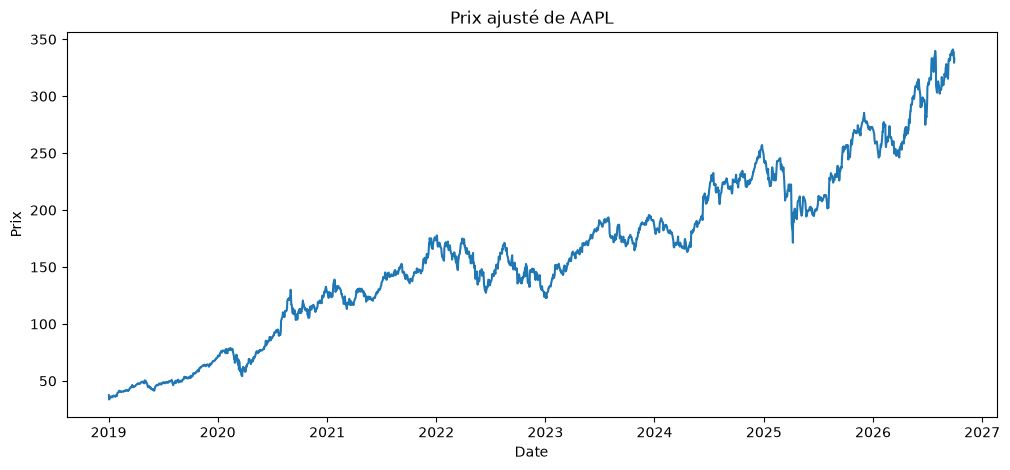

In [16]:
plt.figure(figsize=(12, 5))
plt.plot(prices["AAPL"])
plt.title("Prix ajusté de AAPL")
plt.xlabel("Date")
plt.ylabel("Prix")
plt.show()

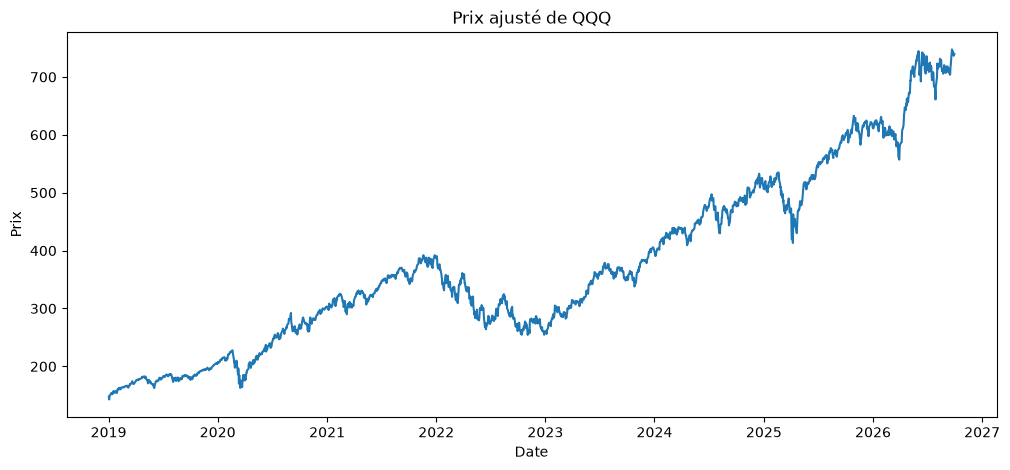

In [17]:
plt.figure(figsize=(12, 5))
plt.plot(prices["QQQ"])
plt.title("Prix ajusté de QQQ")
plt.xlabel("Date")
plt.ylabel("Prix")
plt.show()

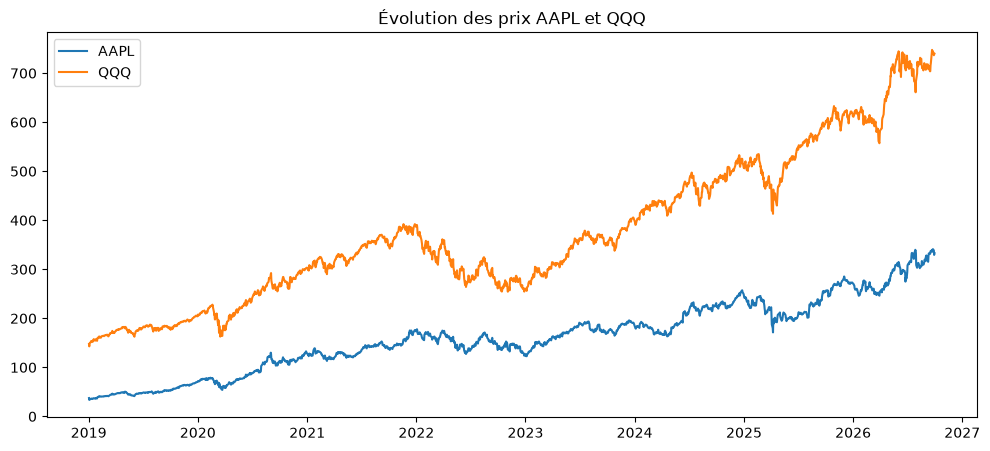

In [18]:
plt.figure(figsize=(12, 5))
plt.plot(prices["AAPL"], label="AAPL")
plt.plot(prices["QQQ"], label="QQQ")
plt.title("Évolution des prix AAPL et QQQ")
plt.legend()
plt.show()

## Créer les rendements logarithmiques
rt​=ln(Pt​/Pt−1​)

In [19]:
returns = np.log(prices / prices.shift(1))

In [20]:
returns = returns.dropna()

In [21]:
returns.head()

Ticker,AAPL,QQQ
Date,,
2019-01-03,-0.104924,-0.033216
2019-01-04,0.041803,0.041894
2019-01-07,-0.002228,0.011836
2019-01-08,0.018883,0.009005
2019-01-09,0.016839,0.008116


## Visualiser les rendements

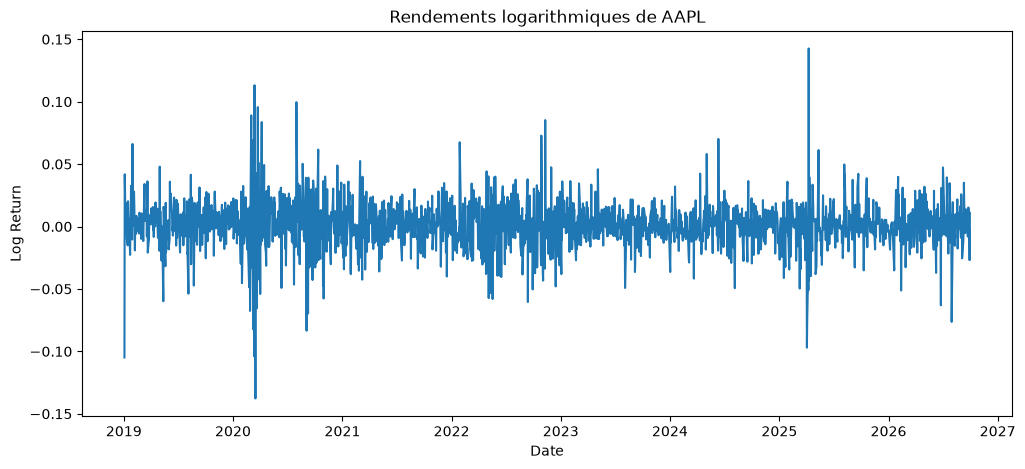

In [22]:
plt.figure(figsize=(12, 5))
plt.plot(returns["AAPL"])
plt.title("Rendements logarithmiques de AAPL")
plt.xlabel("Date")
plt.ylabel("Log Return")
plt.show()

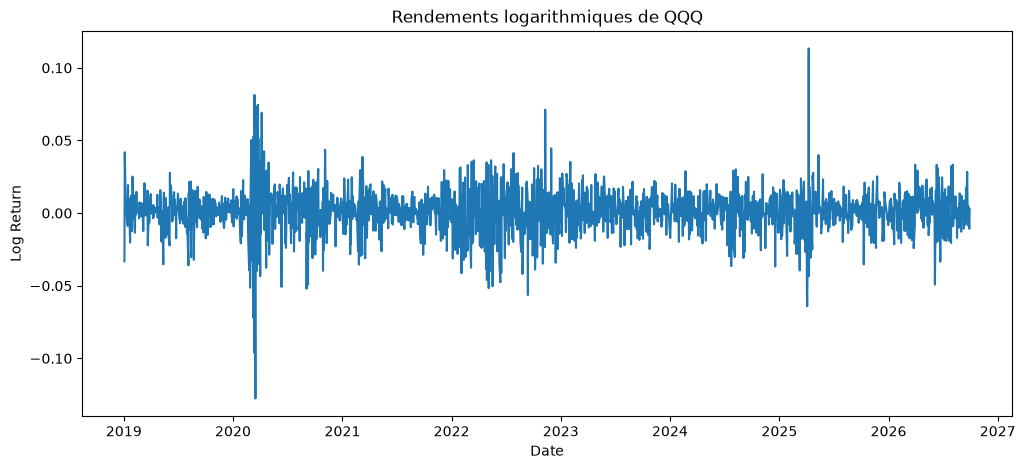

In [23]:
plt.figure(figsize=(12, 5))
plt.plot(returns["QQQ"])
plt.title("Rendements logarithmiques de QQQ")
plt.xlabel("Date")
plt.ylabel("Log Return")
plt.show()

## Créer un indicateur technique

In [24]:
prices["AAPL_MA20"] = prices["AAPL"].rolling(20).mean()

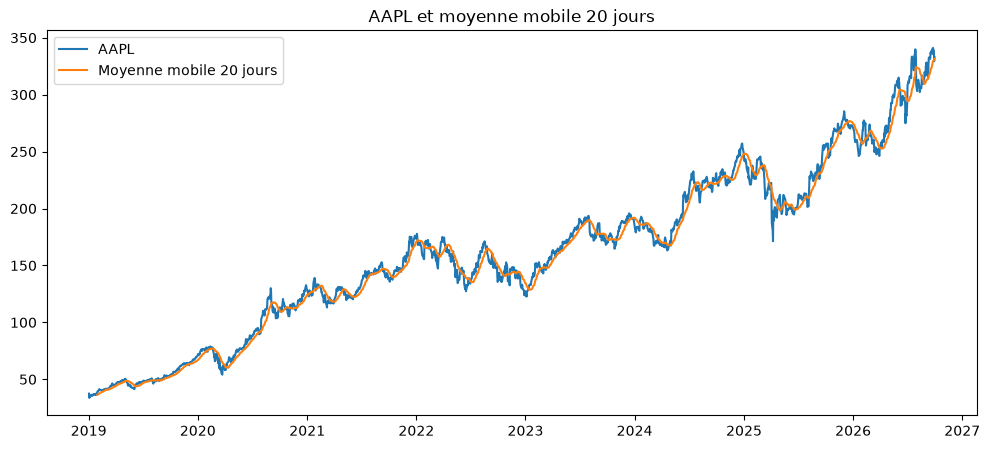

In [25]:
plt.figure(figsize=(12, 5))

plt.plot(prices["AAPL"], label="AAPL")
plt.plot(prices["AAPL_MA20"], label="Moyenne mobile 20 jours")

plt.title("AAPL et moyenne mobile 20 jours")
plt.legend()
plt.show()

## Créer la volatilité réalisée

In [26]:
rolling_volatility = returns["AAPL"].rolling(20).std()

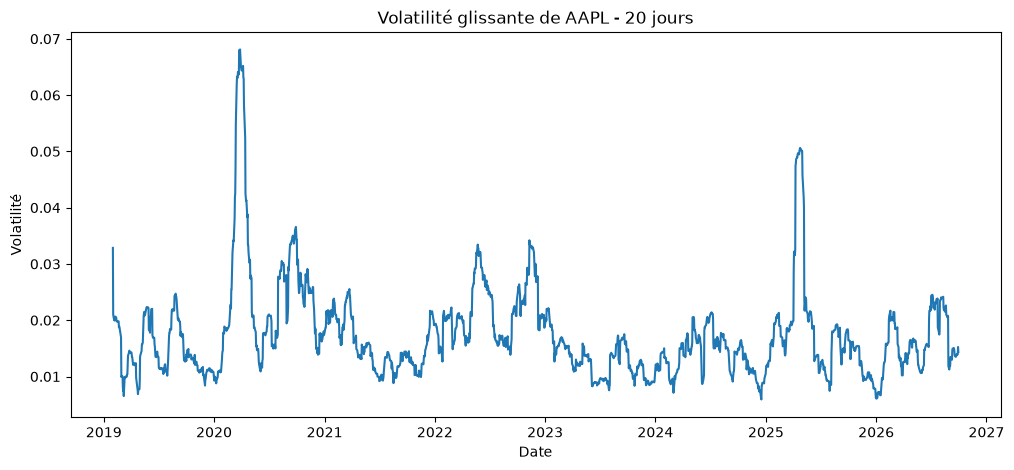

In [27]:
plt.figure(figsize=(12, 5))
plt.plot(rolling_volatility)
plt.title("Volatilité glissante de AAPL - 20 jours")
plt.xlabel("Date")
plt.ylabel("Volatilité")
plt.show()

## Statistiques descriptives

In [28]:
returns["AAPL"].describe()

count    1946.000000
mean        0.001123
std         0.019309
min        -0.137708
25%        -0.007782
50%         0.001301
75%         0.011201
max         0.142617
Name: AAPL, dtype: float64

In [29]:
returns["QQQ"].describe()

count    1946.000000
mean        0.000828
std         0.015073
min        -0.127593
25%        -0.006139
50%         0.001404
75%         0.008745
max         0.113356
Name: QQQ, dtype: float64

In [30]:
print("Skewness AAPL :", returns["AAPL"].skew())
print("Kurtosis AAPL :", returns["AAPL"].kurtosis())

print("Skewness QQQ :", returns["QQQ"].skew())
print("Kurtosis QQQ :", returns["QQQ"].kurtosis())

Skewness AAPL : -0.12014651307519171
Kurtosis AAPL : 6.507926991385197
Skewness QQQ : -0.3657391658722509
Kurtosis QQQ : 7.279897515686766


## Détection des valeurs aberrantes

### Traitement des valeurs aberrantes

Les valeurs extrêmes détectées dans les rendements AAPL et QQQ sont conservées.
Dans le contexte financier, elles peuvent correspondre à de véritables mouvements
du marché et représentent une information importante pour l'analyse de la volatilité.
Une suppression automatique pourrait donc entraîner une perte d'information.

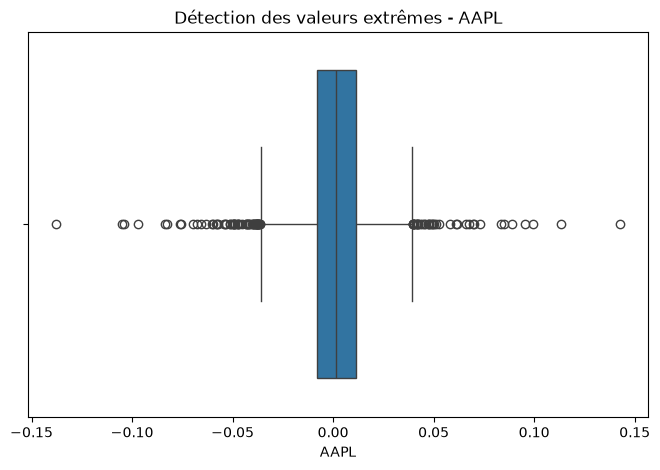

In [31]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=returns["AAPL"])
plt.title("Détection des valeurs extrêmes - AAPL")
plt.show()

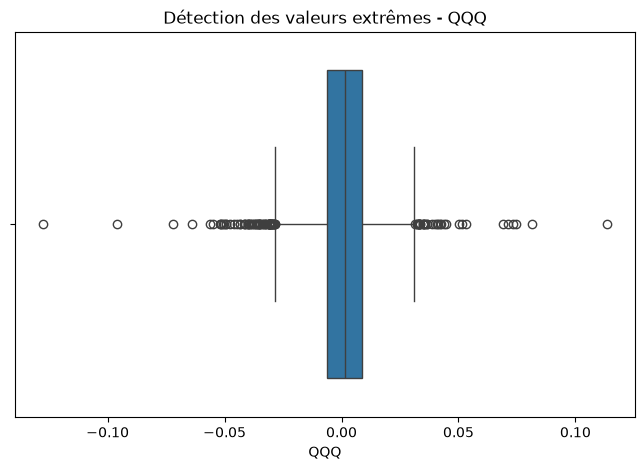

In [32]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=returns["QQQ"])
plt.title("Détection des valeurs extrêmes - QQQ")
plt.show()

In [33]:
dataset = pd.DataFrame({
    "AAPL": prices["AAPL"],
    "QQQ": prices["QQQ"],
    "AAPL_Return": returns["AAPL"],
    "QQQ_Return": returns["QQQ"],
    "AAPL_MA20": prices["AAPL_MA20"],
    "AAPL_Volatility20": rolling_volatility
})

In [34]:
dataset.head()

,AAPL,QQQ,AAPL_Return,QQQ_Return,AAPL_MA20,AAPL_Volatility20
Date,,,,,,
2019-01-02,37.436913,147.724442,NaN,NaN,NaN,NaN
2019-01-03,33.707916,142.898224,-0.104924,-0.033216,NaN,NaN
2019-01-04,35.146893,149.011993,0.041803,0.041894,NaN,NaN
2019-01-07,35.068668,150.786118,-0.002228,0.011836,NaN,NaN
2019-01-08,35.737175,152.150055,0.018883,0.009005,NaN,NaN


In [35]:
dataset.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1947 entries, 2019-01-02 to 2026-09-30
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   AAPL               1947 non-null   float64
 1   QQQ                1947 non-null   float64
 2   AAPL_Return        1946 non-null   float64
 3   QQQ_Return         1946 non-null   float64
 4   AAPL_MA20          1928 non-null   float64
 5   AAPL_Volatility20  1927 non-null   float64
dtypes: float64(6)
memory usage: 106.5 KB


In [36]:
split_index = int(len(dataset) * 0.90)

train = dataset.iloc[:split_index].copy()
test = dataset.iloc[split_index:].copy()

In [37]:
print("Train :", len(train))
print("Test :", len(test))

Train : 1752
Test : 195


In [38]:
print("Train jusqu'à :", train.index[-1])
print("Test à partir de :", test.index[0])

Train jusqu'à : 2025-12-18 00:00:00
Test à partir de : 2025-12-19 00:00:00


## ACF et PACF

In [39]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

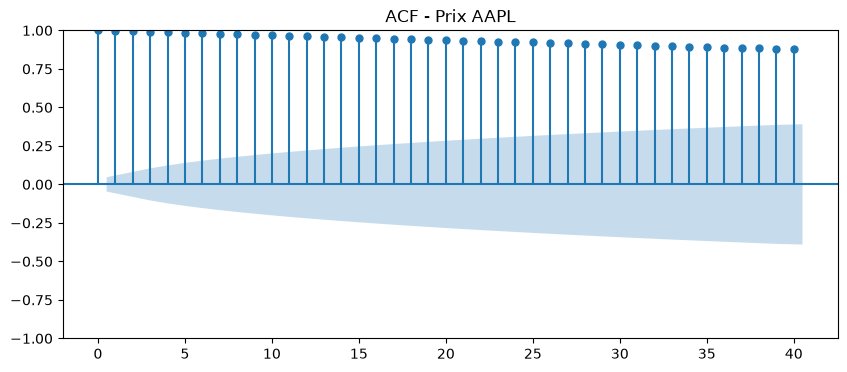

In [40]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(train["AAPL"].dropna(), ax=ax, lags=40)
plt.title("ACF - Prix AAPL")
plt.show()

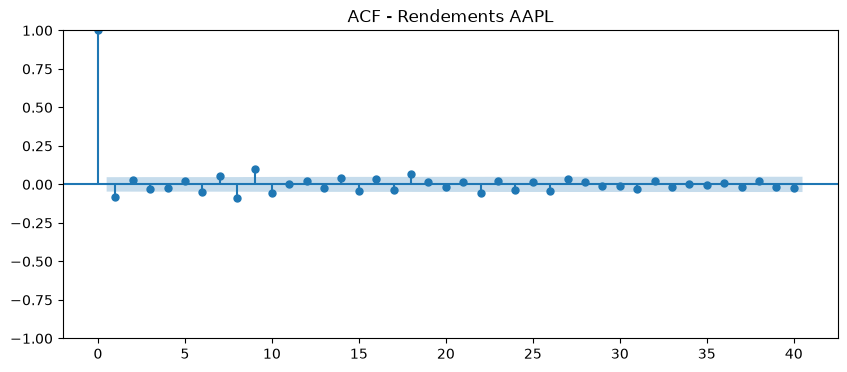

In [41]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(train["AAPL_Return"].dropna(), ax=ax, lags=40)
plt.title("ACF - Rendements AAPL")
plt.show()

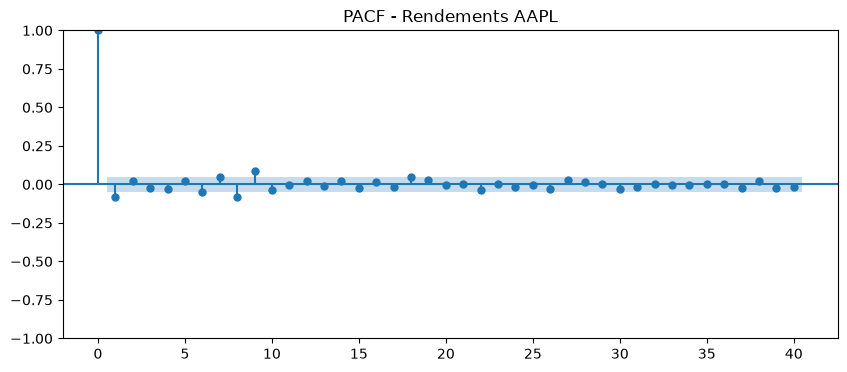

In [42]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_pacf(train["AAPL_Return"].dropna(), ax=ax, lags=40)
plt.title("PACF - Rendements AAPL")
plt.show()

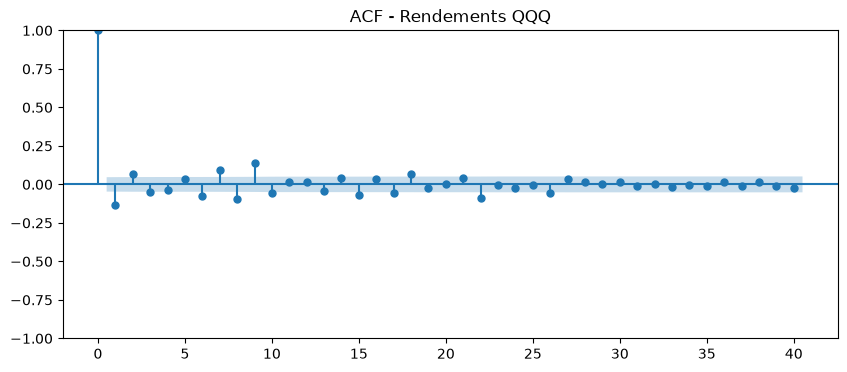

In [43]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(train["QQQ_Return"].dropna(), ax=ax, lags=40)
plt.title("ACF - Rendements QQQ")
plt.show()

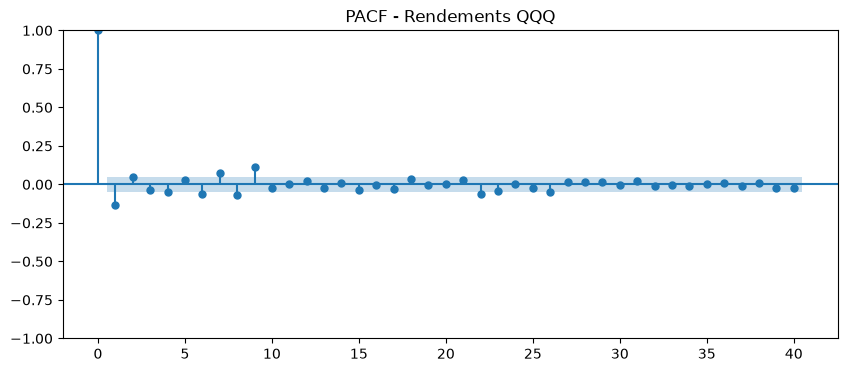

In [44]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_pacf(train["QQQ_Return"].dropna(), ax=ax, lags=40)
plt.title("PACF - Rendements QQQ")
plt.show()

## Test ADF

In [45]:
def adf_test(series, name):
    result = adfuller(series.dropna())

    print("Série :", name)
    print("ADF Statistic :", result[0])
    print("p-value :", result[1])

    if result[1] < 0.05:
        print("Conclusion : série stationnaire")
    else:
        print("Conclusion : série non stationnaire")

In [46]:
adf_test(train["AAPL"], "AAPL Prix")
adf_test(train["AAPL_Return"], "AAPL Rendement")

Série : AAPL Prix
ADF Statistic : -0.7299181311273198
p-value : 0.8388471425469184
Conclusion : série non stationnaire
Série : AAPL Rendement
ADF Statistic : -13.575303849272336
p-value : 2.1753845186143523e-25
Conclusion : série stationnaire


In [47]:
adf_test(train["QQQ"], "QQQ Prix")
adf_test(train["QQQ_Return"], "QQQ Rendement")

Série : QQQ Prix
ADF Statistic : 0.0065359879963267165
p-value : 0.9590692815353322
Conclusion : série non stationnaire
Série : QQQ Rendement
ADF Statistic : -13.206375304901185
p-value : 1.0687744853615066e-24
Conclusion : série stationnaire


## Test KPSS

In [48]:
from statsmodels.tsa.stattools import kpss

In [49]:
def kpss_test(series, name):
    result = kpss(series.dropna(), regression="c", nlags="auto")

    print("Série :", name)
    print("KPSS Statistic :", result[0])
    print("p-value :", result[1])

    if result[1] < 0.05:
        print("Conclusion : série non stationnaire")
    else:
        print("Conclusion : série stationnaire")

In [50]:
kpss_test(train["AAPL"], "AAPL Prix")
kpss_test(train["AAPL_Return"], "AAPL Rendement")

Série : AAPL Prix
KPSS Statistic : 5.997606459349766
p-value : 0.01
Conclusion : série non stationnaire
Série : AAPL Rendement
KPSS Statistic : 0.21350722988053478
p-value : 0.1
Conclusion : série stationnaire


In [51]:
kpss_test(train["QQQ"], "QQQ Prix")
kpss_test(train["QQQ_Return"], "QQQ Rendement")

Série : QQQ Prix
KPSS Statistic : 5.49123691052457
p-value : 0.01
Conclusion : série non stationnaire
Série : QQQ Rendement
KPSS Statistic : 0.09026936184149448
p-value : 0.1
Conclusion : série stationnaire


## la décomposition
Pour les prix financiers, la saisonnalité classique est moins évidente, donc on peut faire une décomposition sur les rendements AAPL.

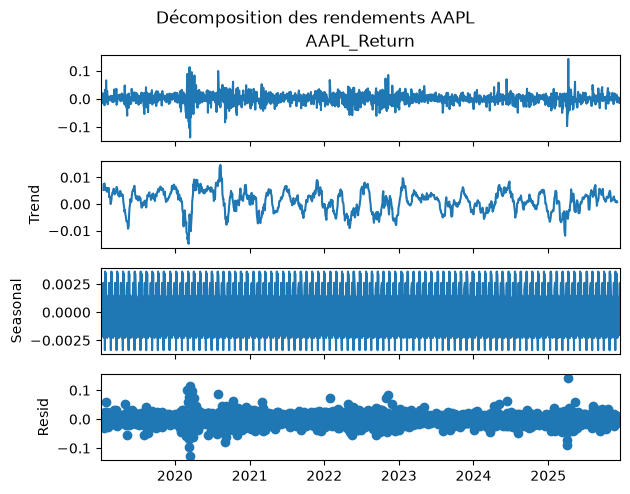

In [52]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    train["AAPL_Return"].dropna(),
    model="additive",
    period=20
)

decomposition.plot()
plt.suptitle("Décomposition des rendements AAPL", y=1.02)
plt.show()

## analyser les ruptures / changements de régime

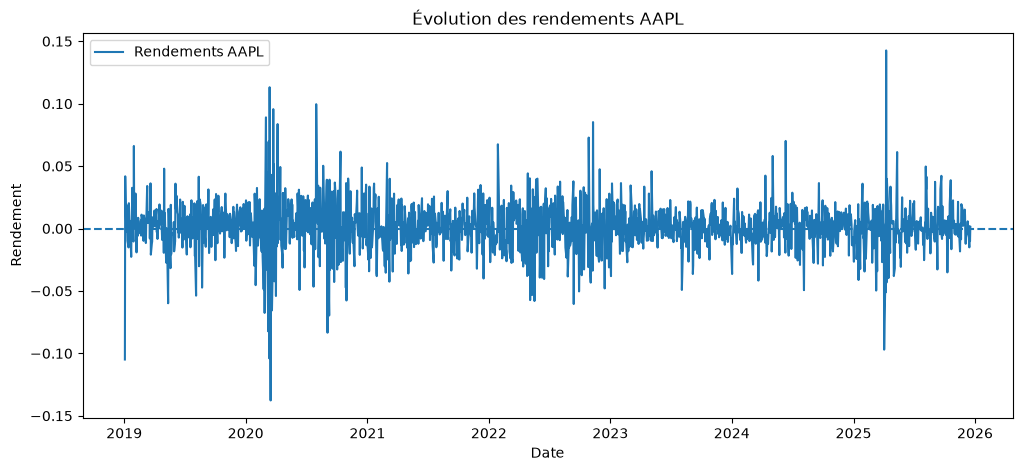

In [53]:
plt.figure(figsize=(12, 5))

plt.plot(train["AAPL_Return"], label="Rendements AAPL")
plt.axhline(0, linestyle="--")

plt.title("Évolution des rendements AAPL")
plt.xlabel("Date")
plt.ylabel("Rendement")
plt.legend()
plt.show()

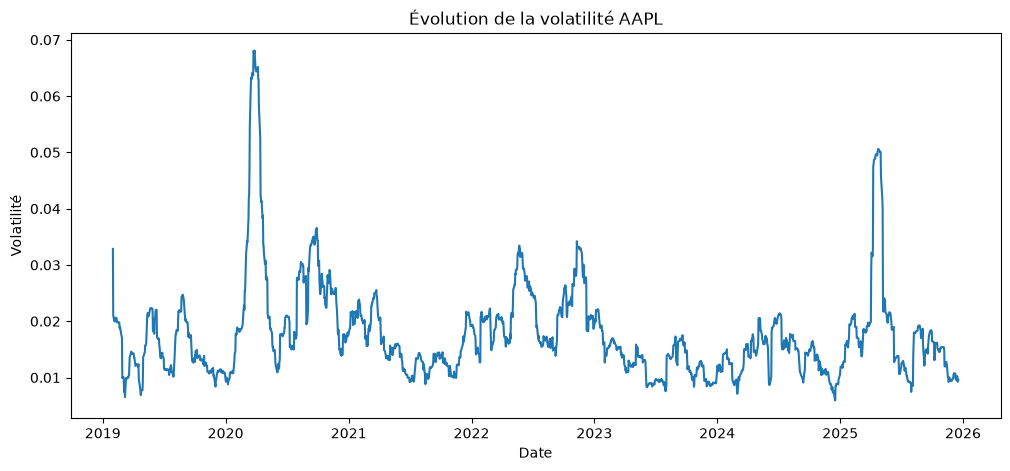

In [54]:
plt.figure(figsize=(12, 5))

plt.plot(train["AAPL_Volatility20"])

plt.title("Évolution de la volatilité AAPL")
plt.xlabel("Date")
plt.ylabel("Volatilité")

plt.show()

## Modèle ARIMA - Identification des paramètres

In [55]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import jarque_bera

In [57]:
from pmdarima import auto_arima

arima_auto = auto_arima(
    train["AAPL"],
    seasonal=False,
    stepwise=True,
    suppress_warnings=True,
    error_action="ignore",
    trace=True
)

print(arima_auto.summary())

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=8558.391, Time=0.69 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=8555.036, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=8556.487, Time=0.08 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=8556.509, Time=0.08 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=8557.075, Time=0.02 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=8559.012, Time=0.16 sec

Best model:  ARIMA(0,1,0)(0,0,0)[0] intercept
Total fit time: 1.076 seconds
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1752
Model:               SARIMAX(0, 1, 0)   Log Likelihood               -4275.518
Date:                Tue, 13 Oct 2026   AIC                           8555.036
Time:                        10:06:10   BIC                           8565.972
Sample:                             0   HQIC                          8559.079
          

In [58]:
print("Ordre ARIMA choisi :", arima_auto.order)

Ordre ARIMA choisi : (0, 1, 0)


## Estimation du modèle ARIMA

In [59]:
p, d, q = arima_auto.order

model_arima = ARIMA(
    train["AAPL"],
    order=(p, d, q)
)

arima_result = model_arima.fit()

print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:                   AAPL   No. Observations:                 1752
Model:                 ARIMA(0, 1, 0)   Log Likelihood               -4277.538
Date:                Tue, 13 Oct 2026   AIC                           8557.075
Time:                        10:06:19   BIC                           8562.543
Sample:                             0   HQIC                          8559.097
                               - 1752                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2         7.7519      0.115     67.404      0.000       7.527       7.977
Ljung-Box (L1) (Q):                   0.55   Jarque-Bera (JB):              5140.78
Prob(Q):                              0.46   Pr

## Diagnostic des résidus ARIMA

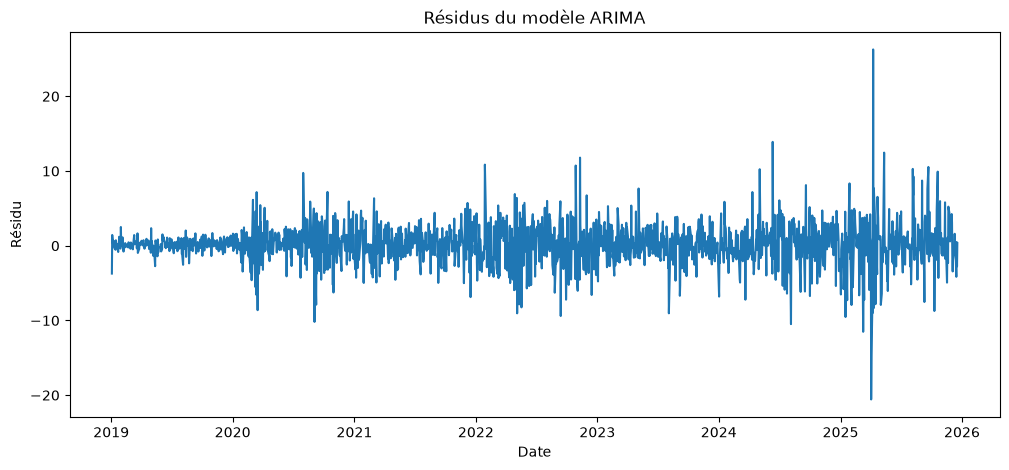

In [60]:
residuals_arima = arima_result.resid.iloc[1:].dropna()

plt.figure(figsize=(12, 5))
plt.plot(residuals_arima)
plt.title("Résidus du modèle ARIMA")
plt.xlabel("Date")
plt.ylabel("Résidu")
plt.show()

In [61]:
#test de Ljung-Box
ljung_box = acorr_ljungbox(
    residuals_arima.dropna(),
    lags=[10, 20],
    return_df=True
)

print(ljung_box)

      lb_stat  lb_pvalue
10  17.419984   0.065572
20  29.966638   0.070396


In [62]:
#Normalité des résidus
jb_stat, jb_pvalue = jarque_bera(residuals_arima.dropna())

print("Jarque-Bera statistic :", jb_stat)
print("p-value :", jb_pvalue)

Jarque-Bera statistic : 5140.775318984035
p-value : 0.0


In [63]:
#ARCH-LM
#vérifier l'hétéroscédasticité.
from statsmodels.stats.diagnostic import het_arch

In [64]:
arch_test = het_arch(residuals_arima.dropna())

print("ARCH-LM statistic :", arch_test[0])
print("p-value :", arch_test[1])

ARCH-LM statistic : 257.96579015020984
p-value : 1.1453277562475652e-49


## Modèle VAR - AAPL et QQQ

In [65]:
from statsmodels.tsa.api import VAR

In [66]:
var_data = train[["AAPL_Return", "QQQ_Return"]].dropna()

print(var_data.head())
print(var_data.shape)

            AAPL_Return  QQQ_Return
Date                               
2019-01-03    -0.104924   -0.033216
2019-01-04     0.041803    0.041894
2019-01-07    -0.002228    0.011836
2019-01-08     0.018883    0.009005
2019-01-09     0.016839    0.008116
(1751, 2)


In [67]:
var_model = VAR(var_data)

lag_selection = var_model.select_order(maxlags=20)

print(lag_selection.summary())

 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -17.37      -17.36   2.872e-08      -17.36
1       -17.38     -17.36*   2.820e-08     -17.38*
2       -17.38      -17.35   2.819e-08      -17.37
3       -17.39      -17.34   2.817e-08      -17.37
4       -17.39      -17.33   2.813e-08      -17.37
5       -17.38      -17.32   2.817e-08      -17.36
6       -17.38      -17.30   2.820e-08      -17.35
7       -17.39      -17.29   2.808e-08      -17.35
8       -17.39      -17.28   2.806e-08      -17.35
9      -17.40*      -17.28  2.779e-08*      -17.35
10      -17.40      -17.26   2.788e-08      -17.35
11      -17.39      -17.25   2.798e-08      -17.34
12      -17.39      -17.23   2.808e-08      -17.33
13      -17.39      -17.22   2.813e-08      -17.32
14      -17.38      -17.20   2.825e-08      -17.31
15      -17.38      -17.18   2.834e-08      -17.31
16      -17.38      -17.17   2.

In [68]:
print("Lag choisi par AIC :", lag_selection.aic)
print("Lag choisi par BIC :", lag_selection.bic)
print("Lag choisi par HQIC :", lag_selection.hqic)

Lag choisi par AIC : 9
Lag choisi par BIC : 1
Lag choisi par HQIC : 1


In [69]:
var_result = var_model.fit(lag_selection.aic)

print(var_result.summary())

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Tue, 13, Oct, 2026
Time:                     10:06:42
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                   -17.2761
Nobs:                     1742.00    HQIC:                  -17.3512
Log likelihood:           10245.7    FPE:                2.78834e-08
AIC:                     -17.3952    Det(Omega_mle):     2.72850e-08
--------------------------------------------------------------------
Results for equation AAPL_Return
                    coefficient       std. error           t-stat            prob
---------------------------------------------------------------------------------
const                  0.001204         0.000467            2.577           0.010
L1.AAPL_Return         0.011501         0.041630            0.276           0.782
L1.QQQ_Return         -0.106175         0.053164  

In [70]:
print("Stabilité du VAR :", var_result.is_stable())

Stabilité du VAR : True


In [71]:
granger_aapl_qqq = var_result.test_causality(
    "QQQ_Return",
    ["AAPL_Return"],
    kind="f"
)

print(granger_aapl_qqq.summary())

Granger causality F-test. H_0: AAPL_Return does not Granger-cause QQQ_Return. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value          df        
---------------------------------------------------------
         1.096          1.883   0.362 (9, np.int64(3446))
---------------------------------------------------------


In [72]:
granger_qqq_aapl = var_result.test_causality(
    "AAPL_Return",
    ["QQQ_Return"],
    kind="f"
)

print(granger_qqq_aapl.summary())

Granger causality F-test. H_0: QQQ_Return does not Granger-cause AAPL_Return. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value          df        
---------------------------------------------------------
         3.109          1.883   0.001 (9, np.int64(3446))
---------------------------------------------------------


## Cointegration

In [73]:
from statsmodels.tsa.vector_ar.vecm import coint_johansen

In [74]:
log_prices = np.log(train[["AAPL", "QQQ"]].dropna())

johansen_result = coint_johansen(
    log_prices,
    det_order=0,
    k_ar_diff=1
)

print("Trace statistics :")
print(johansen_result.lr1)

print("\nCritical values à 5 % :")
print(johansen_result.cvt[:, 1])

Trace statistics :
[10.85528378  0.48521532]

Critical values à 5 % :
[15.4943  3.8415]


## ARCH / GARCH

In [76]:
from arch import arch_model

In [77]:
returns_aapl = train["AAPL_Return"].dropna() * 100

garch_model = arch_model(
    returns_aapl,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1
)

garch_result = garch_model.fit(disp="off")

print(garch_result.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:            AAPL_Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -3460.85
Distribution:                  Normal   AIC:                           6929.70
Method:            Maximum Likelihood   BIC:                           6951.57
                                        No. Observations:                 1751
Date:                Tue, Oct 13 2026   Df Residuals:                     1750
Time:                        10:07:48   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.1753  4.105e-02      4.271  1.943e-05 [9.487e-0

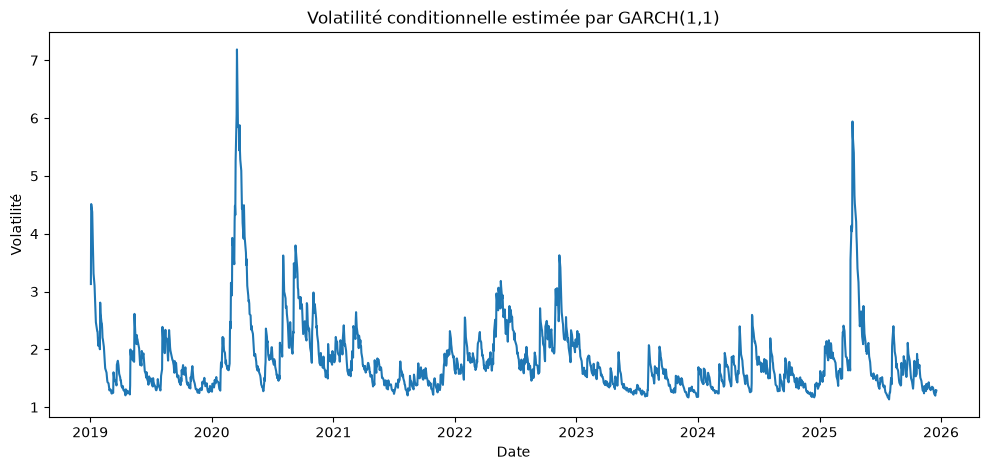

In [78]:
plt.figure(figsize=(12, 5))

plt.plot(
    garch_result.conditional_volatility
)

plt.title("Volatilité conditionnelle estimée par GARCH(1,1)")
plt.xlabel("Date")
plt.ylabel("Volatilité")

plt.show()

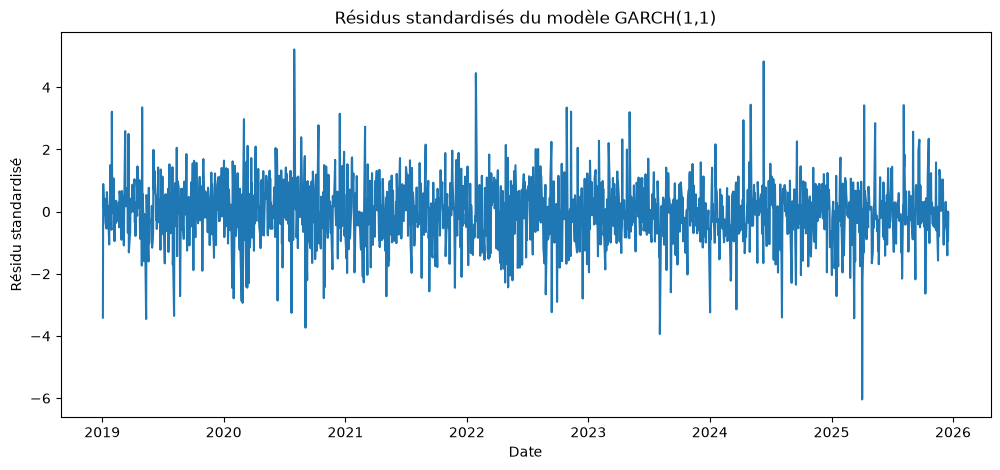

In [79]:
standardized_residuals = garch_result.std_resid.dropna()

plt.figure(figsize=(12, 5))

plt.plot(standardized_residuals)

plt.title("Résidus standardisés du modèle GARCH(1,1)")
plt.xlabel("Date")
plt.ylabel("Résidu standardisé")

plt.show()

In [80]:
lb_garch = acorr_ljungbox(
    standardized_residuals,
    lags=[10, 20],
    return_df=True
)

print(lb_garch)

      lb_stat  lb_pvalue
10   7.015702   0.723962
20  16.095493   0.710683


In [81]:
from statsmodels.stats.diagnostic import het_arch

arch_garch = het_arch(standardized_residuals)

print("ARCH-LM statistic :", arch_garch[0])
print("p-value :", arch_garch[1])

ARCH-LM statistic : 8.653587564236508
p-value : 0.565264264092998


In [82]:
jb_garch = jarque_bera(standardized_residuals)

print("Jarque-Bera statistic :", jb_garch.statistic)
print("p-value :", jb_garch.pvalue)

Jarque-Bera statistic : 466.2997505052695
p-value : 5.550034992857804e-102


# Mini-Projet Séries Temporelles — Parties 4 et 5
## Modélisation avancée (LSTM / GRU / hybride) et IA générative — AAPL & QQQ

Ce notebook **prolonge le travail de l'équipe** (sections 1 → 3.3 : exploration, ADF/KPSS, ARIMA, VAR, Granger, Johansen, GARCH) et couvre :

| Section | Contenu | Barème |
|---|---|---|
| **4.1** | LSTM et GRU, fenêtres glissantes, normalisation sans fuite, courbes de perte, **validation walk-forward** | Bloc B |
| **4.2** | Approche **hybride** GARCH → réseau de neurones (étude d'ablation) | Bloc D |
| **4.4** | Comparaison rigoureuse classique vs avancé (RMSE, MAE, MAPE, **test de Diebold-Mariano**) | Bloc B |
| **5** | IA générative : hypothèses, vulgarisation, recommandations avec limites, comparaison humain/LLM | Bloc C |

**Comment l'exécuter** : *Kernel → Restart & Run All*. Aucune intervention manuelle n'est nécessaire.
Pour un test rapide (≈ 1 min) mettre `QUICK_RUN = True` dans la cellule de configuration.
**Si ces cellules sont collées à la suite du notebook de l'équipe**, ne pas exécuter la cellule « Étape 0b — rechargement des données » (les variables `dataset`, `train`, `test` existent déjà).

#Partie 4 et 5

## Étape 0 — Configuration, reproductibilité et reprise des données de l'équipe

In [128]:
# === Configuration & imports ==========================================================
# Pourquoi en premier : tout ce qui conditionne la reproductibilité (graine, versions, chemins, hyper-paramètres)
# est centralisé ici pour qu'un correcteur puisse relancer l'étude à l'identique.
import os, re, json, time, warnings, platform
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"      # moins de messages TensorFlow
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"      # calculs plus reproductibles d'une machine à l'autre
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
from scipy import stats

import statsmodels, scipy, sklearn
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from scipy.stats import jarque_bera
from sklearn.model_selection import TimeSeriesSplit
from arch import arch_model
import arch as arch_pkg

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ---- Paramètres généraux (modifiables) -----------------------------------------------
QUICK_RUN = False                      # True = test rapide (3 époques, 2 plis, 1 graine) : ne sert qu'à vérifier que tout tourne
SEED      = 42                         # graine unique → résultats reproductibles
CSV_PATH  = "../data/data_aapl_qqq.csv"   # même fichier que l'équipe (yf.download(...).to_csv)
OUT_DIR   = "../outputs"               # tableaux de résultats (réutilisables pour la partie 6)
LLM_DIR   = "../llm"                   # prompts et réponses des LLM (partie 5)
for d in (OUT_DIR, LLM_DIR): os.makedirs(d, exist_ok=True)

# ---- Hyper-paramètres des réseaux (justifiés dans la section 4.1) ---------------------
CFG = dict(
    windows=[10, 20],      # 10 j couvre les lags significatifs 7-9 vus dans l'ACF/VAR ; 20 j ≈ 1 mois de bourse (= fenêtre de la volatilité)
    units=[16, 32],        # petits réseaux : ~1 700 observations seulement → risque de surapprentissage
    dropout=0.2, lr=1e-3, batch=32,
    max_epochs=80, patience=8, val_frac=0.15,
    cv_splits=4, cv_test_size=200,     # 4 plis walk-forward de 200 jours (≈ 10 mois) chacun
    n_seeds=3)                          # moyenne de 3 initialisations → réduit la variance d'entraînement
if QUICK_RUN:
    CFG.update(windows=[10], units=[16], max_epochs=3, patience=2, cv_splits=2, cv_test_size=120, n_seeds=1)

tf.get_logger().setLevel("ERROR")
np.random.seed(SEED); keras.utils.set_random_seed(SEED)
try: tf.config.experimental.enable_op_determinism()
except Exception: pass
sns.set_theme(style="whitegrid"); plt.rcParams["figure.figsize"] = (12, 4.5)

print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| statsmodels", statsmodels.__version__, "| arch", arch_pkg.__version__,
      "| scikit-learn", sklearn.__version__, "| tensorflow", tf.__version__, "| keras", keras.__version__)
print("QUICK_RUN =", QUICK_RUN, "|", CFG)

Python 3.13.0 | numpy 2.5.4 | pandas 3.0.6 | statsmodels 0.15.0 | arch 8.0.0 | scikit-learn 1.9.1 | tensorflow 2.21.0 | keras 3.15.1
QUICK_RUN = False | {'windows': [10, 20], 'units': [16, 32], 'dropout': 0.2, 'lr': 0.001, 'batch': 32, 'max_epochs': 80, 'patience': 8, 'val_frac': 0.15, 'cv_splits': 4, 'cv_test_size': 200, 'n_seeds': 3}


In [129]:
# === Étape 0b — rechargement des données de l'équipe ==================================
# Pourquoi : rendre ce notebook exécutable seul, en reconstruisant EXACTEMENT les objets de l'équipe
# (mêmes formules : rendement log, MA20, volatilité 20 j, split chronologique 90/10).
def load_prices(csv_path=CSV_PATH):
    """Lit le CSV écrit par yf.download(...).to_csv (3 lignes d'en-tête : Price / Ticker / Date)."""
    if os.path.exists(csv_path):
        raw = pd.read_csv(csv_path, header=[0, 1], index_col=0)
        raw.index = pd.to_datetime(raw.index, errors="coerce")
        raw = raw[raw.index.notna()].astype(float)      # supprime la ligne parasite « Date »
        px, src = raw["Adj Close"], f"CSV local : {csv_path}"
    else:                                               # repli : même appel que l'équipe
        import yfinance as yf
        data = yf.download(["AAPL", "QQQ"], start="2019-01-01", end="2026-10-01", auto_adjust=False, progress=False)
        px, src = data["Adj Close"], "yfinance (téléchargement direct)"
    return px[["AAPL", "QQQ"]].sort_index(), src

prices, source = load_prices()
assert prices.index.is_monotonic_increasing and not prices.index.duplicated().any() and not prices.isna().any().any()
returns = np.log(prices / prices.shift(1)).dropna()                      # r_t = ln(P_t / P_{t-1})
dataset = pd.DataFrame({
    "AAPL": prices["AAPL"], "QQQ": prices["QQQ"],
    "AAPL_Return": returns["AAPL"], "QQQ_Return": returns["QQQ"],
    "AAPL_MA20": prices["AAPL"].rolling(20).mean(),
    "AAPL_Volatility20": returns["AAPL"].rolling(20).std()})
split_index = int(len(dataset) * 0.90)                                   # split CHRONOLOGIQUE (jamais aléatoire)
train, test = dataset.iloc[:split_index].copy(), dataset.iloc[split_index:].copy()

print("Source :", source)
print(f"Période : {dataset.index[0].date()} → {dataset.index[-1].date()} | n = {len(dataset)} | train = {len(train)} | test = {len(test)}")
print(f"Train jusqu'au {train.index[-1].date()} | test à partir du {test.index[0].date()}")
print("✔ identique au notebook de l'équipe (1947 / 1752 / 195)" if (len(dataset), len(train), len(test)) == (1947, 1752, 195)
      else "⚠ dimensions différentes de celles du notebook de l'équipe (1947 / 1752 / 195) : vérifier le fichier CSV")

Source : CSV local : ../data/data_aapl_qqq.csv
Période : 2019-01-02 → 2026-09-30 | n = 1947 | train = 1752 | test = 195
Train jusqu'au 2025-12-18 | test à partir du 2025-12-19
✔ identique au notebook de l'équipe (1947 / 1752 / 195)


### Étape 0c — Rappel des résultats de l'équipe (recalculés ici)

**Pourquoi recalculer ?** (1) Ce notebook reste autonome. (2) Les résultats des sections 1-3.3 **justifient les choix de la partie 4**
(quelles entrées donner au réseau ? faut-il modéliser les rendements ou les prix ? faut-il une entrée de volatilité ?)
et **alimentent les prompts de la partie 5** avec des chiffres réels (et non retapés à la main → pas d'erreur de recopie).
Aucun nouveau choix de modèle n'est fait ici : ARIMA(0,1,0) et GARCH(1,1) sont ceux retenus par l'équipe.

In [130]:
def recap_classique(train, dataset):
    """Recalcule les résultats clés des sections 2 à 3.3 (échantillon d'APPRENTISSAGE uniquement)."""
    R = {}
    # -- Stationnarité (ADF H0 = racine unitaire ; KPSS H0 = stationnarité : hypothèses opposées → tests complémentaires)
    rows = []
    for col, nm in [("AAPL", "AAPL prix"), ("QQQ", "QQQ prix"), ("AAPL_Return", "AAPL rendement"), ("QQQ_Return", "QQQ rendement")]:
        s = train[col].dropna(); a = adfuller(s); k = kpss(s, regression="c", nlags="auto")
        rows.append(dict(serie=nm, adf_stat=a[0], adf_p=a[1], kpss_stat=k[0], kpss_p=k[1]))
    R["stationnarite"] = pd.DataFrame(rows).set_index("serie")
    # -- ARIMA(0,1,0) retenu par auto_arima (équipe) + diagnostic des résidus
    arima_res = ARIMA(train["AAPL"].values, order=(0, 1, 0)).fit()
    e = pd.Series(arima_res.resid[1:])
    lb = acorr_ljungbox(e, lags=[10, 20], return_df=True); jb = jarque_bera(e); ar = het_arch(e)
    R["arima"] = dict(aic=arima_res.aic, lb10_p=lb.loc[10, "lb_pvalue"], lb20_p=lb.loc[20, "lb_pvalue"],
                      jb_stat=jb[0], jb_p=jb[1], archlm_stat=ar[0], archlm_p=ar[1])
    # -- VAR sur les rendements + causalité de Granger
    var_model = VAR(train[["AAPL_Return", "QQQ_Return"]].dropna())
    sel = var_model.select_order(maxlags=20); p_aic = sel.selected_orders["aic"]; p_bic = sel.selected_orders["bic"]
    var_res = var_model.fit(p_aic)
    g_q2a = var_res.test_causality("AAPL_Return", ["QQQ_Return"], kind="f")   # H0 : QQQ ne cause pas AAPL
    g_a2q = var_res.test_causality("QQQ_Return", ["AAPL_Return"], kind="f")   # H0 : AAPL ne cause pas QQQ
    R["var"] = dict(lag_aic=int(p_aic), lag_bic=int(p_bic), stable=bool(var_res.is_stable()),
                    corr_resid=float(var_res.resid.corr().iloc[0, 1]),
                    granger_qqq_to_aapl=(g_q2a.test_statistic, g_q2a.pvalue),
                    granger_aapl_to_qqq=(g_a2q.test_statistic, g_a2q.pvalue))
    # -- Cointégration de Johansen sur les log-prix
    jo = coint_johansen(np.log(train[["AAPL", "QQQ"]].dropna()), det_order=0, k_ar_diff=1)
    R["johansen"] = dict(trace=jo.lr1.tolist(), crit5=jo.cvt[:, 1].tolist(), coint=bool(jo.lr1[0] > jo.cvt[0, 1]))
    # -- GARCH(1,1) sur les rendements AAPL (en %) + diagnostic des résidus standardisés
    r_pct = train["AAPL_Return"].dropna() * 100
    g = arch_model(r_pct, mean="Constant", vol="GARCH", p=1, q=1).fit(disp="off")
    z = g.std_resid.dropna(); lbg = acorr_ljungbox(z, lags=[10, 20], return_df=True); arg = het_arch(z); jbg = jarque_bera(z)
    P = g.params
    R["garch"] = dict(mu=P["mu"], omega=P["omega"], alpha=P["alpha[1]"], beta=P["beta[1]"],
                      persistence=P["alpha[1]"] + P["beta[1]"],
                      lb10_p=lbg.loc[10, "lb_pvalue"], lb20_p=lbg.loc[20, "lb_pvalue"],
                      archlm_p=arg[1], jb_stat=jbg[0], jb_p=jbg[1])
    return R, g

R, garch_res = recap_classique(train, dataset)
display(R["stationnarite"].round(4))
print("ARIMA(0,1,0)  :", {k: round(float(v), 4) for k, v in R["arima"].items()})
print("VAR           :", R["var"])
print("Johansen      :", R["johansen"])
print("GARCH(1,1)    :", {k: round(float(v), 4) for k, v in R["garch"].items()})

,adf_stat,adf_p,kpss_stat,kpss_p
serie,,,,
AAPL prix,-0.7299,0.8388,5.9976,0.01
QQQ prix,0.0065,0.9591,5.4912,0.01
AAPL rendement,-13.5753,0.0000,0.2135,0.10
QQQ rendement,-13.2064,0.0000,0.0903,0.10


ARIMA(0,1,0)  : {'aic': 8557.0755, 'lb10_p': 0.0656, 'lb20_p': 0.0704, 'jb_stat': 5140.7753, 'jb_p': 0.0, 'archlm_stat': 257.9658, 'archlm_p': 0.0}
VAR           : {'lag_aic': 9, 'lag_bic': 1, 'stable': True, 'corr_resid': 0.8154883739305452, 'granger_qqq_to_aapl': (np.float64(3.1093061332184515), np.float64(0.000991634242084141)), 'granger_aapl_to_qqq': (np.float64(1.0962332692836096), np.float64(0.3617719495454713))}
Johansen      : {'trace': [10.855283776034614, 0.4852153216052057], 'crit5': [15.4943, 3.8415], 'coint': False}
GARCH(1,1)    : {'mu': 0.1753, 'omega': 0.1577, 'alpha': 0.1044, 'beta': 0.8505, 'persistence': 0.9549, 'lb10_p': 0.724, 'lb20_p': 0.7107, 'archlm_p': 0.5653, 'jb_stat': 466.2998, 'jb_p': 0.0}


## 4.0 — Formulation du problème pour les réseaux de neurones

**Cible** : prédire le **rendement logarithmique d'AAPL du lendemain**, $r_{t+1}$, à partir des $W$ derniers jours d'observations.
Le prix prévu s'en déduit : $\hat P_{t+1} = P_t \cdot e^{\hat r_{t+1}}$.

**Pourquoi modéliser les rendements et non les prix ?**
1. **Stationnarité** — d'après ADF/KPSS de l'équipe, les prix sont non stationnaires (ADF p ≈ 0.84 / 0.96 ; KPSS rejette) alors que les rendements sont stationnaires. Un réseau apprend mal sur une série dont la moyenne dérive.
2. **Extrapolation** — un LSTM/GRU utilise des activations bornées (tanh/sigmoïde) ; si le test contient des prix **jamais vus** à l'entraînement (cas ici : l'action monte, voir cellule suivante), la normalisation min-max sort de l'intervalle [0, 1] et le réseau « plafonne ». Les rendements restent dans la même plage en train et en test.
3. **Comparabilité** — l'ARIMA(0,1,0) de l'équipe est une marche aléatoire : sa prévision est $\hat P_{t+1}=P_t$, soit $\hat r_{t+1}=0$. Même cible → comparaison équitable.

**Variables d'entrée (justifiées par les sections 3.2 et 3.3 de l'équipe)**

| Variable | Pourquoi |
|---|---|
| `AAPL_Return` | historique propre de la cible (le VAR d'ordre 9 suggère des lags jusqu'à 9) |
| `QQQ_Return` | **Granger : QQQ → AAPL significatif** (F = 3.11, p = 0.001), alors que AAPL → QQQ ne l'est pas |
| `AAPL_Volatility20` | **effets ARCH très forts** (ARCH-LM p ≈ 1e-49) : le régime de volatilité est une information utile |

**Règles anti-fuite d'information (data leakage)** : split chronologique ; normalisation avec moyenne/écart-type **du train uniquement** (et recalculés dans chaque pli de la validation croisée) ; une fenêtre ne contient que des jours ≤ $t$.

In [131]:
# Illustration du point (2) : plage des prix en train vs test
print(f"AAPL prix — max train : {train['AAPL'].max():.1f} | max test : {test['AAPL'].max():.1f}")
print(f"Rendements — écart-type train : {train['AAPL_Return'].std():.4f} | test : {test['AAPL_Return'].std():.4f}")
if test["AAPL"].max() > train["AAPL"].max():
    print("→ le test contient des prix hors de la plage d'entraînement : modéliser les PRIX avec un réseau serait biaisé ; on modélise les RENDEMENTS.")

AAPL prix — max train : 285.4 | max test : 341.1
Rendements — écart-type train : 0.0196 | test : 0.0166
→ le test contient des prix hors de la plage d'entraînement : modéliser les PRIX avec un réseau serait biaisé ; on modélise les RENDEMENTS.


In [132]:
# === Préparation : variables, fenêtres glissantes, normalisation sans fuite ===========
FEATURES_BASE = ["AAPL_Return", "QQQ_Return", "AAPL_Volatility20"]     # la colonne 0 est TOUJOURS la cible
feat = dataset[FEATURES_BASE].dropna()                                   # retire les lignes initiales sans rendement / volatilité
train_end, test_start = train.index[-1], test.index[0]
cut_final = int((feat.index <= train_end).sum())                         # nb de lignes de la période d'apprentissage
n_test = len(feat) - cut_final
print(f"lignes utilisables : {len(feat)} | apprentissage : {cut_final} | test : {n_test}")
assert n_test == len(test), "le test doit contenir tous les jours du split de l'équipe"

def fit_scaler(F, cut):
    """Moyenne / écart-type calculés sur les lignes [0:cut] SEULEMENT (= information disponible à l'époque)."""
    return F[:cut].mean(axis=0), F[:cut].std(axis=0, ddof=0)

def make_windows(Fs, W):
    """Fenêtres glissantes : X[i] = lignes (o-W+1 … o) ; y[i] = cible standardisée du jour o+1 (colonne 0)."""
    origins = np.arange(W - 1, Fs.shape[0] - 1)
    X = np.stack([Fs[o - W + 1:o + 1] for o in origins])
    y = Fs[origins + 1, 0]
    return X, y, origins

F = feat.values.astype("float64")
mu, sd = fit_scaler(F, cut_final); Fs = (F - mu) / sd
X_demo, y_demo, o_demo = make_windows(Fs, 10)
print("exemple (W=10) : X", X_demo.shape, "= (échantillons, fenêtre, variables) | y", y_demo.shape)
# contrôle anti-fuite : la fenêtre du dernier échantillon de train ne dépasse pas la dernière date de train
last_tr = np.where(o_demo + 1 <= cut_final - 1)[0][-1]
print("dernière date du dernier échantillon de train :", feat.index[o_demo[last_tr]].date(), "→ cible :", feat.index[o_demo[last_tr] + 1].date())

lignes utilisables : 1927 | apprentissage : 1732 | test : 195
exemple (W=10) : X (1917, 10, 3) = (échantillons, fenêtre, variables) | y (1917,)
dernière date du dernier échantillon de train : 2025-12-17 → cible : 2025-12-18


### Références à battre (baselines)

Un réseau n'a de valeur que s'il fait mieux qu'une référence simple. Sur des rendements boursiers quotidiens, la référence est redoutable :

- **ARIMA(0,1,0) = marche aléatoire** (modèle retenu par l'équipe) : $\hat r_{t+1}=0$, soit $\hat P_{t+1}=P_t$. On **vérifie numériquement** ci-dessous que le `ARIMA(0,1,0)` de statsmodels donne bien cette prévision à un pas.
- **Marche aléatoire avec dérive** : $\hat r_{t+1}=\bar r_{train}$ (moyenne des rendements d'apprentissage).

In [133]:
# --- Données alignées pour l'évaluation sur le TEST (prévision à 1 jour, 195 origines) ---
tgt_dates = feat.index[cut_final:]                # jours à prévoir (t+1)
org_dates = feat.index[cut_final - 1:-1]          # jours d'origine (t) : seule l'information ≤ t est utilisée
P_org  = dataset.loc[org_dates, "AAPL"].values    # P_t
P_next = dataset.loc[tgt_dates, "AAPL"].values    # P_{t+1} observé
r_next = F[cut_final:, 0]                         # r_{t+1} observé
drift  = F[:cut_final, 0].mean()

# Vérification : ARIMA(0,1,0) statsmodels (paramètres figés sur le train, mis à jour avec le test) = prévision naïve P_t
arima_fit = ARIMA(train["AAPL"].values, order=(0, 1, 0)).fit()
arima_pred = arima_fit.append(test["AAPL"].values, refit=False).get_prediction(start=len(train)).predicted_mean
print("max |prévision ARIMA(0,1,0) − P_t| =", float(np.max(np.abs(arima_pred - dataset["AAPL"].shift(1).iloc[split_index:].values))), "(≈ 0 ⇒ ARIMA(0,1,0) = prévision naïve)")

def price_metrics(y, yhat):
    e = y - yhat
    return dict(MSE=np.mean(e**2), RMSE=np.sqrt(np.mean(e**2)), MAE=np.mean(np.abs(e)), MAPE=100*np.mean(np.abs(e/y)))

def return_metrics(r, rhat):
    e = r - rhat
    hit = np.nan if np.allclose(rhat, 0) else float(np.mean(np.sign(rhat) == np.sign(r)))
    return {"RMSE_ret": np.sqrt(np.mean(e**2)), "MAE_ret": np.mean(np.abs(e)), "Hit": hit}

# Dictionnaire central : nom du modèle → rendements prévus (à t+1) sur le test
PRED = {"ARIMA(0,1,0) / naïf": np.zeros(n_test), "Marche aléatoire + dérive": np.full(n_test, drift)}
NEXT = {"ARIMA(0,1,0) / naïf": 0.0, "Marche aléatoire + dérive": float(drift)}   # prévision du jour suivant la fin des données (pour la partie 5)
print("dérive d'apprentissage (rendement moyen/jour) :", round(float(drift), 6))

max |prévision ARIMA(0,1,0) − P_t| = 2.842170943040401e-14 (≈ 0 ⇒ ARIMA(0,1,0) = prévision naïve)
dérive d'apprentissage (rendement moyen/jour) : 0.001118


## 4.1 — Réseaux récurrents : LSTM et GRU

### Choix d'architecture et d'hyper-paramètres (et pourquoi)
- **Une seule couche récurrente + Dropout 0.2 + Dense(1)** : ~1 700 observations seulement et un rapport signal/bruit très faible sur des rendements quotidiens. Un réseau profond ou large mémoriserait le bruit. Le dropout est la régularisation principale ; la couche récurrente est l'élément qui diffère entre **LSTM** (3 portes + cellule mémoire) et **GRU** (2 portes, ~25 % de paramètres en moins, souvent aussi bon sur petits jeux de données).
- **Fenêtre $W$ ∈ {10, 20}** : l'ACF/PACF et le VAR de l'équipe signalent des dépendances jusqu'au lag 9 (VAR-AIC = 9) → $W=10$ les couvre ; $W=20$ ≈ un mois de bourse, comme la fenêtre de la volatilité.
- **Unités ∈ {16, 32}** : petits réseaux (≈ 1–5 k paramètres).
- **Perte de Huber** (δ = 1 sur cible standardisée) : les rendements ont un kurtosis en excès de 6.5 (AAPL) et 7.3 (QQQ) ; la Huber limite l'influence des jours extrêmes (krach de mars 2020 par ex.) alors que la MSE les sur-pondère. L'évaluation finale reste faite en RMSE/MAE.
- **Adam (lr = 1e-3), EarlyStopping** sur la perte de validation (derniers 15 % chronologiques du train, `restore_best_weights`) : arrête l'entraînement dès que le réseau commence à surapprendre.
- **Moyenne de 3 graines** : l'initialisation aléatoire change les résultats d'un réseau ; moyenner 3 réseaux stabilise la prévision.
- Mélanger (`shuffle`) les fenêtres **à l'intérieur du train** n'est pas une fuite : chaque fenêtre est autonome. Ce qui est interdit, c'est un split train/test aléatoire — le nôtre est chronologique.

### Validation croisée temporelle (walk-forward, fenêtre extensible)
Le jeu d'apprentissage est découpé en plis successifs : on entraîne sur le passé, on évalue sur les 200 jours suivants, puis on **étend** le passé et on recommence. Jamais de k-fold classique.
Le **jeu de test final n'est pas utilisé** ici : la validation croisée sert à **choisir** ($W$, unités) ; le test sert à **juger**.
Métriques de pli : `ratio = RMSE(modèle) / RMSE(naïf)` (**< 1 ⇒ bat la marche aléatoire**) et `ratio_derive = RMSE(modèle) / RMSE(marche aléatoire + dérive)`. Ce second ratio est le plus exigeant : un réseau qui se contente de reproduire le rendement moyen (la dérive) bat le naïf sans rien « comprendre » ; il ne doit pas être félicité pour cela.

In [134]:
# === Constructeurs et entraînement ====================================================
def build_model(kind, window, n_feat, units):
    """LSTM ou GRU : 1 couche récurrente → Dropout → Dense(1). Petit modèle volontairement (peu de données)."""
    Rnn = layers.LSTM if kind == "LSTM" else layers.GRU
    m = keras.Sequential([layers.Input(shape=(window, n_feat)), Rnn(units),
                          layers.Dropout(CFG["dropout"]), layers.Dense(1)])
    m.compile(optimizer=keras.optimizers.Adam(CFG["lr"]), loss=keras.losses.Huber(delta=1.0))
    return m

def fit_one(kind, X, y, window, units, seed):
    """Entraîne un réseau ; validation = derniers 15 % (chronologiques) des échantillons d'apprentissage."""
    keras.utils.set_random_seed(seed)
    model = build_model(kind, window, X.shape[2], units)
    n_val = max(int(len(X) * CFG["val_frac"]), 1)
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=CFG["patience"], restore_best_weights=True)
    hist = model.fit(X[:-n_val], y[:-n_val], validation_data=(X[-n_val:], y[-n_val:]),
                     epochs=CFG["max_epochs"], batch_size=CFG["batch"], shuffle=True, callbacks=[es], verbose=0)
    return model, hist.history

def walk_forward_cv(kind, W, units, F, cut, seed=SEED):
    """Validation croisée walk-forward sur la période d'apprentissage. Normalisation recalculée dans chaque pli."""
    tscv = TimeSeriesSplit(n_splits=CFG["cv_splits"], test_size=CFG["cv_test_size"])
    out = []
    for k, (tr_rows, te_rows) in enumerate(tscv.split(np.arange(cut))):
        last = tr_rows[-1]
        m_, s_ = fit_scaler(F, last + 1); Fs_ = (F - m_) / s_
        X, y, orig = make_windows(Fs_, W); tgt = orig + 1
        tr = tgt <= last
        te = (tgt >= te_rows[0]) & (tgt <= te_rows[-1])
        model, _ = fit_one(kind, X[tr], y[tr], W, units, seed + k)
        pred = model.predict(X[te], verbose=0).ravel() * s_[0] + m_[0]
        true = F[tgt[te], 0]
        rmse, rmse0 = np.sqrt(np.mean((true - pred)**2)), np.sqrt(np.mean(true**2))
        rmse_d = np.sqrt(np.mean((true - F[:last + 1, 0].mean())**2))         # référence « marche aléatoire + dérive » (dérive du pli)
        out.append(dict(pli=k + 1, rmse=rmse, rmse_naif=rmse0, ratio=rmse / rmse0, ratio_derive=rmse / rmse_d,
                        hit=np.mean(np.sign(pred) == np.sign(true))))
        keras.backend.clear_session()
    return pd.DataFrame(out)

In [135]:
# === Recherche d'hyper-paramètres par walk-forward (LSTM et GRU) ======================
t0, grid_rows, folds = time.time(), [], {}
for kind in ["LSTM", "GRU"]:
    for W in CFG["windows"]:
        for u in CFG["units"]:
            cv = walk_forward_cv(kind, W, u, F, cut_final)
            folds[(kind, W, u)] = cv
            grid_rows.append(dict(modele=kind, fenetre=W, unites=u, ratio_moy=cv.ratio.mean(), ratio_std=cv.ratio.std(ddof=0),
                                  ratio_derive_moy=cv.ratio_derive.mean(), rmse_moy=cv.rmse.mean(), hit_moy=cv.hit.mean()))
            print(f"{kind:4s} W={W:2d} u={u:2d} | RMSE/naïf = {cv.ratio.mean():.4f} ± {cv.ratio.std(ddof=0):.4f} | RMSE/dérive = {cv.ratio_derive.mean():.4f} | hit = {cv.hit.mean():.3f}")
grid_df = pd.DataFrame(grid_rows)
print(f"durée : {time.time() - t0:.0f} s")
best = grid_df.loc[grid_df.groupby("modele")["ratio_moy"].idxmin()].set_index("modele")
BEST = {k: (int(r.fenetre), int(r.unites)) for k, r in best.iterrows()}
print("\nConfiguration retenue (ratio moyen le plus bas) :", BEST)
display(grid_df.round(4))

LSTM W=10 u=16 | RMSE/naïf = 1.0056 ± 0.0121 | RMSE/dérive = 1.0059 | hit = 0.533
LSTM W=10 u=32 | RMSE/naïf = 1.0024 ± 0.0119 | RMSE/dérive = 1.0027 | hit = 0.545
LSTM W=20 u=16 | RMSE/naïf = 1.0043 ± 0.0100 | RMSE/dérive = 1.0047 | hit = 0.532
LSTM W=20 u=32 | RMSE/naïf = 1.0022 ± 0.0094 | RMSE/dérive = 1.0025 | hit = 0.522
GRU  W=10 u=16 | RMSE/naïf = 1.0124 ± 0.0110 | RMSE/dérive = 1.0128 | hit = 0.529
GRU  W=10 u=32 | RMSE/naïf = 1.0044 ± 0.0146 | RMSE/dérive = 1.0047 | hit = 0.537
GRU  W=20 u=16 | RMSE/naïf = 1.0124 ± 0.0114 | RMSE/dérive = 1.0127 | hit = 0.529
GRU  W=20 u=32 | RMSE/naïf = 1.0056 ± 0.0174 | RMSE/dérive = 1.0059 | hit = 0.541
durée : 174 s

Configuration retenue (ratio moyen le plus bas) : {'GRU': (10, 32), 'LSTM': (20, 32)}


,modele,fenetre,unites,ratio_moy,ratio_std,ratio_derive_moy,rmse_moy,hit_moy
0,LSTM,10,16,1.0056,0.0121,1.0059,0.0168,0.5325
1,LSTM,10,32,1.0024,0.0119,1.0027,0.0168,0.5450
2,LSTM,20,16,1.0043,0.0100,1.0047,0.0168,0.5325
3,LSTM,20,32,1.0022,0.0094,1.0025,0.0168,0.5225
4,GRU,10,16,1.0124,0.0110,1.0128,0.0169,0.5288
5,GRU,10,32,1.0044,0.0146,1.0047,0.0168,0.5375
6,GRU,20,16,1.0124,0.0114,1.0127,0.0169,0.5287
7,GRU,20,32,1.0056,0.0174,1.0059,0.0168,0.5412


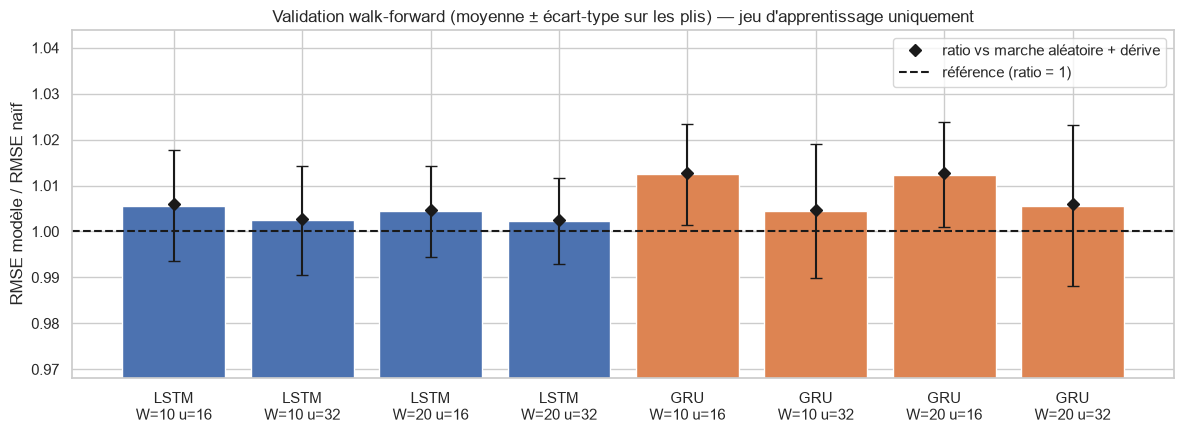

Lecture : barre (vs naïf) < 1 mais losange (vs dérive) ≈ 1 ⇒ le réseau ne fait que reproduire le rendement moyen. L'écart-type indique la stabilité d'un pli à l'autre.


In [136]:
# Visualisation : robustesse de chaque configuration (ratio < 1 ⇒ bat la marche aléatoire)
lab = [f"{r.modele}\nW={r.fenetre} u={r.unites}" for r in grid_df.itertuples()]
plt.figure(figsize=(12, 4.5))
plt.bar(lab, grid_df.ratio_moy, yerr=grid_df.ratio_std, capsize=4, color=["#4C72B0" if m == "LSTM" else "#DD8452" for m in grid_df.modele])
plt.plot(lab, grid_df.ratio_derive_moy, "kD", label="ratio vs marche aléatoire + dérive")
plt.axhline(1.0, color="k", ls="--", label="référence (ratio = 1)")
lo = max(0.0, float(min((grid_df.ratio_moy - grid_df.ratio_std).min(), grid_df.ratio_derive_moy.min())) - 0.02); hi = float((grid_df.ratio_moy + grid_df.ratio_std).max()) + 0.02
plt.ylim(lo, max(hi, 1.02)); plt.ylabel("RMSE modèle / RMSE naïf"); plt.legend()
plt.title("Validation walk-forward (moyenne ± écart-type sur les plis) — jeu d'apprentissage uniquement"); plt.tight_layout(); plt.show()
print("Lecture : barre (vs naïf) < 1 mais losange (vs dérive) ≈ 1 ⇒ le réseau ne fait que reproduire le rendement moyen. L'écart-type indique la stabilité d'un pli à l'autre.")

### Entraînement final, courbes de perte et prévisions sur le test
Chaque architecture retenue est réentraînée sur **tout** le jeu d'apprentissage (normalisation train-only), avec 3 graines ; la prévision est la moyenne des 3 réseaux.
Les **courbes de perte train/validation** documentent la procédure : une validation qui remonte pendant que le train descend = surapprentissage (c'est ce que l'EarlyStopping coupe).

LSTM (W=20, unités=32) entraîné : 9 époques (graine 0)
GRU (W=10, unités=32) entraîné : 21 époques (graine 0)


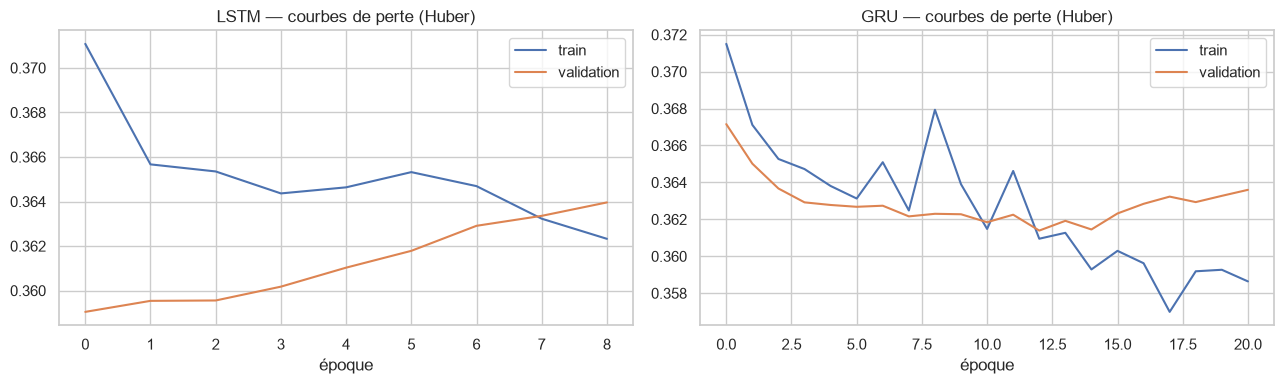

In [137]:
def train_final(kind, W, units, F, cut):
    """Entraîne n_seeds réseaux sur le train complet ; renvoie (rendements prévus sur le test, historique graine 0, prévision J+1 après la dernière date)."""
    m_, s_ = fit_scaler(F, cut); Fs_ = (F - m_) / s_
    X, y, orig = make_windows(Fs_, W); tgt = orig + 1
    tr, te = tgt <= cut - 1, tgt >= cut
    X_last = Fs_[-W:][None, :, :]                       # dernière fenêtre disponible → prévision du jour suivant la fin des données
    preds, nxt, hist0 = [], [], None
    for i in range(CFG["n_seeds"]):
        model, h = fit_one(kind, X[tr], y[tr], W, units, SEED + i)
        preds.append(model.predict(X[te], verbose=0).ravel()); nxt.append(float(model.predict(X_last, verbose=0).ravel()[0]))
        if i == 0: hist0 = h
        keras.backend.clear_session()
    rhat = np.mean(preds, axis=0) * s_[0] + m_[0]
    assert len(rhat) == n_test
    return rhat, hist0, float(np.mean(nxt) * s_[0] + m_[0])

HIST = {}
for kind in ["LSTM", "GRU"]:
    W, u = BEST[kind]
    PRED[kind], HIST[kind], NEXT[kind] = train_final(kind, W, u, F, cut_final)
    print(f"{kind} (W={W}, unités={u}) entraîné : {len(HIST[kind]['loss'])} époques (graine 0)")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, kind in zip(ax, ["LSTM", "GRU"]):
    a.plot(HIST[kind]["loss"], label="train"); a.plot(HIST[kind]["val_loss"], label="validation")
    a.set_title(f"{kind} — courbes de perte (Huber)"); a.set_xlabel("époque"); a.legend()
plt.tight_layout(); plt.show()

## 4.2 — Approche hybride : GARCH → réseau de neurones

**Idée.** Le GARCH(1,1) de l'équipe capte très bien la **volatilité conditionnelle** (résidus standardisés sans autocorrélation ni effet ARCH), mais pas de non-linéarités dans la moyenne. On donne donc au réseau la **volatilité du lendemain prévue par le GARCH**, $\hat\sigma_{t+1}$, en entrée supplémentaire : l'économétrie fournit une information structurée, le réseau apprend ce qu'il peut en faire.

**Pourquoi pas « ARIMA + LSTM sur les résidus » (l'exemple de l'énoncé) ?** L'ARIMA retenu est (0,1,0) : sans terme AR/MA, il ne retire **aucune structure** ; ses résidus sont simplement les variations de prix, donc un LSTM dessus reviendrait à notre LSTM sur les rendements. Le couplage GARCH → réseau est le seul qui apporte une information nouvelle ici.

**Absence de fuite.** $\hat\sigma_{t+1}^2=\omega+\alpha\,\varepsilon_t^2+\beta\,\sigma_t^2$ ne dépend que de données ≤ $t$ ; sur le test, les paramètres sont ceux **estimés sur le train** (`fix`). On le vérifie numériquement. **Étude d'ablation** : mêmes hyper-paramètres que le modèle sans GARCH → toute différence vient de la nouvelle variable.

In [138]:
# --- Volatilité conditionnelle du lendemain : paramètres GARCH figés sur le train, filtrage sur toute la série ---
all_ret_pct = returns["AAPL"] * 100
garch_fixed = arch_model(all_ret_pct, mean="Constant", vol="GARCH", p=1, q=1).fix(garch_res.params)
cv_sig = garch_fixed.conditional_volatility                      # σ_t (connu dès t-1)
sig_next = cv_sig.shift(-1)                                      # σ_{t+1} (connu dès t) = variable utilisable à la date t
sig_next.iloc[-1] = float(np.sqrt(garch_fixed.forecast(horizon=1).variance.iloc[-1, 0]))   # dernier jour : prévision à 1 pas

# Contrôle anti-fuite : σ²_{t+1} = ω + α·ε²_t + β·σ²_t doit retrouver exactement la série décalée
P_ = garch_res.params; eps = all_ret_pct - P_["mu"]
check = P_["omega"] + P_["alpha[1]"] * eps**2 + P_["beta[1]"] * cv_sig**2
print("contrôle fuite — écart max :", float(np.max(np.abs(np.sqrt(check.iloc[:-1]) - cv_sig.shift(-1).iloc[:-1]).dropna())), "(≈ 0 ⇒ σ_{t+1} ne dépend que de données ≤ t)")

dataset["GARCH_Sigma_next"] = sig_next.reindex(dataset.index)
FEATURES_HYB = FEATURES_BASE + ["GARCH_Sigma_next"]
feat_h = dataset[FEATURES_HYB].dropna()
assert (feat_h.index == feat.index).all()
F_h = feat_h.values.astype("float64")

for kind in ["LSTM", "GRU"]:
    W, u = BEST[kind]                                            # mêmes hyper-paramètres → ablation propre
    PRED[f"{kind}+GARCH"], HIST[f"{kind}+GARCH"], NEXT[f"{kind}+GARCH"] = train_final(kind, W, u, F_h, cut_final)
    print(f"{kind}+GARCH entraîné ({len(HIST[f'{kind}+GARCH']['loss'])} époques, graine 0)")

contrôle fuite — écart max : 8.881784197001252e-16 (≈ 0 ⇒ σ_{t+1} ne dépend que de données ≤ t)
LSTM+GARCH entraîné (9 époques, graine 0)
GRU+GARCH entraîné (16 époques, graine 0)


## 4.4 — Comparaison rigoureuse : classique vs réseaux de neurones (test, prévision à 1 jour)

**Métriques** : MSE, RMSE, MAE, MAPE sur les **prix** (comme l'ARIMA de l'équipe) ; RMSE/MAE sur les **rendements** (échelle où le signal se joue) ; `Hit` = % de jours où le signe du rendement est bien prévu (non défini pour le modèle naïf qui prévoit 0). Le MAPE n'est pas calculé sur les rendements (division par des valeurs proches de 0 → non pertinent).

**Test de Diebold-Mariano** (perte quadratique, horizon 1, correction de Harvey-Leybourne-Newbold) : ne pas se contenter de comparer des RMSE bruts, mais tester si l'écart est statistiquement significatif. Convention : **DM < 0 ⇒ le modèle a une perte plus faible que la référence (ARIMA(0,1,0))**.

In [139]:
def diebold_mariano(e_model, e_ref, h=1, power=2):
    """DM (Harvey-Leybourne-Newbold). d_t = |e_model|^p − |e_ref|^p ; DM<0 ⇒ le modèle est meilleur que la référence."""
    d = np.abs(np.asarray(e_model))**power - np.abs(np.asarray(e_ref))**power
    T, dbar = len(d), d.mean()
    gam = lambda k: np.sum((d[k:] - dbar) * (d[:T - k] - dbar)) / T
    var = gam(0) + 2 * sum(gam(k) for k in range(1, h))
    if var <= 1e-18: return np.nan, np.nan
    dm = dbar / np.sqrt(var / T) * np.sqrt((T + 1 - 2*h + h*(h - 1) / T) / T)
    return float(dm), float(2 * (1 - stats.t.cdf(abs(dm), df=T - 1)))

REF = "ARIMA(0,1,0) / naïf"
rows = []
for name, rhat in PRED.items():
    Phat = P_org * np.exp(rhat)
    row = dict(modele=name, **price_metrics(P_next, Phat), **return_metrics(r_next, rhat))
    e_p, e_r = P_next - Phat, r_next - rhat
    ref_p, ref_r = P_next - P_org, r_next
    row["DM_prix"], row["p_DM_prix"] = diebold_mariano(e_p, ref_p) if name != REF else (np.nan, np.nan)
    row["DM_rend"], row["p_DM_rend"] = diebold_mariano(e_r, ref_r) if name != REF else (np.nan, np.nan)
    rows.append(row)
results_df = pd.DataFrame(rows).set_index("modele")
display(results_df.round(4))

def verdict(dm, p):
    if np.isnan(p): return "référence"
    if p < 0.05: return "significativement MEILLEUR" if dm < 0 else "significativement MOINS BON"
    return "différence non significative"
results_df["verdict_vs_ARIMA"] = [verdict(r.DM_rend, r.p_DM_rend) for r in results_df.itertuples()]
print("\nVerdict Diebold-Mariano (rendements, α = 5 %) :"); display(results_df[["RMSE_ret", "p_DM_rend", "verdict_vs_ARIMA"]].round(4))

# Référence plus exigeante : « marche aléatoire + dérive » (un réseau qui prévoit juste le rendement moyen bat le naïf sans rien apprendre)
print("\nDiebold-Mariano contre « marche aléatoire + dérive » (rendements) :")
for nm in ["LSTM", "GRU", "LSTM+GARCH", "GRU+GARCH"]:
    dm, p = diebold_mariano(r_next - PRED[nm], r_next - PRED["Marche aléatoire + dérive"])
    results_df.loc[nm, "p_DM_vs_derive"] = p
    print(f"  {nm:11s}: DM = {dm:+.3f}, p = {p:.3f} → {verdict(dm, p)}")

# Ablation : le GARCH apporte-t-il quelque chose au réseau ?
for kind in ["LSTM", "GRU"]:
    dm, p = diebold_mariano(r_next - PRED[f"{kind}+GARCH"], r_next - PRED[kind])
    print(f"Ablation {kind}+GARCH vs {kind} : DM = {dm:.3f}, p = {p:.3f} → {verdict(dm, p)}")

,MSE,RMSE,MAE,MAPE,RMSE_ret,MAE_ret,Hit,DM_prix,p_DM_prix,DM_rend,p_DM_rend
modele,,,,,,,,,,,
"ARIMA(0,1,0) / naïf",23.4163,4.8390,3.4608,1.1963,0.0166,0.0120,NaN,NaN,NaN,NaN,NaN
Marche aléatoire + dérive,23.3339,4.8305,3.4456,1.1921,0.0166,0.0119,0.5282,-0.3559,0.7223,-0.4119,0.6809
LSTM,23.5963,4.8576,3.4581,1.1967,0.0166,0.0119,0.5231,0.5083,0.6118,0.4784,0.6329
GRU,22.9731,4.7930,3.4050,1.1787,0.0164,0.0118,0.5692,-1.3281,0.1857,-1.1850,0.2375
LSTM+GARCH,23.5756,4.8555,3.4595,1.1972,0.0166,0.0120,0.5282,0.4613,0.6451,0.4105,0.6819
GRU+GARCH,23.0278,4.7987,3.4036,1.1780,0.0164,0.0118,0.5538,-1.1560,0.2491,-1.1047,0.2707



Verdict Diebold-Mariano (rendements, α = 5 %) :


,RMSE_ret,p_DM_rend,verdict_vs_ARIMA
modele,,,
"ARIMA(0,1,0) / naïf",0.0166,NaN,référence
Marche aléatoire + dérive,0.0166,0.6809,différence non significative
LSTM,0.0166,0.6329,différence non significative
GRU,0.0164,0.2375,différence non significative
LSTM+GARCH,0.0166,0.6819,différence non significative
GRU+GARCH,0.0164,0.2707,différence non significative



Diebold-Mariano contre « marche aléatoire + dérive » (rendements) :
  LSTM       : DM = +1.643, p = 0.102 → différence non significative
  GRU        : DM = -1.319, p = 0.189 → différence non significative
  LSTM+GARCH : DM = +1.427, p = 0.155 → différence non significative
  GRU+GARCH  : DM = -1.258, p = 0.210 → différence non significative
Ablation LSTM+GARCH vs LSTM : DM = -0.244, p = 0.807 → différence non significative
Ablation GRU+GARCH vs GRU : DM = 0.303, p = 0.762 → différence non significative


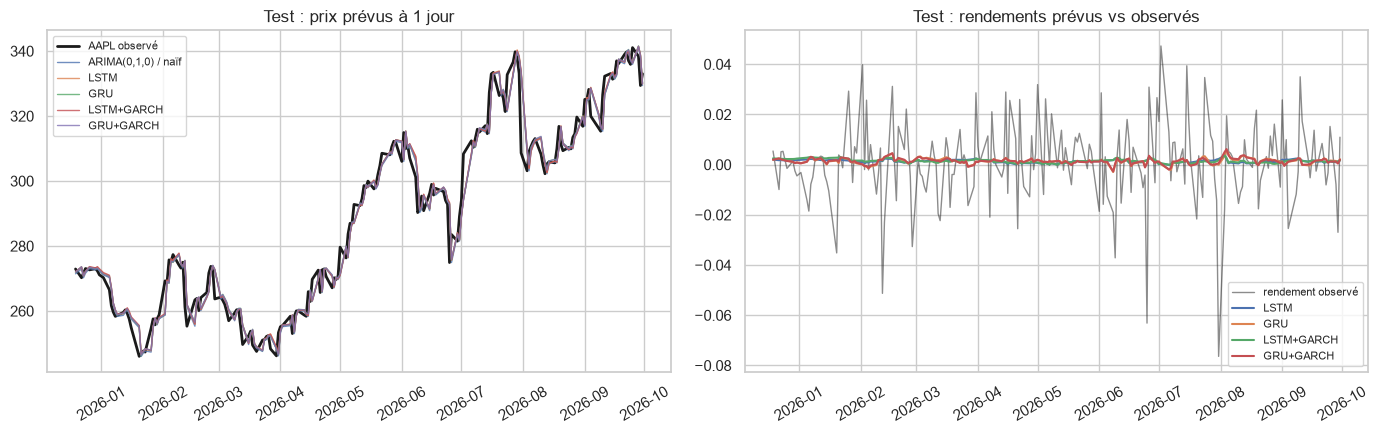

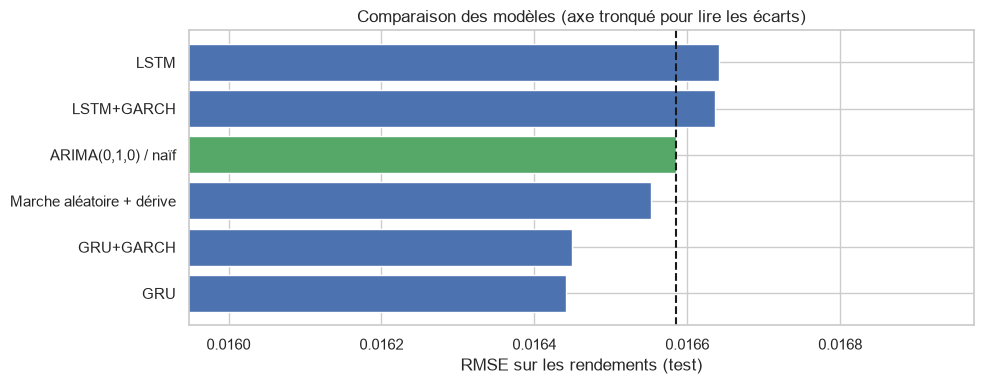

Lecture : sur les prix, toutes les courbes se superposent (le prix d'hier explique presque tout) ; c'est sur les RENDEMENTS que l'on voit si un modèle ajoute de l'information.


In [140]:
# --- Graphiques de test -------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(tgt_dates, P_next, "k", lw=2, label="AAPL observé")
for nm in ["ARIMA(0,1,0) / naïf", "LSTM", "GRU", "LSTM+GARCH", "GRU+GARCH"]:
    ax[0].plot(tgt_dates, P_org * np.exp(PRED[nm]), lw=1, alpha=.8, label=nm)
ax[0].set_title("Test : prix prévus à 1 jour"); ax[0].legend(fontsize=8); ax[0].tick_params(axis="x", rotation=30)
ax[1].plot(tgt_dates, r_next, "k", lw=1, alpha=.5, label="rendement observé")
for nm in ["LSTM", "GRU", "LSTM+GARCH", "GRU+GARCH"]:
    ax[1].plot(tgt_dates, PRED[nm], lw=1.5, label=nm)
ax[1].set_title("Test : rendements prévus vs observés"); ax[1].legend(fontsize=8); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 4))
order = results_df.sort_values("RMSE_ret").index
plt.barh(order, results_df.loc[order, "RMSE_ret"], color=["#55A868" if o == REF else "#4C72B0" for o in order])
plt.axvline(results_df.loc[REF, "RMSE_ret"], color="k", ls="--"); plt.xlabel("RMSE sur les rendements (test)")
lo_ = results_df["RMSE_ret"].min() * 0.97; plt.xlim(lo_, results_df["RMSE_ret"].max() * 1.02)
plt.title("Comparaison des modèles (axe tronqué pour lire les écarts)"); plt.tight_layout(); plt.show()
print("Lecture : sur les prix, toutes les courbes se superposent (le prix d'hier explique presque tout) ; c'est sur les RENDEMENTS que l'on voit si un modèle ajoute de l'information.")

In [141]:
# --- Sauvegarde pour la partie 6 (tableau récapitulatif unique) et pour la partie 5 ----------
results_df.to_csv(f"{OUT_DIR}/results_part4.csv")
pd.DataFrame({"P_t": P_org, "P_t+1": P_next, "r_t+1": r_next, **{f"rhat_{k}": v for k, v in PRED.items()}},
             index=tgt_dates).to_csv(f"{OUT_DIR}/predictions_test_part4.csv")
grid_df.to_csv(f"{OUT_DIR}/walkforward_grid_part4.csv", index=False)

best_name = results_df["RMSE_ret"].idxmin()
print(f"Meilleur RMSE (rendements, test) : {best_name} = {results_df.loc[best_name, 'RMSE_ret']:.5f} "
      f"| référence ARIMA(0,1,0) = {results_df.loc[REF, 'RMSE_ret']:.5f}")
print("Diebold-Mariano pour ce modèle :", results_df.loc[best_name, "verdict_vs_ARIMA"])
print("Fichiers écrits dans", OUT_DIR)

Meilleur RMSE (rendements, test) : GRU = 0.01644 | référence ARIMA(0,1,0) = 0.01659
Diebold-Mariano pour ce modèle : différence non significative
Fichiers écrits dans ../outputs


### Comment interpréter ces résultats (à rédiger dans le rapport avec VOS chiffres)

1. **Ordre de grandeur attendu** : sur des rendements quotidiens d'une action très liquide, le signal prévisible est minuscule (le R² d'un AR(1) à ρ ≈ −0.08 est ≈ 0.6 %). Un ratio RMSE/naïf très proche de 1 et un Diebold-Mariano **non significatif** ne sont donc **pas un échec** : c'est un résultat cohérent avec l'hypothèse d'efficience faible des marchés, et il est honnête de le rapporter (critère « honnêteté scientifique » du barème).
2. **Cohérence walk-forward ↔ test** : si le ratio moyen des plis est ≈ 1 et celui du test aussi, la conclusion est robuste. Une grande dispersion entre plis signale un résultat instable (régimes différents : 2020, 2022, avril 2025…).
3. **Dérive** : comparez toujours le réseau à la marche aléatoire *avec dérive*. Si le réseau n'est pas significativement meilleur qu'elle, son « avantage » sur le naïf n'est que le rendement moyen positif de la période d'apprentissage.
4. **Hit ratio** : un score proche de 50 % n'a aucune valeur d'investissement ; > 55 % de façon stable (et significatif) serait notable.
5. **Ablation GARCH** : l'ajout de σ̂ est utile s'il améliore la perte de façon significative ; sinon, la volatilité aide à *mesurer le risque* (GARCH) mais pas à *prévoir la direction* (réseau).
6. **Classique vs avancé** : à performance statistiquement égale, on préfère le modèle le plus **simple, interprétable et peu coûteux** (ARIMA/marche aléatoire) ; à citer dans le tableau de comparaison (interprétabilité, nombre de paramètres, temps de calcul).

# Partie 5 — IA générative et LLM

### Protocole suivi (et pourquoi)
L'énoncé demande d'utiliser un LLM **comme assistant d'analyse, avec un regard critique**. Le protocole est donc :

| Étape | Ce qu'on fait | Pourquoi |
|---|---|---|
| 0 | L'équipe rédige **sa propre interprétation experte AVANT de consulter le LLM** | pour pouvoir comparer honnêtement ensuite (sinon on est influencé) |
| 5.1 | Prompt A → **hypothèses de modèles** à partir des statistiques descriptives et des tests de stationnarité | demandé par l'énoncé |
| 5.2 | Prompt B → **explication vulgarisée** pour un décideur non statisticien | demandé |
| 5.3 | Prompt C → **recommandations simulées** ; le LLM doit **formuler lui-même les limites** avant de recommander, puis on les complète | demandé |
| 5.4 | **Comparaison humain / LLM** + journal des erreurs détectées | critère « esprit critique face au LLM » |

**Garde-fous contre l'hallucination statistique** : (1) les prompts sont **construits par le code** à partir des résultats réels (aucun chiffre retapé à la main) ; (2) on demande au LLM de ne rien inventer et de signaler les informations manquantes ; (3) une fonction **repère tout nombre de la réponse absent du prompt** (p-value ou statistique potentiellement inventée) ; (4) chaque nombre « dérivé » par le LLM est **recalculé** par le code.

**Traçabilité** : chaque prompt est sauvegardé dans `llm/prompt_X.txt` et chaque réponse intégrale dans `llm/response_X.md`.

## 5.1 — Génération d'hypothèses de modèles à partir des statistiques descriptives (Prompt A)

Le prompt A est **identique à ce qui a été envoyé** au LLM (Claude, Anthropic — conversation du 11/10/2026). Les chiffres sont ceux des sections 2 et 3 du notebook de l'équipe ; la cellule de contrôle ci-dessous vérifie qu'ils correspondent bien aux valeurs recalculées.

In [173]:
# === Utilitaires de la partie 5 : traçabilité des prompts / réponses et détection de chiffres suspects ===
def save_text(path, text):
    with open(path, "w", encoding="utf-8") as f: f.write(text)

def read_text(path):
    return open(path, encoding="utf-8").read() if os.path.exists(path) else None

def ask_llm(prompt, model="claude-opus-4.8", max_tokens=1800):
    """Appel automatique OPTIONNEL (si ANTHROPIC_API_KEY est définie). Sinon : copier-coller manuel (voir run_llm_step)."""
    key = os.environ.get("ANTHROPIC_API_KEY")
    if not key: return None
    try:
        import anthropic
        msg = anthropic.Anthropic(api_key=key).messages.create(model=model, max_tokens=max_tokens,
                                                              messages=[{"role": "user", "content": prompt}])
        return "".join(b.text for b in msg.content if b.type == "text")
    except Exception as e:
        print("Appel API impossible :", e); return None

_NUM = re.compile(r"[-+]?\d+(?:\.\d+)?(?:[eE][-+]?\d+)?")
def _numbers(text):
    t = text.replace("−", "-").replace("%", " %")
    t = re.sub(r"(\d),(\d{2,})(?![,\d])", r"\1.\2", t)               # virgule décimale française (pas les couples type GARCH(1,1))
    return [(m.group(), float(m.group())) for m in _NUM.finditer(t)]

def flag_unverified_numbers(response, prompt):
    """Nombres de la réponse ABSENTS du prompt (à ±0.5 % ou à l'arrondi près) : statistiques possiblement inventées ou dérivées.
    Comparaison en valeur absolue. Ignore les entiers triviaux (≤ 30, années) et les constantes usuelles (0.01, 0.05, 0.1, 1.96, 95, 100, 252)."""
    ref = [abs(v) for _, v in _numbers(prompt)]
    flagged = []
    for s, x in _numbers(response):
        if float(x).is_integer() and (abs(x) <= 30 or 1990 <= abs(x) <= 2100): continue
        x = abs(x)
        if x in {0.01, 0.05, 0.1, 0.10, 0.5, 1.96, 95, 100, 252}: continue
        dec = len(s.split(".")[1].lower().split("e")[0]) if "." in s else 0
        if not any(abs(x - y) <= 0.005 * y + 1e-12 or round(y, dec) == x for y in ref):
            if s not in flagged: flagged.append(s)
    return flagged

def run_llm_step(name, prompt, answer_text=None):
    """Sauvegarde le prompt, récupère la réponse (fichier existant > texte fourni > API > absente) et la contrôle."""
    save_text(f"{LLM_DIR}/prompt_{name}.txt", prompt)
    path = f"{LLM_DIR}/response_{name}.md"
    resp = answer_text if answer_text is not None else read_text(path)     # réponse intégrée au notebook > fichier collé par l'équipe
    if answer_text is not None: save_text(path, resp)
    if resp is None:
        resp = ask_llm(prompt)
        if resp: save_text(path, resp)
    display(Markdown(f"**Prompt {name}** (sauvegardé dans `{LLM_DIR}/prompt_{name}.txt`)")); print(prompt)
    if resp is None:
        display(Markdown(f"> ⚠ **Réponse du LLM non disponible.** Copier le prompt ci-dessus dans le LLM de votre choix, enregistrer sa réponse "
                         f"**intégrale** dans `{LLM_DIR}/response_{name}.md`, puis ré-exécuter cette cellule "
                         f"(ou définir la variable d'environnement `ANTHROPIC_API_KEY` pour un appel automatique)."))
        return None
    display(Markdown(f"---\n**Réponse du LLM — {name}** (intégrale, `{LLM_DIR}/response_{name}.md`)\n\n" + resp))
    bad = flag_unverified_numbers(resp, prompt)
    print("\n🔎 Nombres de la réponse absents du prompt (à vérifier un par un) :", bad if bad else "aucun")
    return resp

In [174]:
PROMPT_A = """Tu es un expert en séries temporelles financières. Je prépare un mini-projet académique (cours Séries Temporelles, Data Science & IA). Voici les statistiques de mes données ; je veux des HYPOTHÈSES DE MODÈLES À TESTER, pas des prévisions.

DONNÉES
- Séries : prix ajustés (Adj Close) journaliers de AAPL et QQQ, du 2019-01-02 au 2026-09-30 (1947 observations). Apprentissage : 1752 observations (jusqu'au 2025-12-18) ; test : 195 observations.
- Rendements logarithmiques (1946 observations, échantillon complet) :
  AAPL : moyenne 0.001123 ; écart-type 0.019309 ; min -0.137708 ; Q1 -0.007782 ; médiane 0.001301 ; Q3 0.011201 ; max 0.142617 ; skewness -0.1201 ; kurtosis en excès 6.5079
  QQQ  : moyenne 0.000828 ; écart-type 0.015073 ; min -0.127593 ; Q1 -0.006139 ; médiane 0.001404 ; Q3 0.008745 ; max 0.113356 ; skewness -0.3657 ; kurtosis en excès 7.2799
- Tests de stationnarité (échantillon d'apprentissage) :
  ADF (H0 = racine unitaire) : AAPL prix stat -0.7299 p 0.8388 ; QQQ prix stat 0.0065 p 0.9591 ; AAPL rendements stat -13.5753 p 2.2e-25 ; QQQ rendements stat -13.2064 p 1.1e-24
  KPSS (H0 = stationnarité autour d'une constante) : AAPL prix stat 5.9976 p 0.01 ; QQQ prix stat 5.4912 p 0.01 ; AAPL rendements stat 0.2135 p 0.10 ; QQQ rendements stat 0.0903 p 0.10 (p-values KPSS tronquées aux bornes de la table : 0.01 et 0.10)
- Lectures graphiques (approximatives) : ACF des prix : décroissance très lente (environ 0.88 au lag 40) ; ACF des rendements : autocorrélations faibles, lag 1 environ -0.08 (AAPL) et -0.13 (QQQ), quelques pics isolés aux lags 7 à 9 ; volatilité glissante 20 jours d'AAPL : regroupements marqués, pics vers 0.068 (mars 2020) et 0.05 (avril 2025), plancher vers 0.006.

DEMANDE
1. Propose une liste hiérarchisée d'hypothèses de modèles à tester (classiques d'abord, puis neuronaux). Pour chaque hypothèse : énoncé, justification chiffrée tirée UNIQUEMENT des données ci-dessus, test de validation à appliquer, risque principal.
2. Signale explicitement toute information manquante dont tu aurais besoin ; n'invente aucune statistique.
3. Termine par 3 limites de ta propre analyse."""

In [175]:
# Contrôle de cohérence : les chiffres du prompt A correspondent-ils aux valeurs recalculées ? (échantillon complet pour les descriptives, train pour les tests)
st = R["stationnarite"]
chk = []
for nm, col in [("AAPL", "AAPL"), ("QQQ", "QQQ")]:
    s = returns[col]
    chk += [(f"{nm} moyenne", s.mean()), (f"{nm} écart-type", s.std()), (f"{nm} skewness", s.skew()), (f"{nm} kurtosis excès", s.kurtosis())]
for nm in st.index:
    chk += [(f"ADF stat {nm}", st.loc[nm, "adf_stat"]), (f"KPSS stat {nm}", st.loc[nm, "kpss_stat"])]
live = pd.DataFrame(chk, columns=["valeur", "recalcul"]).set_index("valeur")
ref_nums = _numbers(PROMPT_A)          # (texte, valeur) : on compare à l'arrondi affiché dans le prompt
def _in_prompt(x):
    for s_, y in ref_nums:
        dec = len(s_.split(".")[1].lower().split("e")[0]) if "." in s_ else 0
        if round(x, dec) == y or abs(x - y) <= 1e-3 * abs(y): return True
    return False
live["présent dans le prompt A ?"] = [_in_prompt(x) for x in live["recalcul"]]
display(live.round(5))
print("✔ tous les chiffres du prompt A correspondent aux calculs de ce notebook" if live["présent dans le prompt A ?"].all()
      else "⚠ certaines valeurs diffèrent (données mises à jour par Yahoo ?) : régénérer le prompt A avec les nouvelles valeurs avant de le soumettre au LLM")

,recalcul,présent dans le prompt A ?
valeur,,
AAPL moyenne,0.00112,True
AAPL écart-type,0.01931,True
AAPL skewness,-0.12015,True
AAPL kurtosis excès,6.50793,True
QQQ moyenne,0.00083,True
QQQ écart-type,0.01507,True
QQQ skewness,-0.36574,True
QQQ kurtosis excès,7.27990,True
ADF stat AAPL prix,-0.72992,True


✔ tous les chiffres du prompt A correspondent aux calculs de ce notebook


In [176]:
RESPONSE_A = """**Remarque préalable.** Toutes les justifications ci-dessous reposent sur vos chiffres. Les valeurs que j'ai **calculées moi-même** à partir d'eux sont marquées *(dérivé)* : à recalculer de votre côté.

## A. Hypothèses classiques

**H1 — Les prix sont intégrés d'ordre 1 : modéliser les différences / rendements (d = 1).**
- Justification : ADF ne rejette pas la racine unitaire sur les prix (p = 0.8388 pour AAPL, p = 0.9591 pour QQQ) et KPSS rejette la stationnarité (statistiques 5.9976 et 5.4912, p = 0.01). C'est l'inverse sur les rendements (ADF p = 2.2e-25 et 1.1e-24 ; KPSS 0.2135 et 0.0903, p = 0.10). Les deux tests, d'hypothèses nulles opposées, convergent.
- Test : relancer ADF/KPSS avec constante puis constante + tendance ; contrôler le nombre de retards de l'ADF.
- Risque : ces tests ont une puissance limitée face à des ruptures (mars 2020) ; « d = 1 » est une approximation de travail, pas une preuve d'une racine unitaire exacte.

**H2 — Référence à battre : marche aléatoire, ARIMA(0,1,0).**
- Justification : l'ACF des prix décroît très lentement (≈ 0.88 au lag 40, signature d'une racine unitaire) et celle des rendements est faible (|ρ₁| ≤ 0.13).
- Test : Ljung-Box sur les résidus ; comparaison AIC/BIC avec ARIMA(1,1,0) et (0,1,1).
- Risque : si aucun modèle ne bat cette référence, ce n'est pas un échec mais le résultat attendu sur un actif liquide.
- Dérive : t ≈ 2.57 (AAPL) et ≈ 2.42 (QQQ) *(dérivé, calculé comme si les rendements étaient i.i.d.)* → inclure une constante dans les modèles de moyenne. Ce t est probablement surestimé car il ignore les queues épaisses et le regroupement de volatilité.

**H3 — Faible structure linéaire de court terme dans les rendements (AR d'ordre faible).**
- Justification : ρ₁ ≈ -0.08 (AAPL) et ≈ -0.13 (QQQ) sortent de la bande ±1.96/√1752 ≈ ±0.047 *(dérivé)*. Mais le R² associé est ≈ ρ² ≈ 0.64 % et ≈ 1.69 % *(dérivé)*.
- Test : ACF/PACF numériques, Ljung-Box, AIC/BIC d'AR(1), AR(2), ARMA(1,1).
- Risque : significatif ne veut pas dire exploitable (coûts de transaction) ; les pics aux lags 7-9 peuvent être des faux positifs (beaucoup de lags testés simultanément).

**H4 — Dépendance AAPL–QQQ : VAR sur les rendements + causalité de Granger.**
- Justification : le rapport des écarts-types est 1.28 *(dérivé)* et les deux séries ont des asymétries et kurtosis de même signe/ordre de grandeur. La corrélation n'est pas fournie : l'hypothèse est plausible mais non vérifiable ici.
- Test : sélection de l'ordre par AIC/BIC, stabilité, test de Granger dans les deux sens.
- Risque : une forte corrélation simultanée n'implique pas de prédictibilité décalée ; AIC et BIC choisissent souvent des ordres très différents.

**H5 — Cointégration des log-prix (Engle-Granger / Johansen).**
- Justification : condition nécessaire remplie si les deux séries sont I(1) (H1). Elle n'est pas suffisante, et vos données ne disent rien d'une relation de long terme. AAPL est une composante de QQQ (connaissance générale, **pas** issue de vos données).
- Test : Johansen (trace, constante dans la relation) ; si rejet de H0 seulement, estimer un VECM.
- Risque : la cointégration est souvent absente entre un titre et son indice sur 7 ans ; ne pas forcer un VECM.

## B. Volatilité et distribution

**H6 — Hétéroscédasticité conditionnelle : GARCH(1,1).**
- Justification : volatilité glissante entre ≈ 0.006 et ≈ 0.068, soit un facteur ≈ 11 *(dérivé)*, avec regroupements ; kurtosis en excès 6.5079 et 7.2799.
- Test : ARCH-LM sur les résidus du modèle de moyenne, puis sur les résidus standardisés ; Ljung-Box sur les carrés.
- Risque : un GARCH(1,1) gaussien sous-estime les queues.

**H7 — Innovations à queues épaisses (loi de Student).**
- Justification : pour une loi t i.i.d., kurtosis en excès = 6/(ν − 4), d'où ν ≈ 4.9 (AAPL) et ≈ 4.8 (QQQ) *(dérivé)*.
- Test : Jarque-Bera et QQ-plot des résidus standardisés ; estimer ν par maximum de vraisemblance ; comparer AIC/BIC gaussien vs Student.
- Risque : le kurtosis inconditionnel mélange regroupement de volatilité et vraies queues épaisses, donc ν conditionnel est en général plus grand ; il dépend aussi de 2-3 jours extrêmes (-0.138 et +0.143).

**H8 — Asymétrie (GJR-GARCH / EGARCH), surtout pour QQQ.**
- Justification : skewness -0.3657 (QQQ) contre -0.1201 (AAPL) ; médianes supérieures aux moyennes (0.001404 > 0.000828 ; 0.001301 > 0.001123).
- Test : test de biais de signe d'Engle-Ng ; significativité du paramètre d'asymétrie.
- Risque : une skewness inconditionnelle ne prouve pas un effet de levier ; pour AAPL l'indice est faible.

## C. Modèles neuronaux

**H9 — LSTM/GRU sur les rendements (stationnaires d'après H1), fenêtre ≥ 10 jours** (pics aux lags 7-9), entrées : rendements AAPL et QQQ + volatilité glissante 20 j.
- Test : validation walk-forward ; comparaison à la prévision naïve (rendement 0) ; test de Diebold-Mariano.
- Risque : si le R² linéaire plausible est ≤ 2 % (H3), le gain attendu est très faible ; avec ~1750 observations le surapprentissage est le danger principal.

**H10 — Hybride : sortie d'un GARCH comme variable d'entrée du réseau.**
- Test : étude d'ablation avec / sans la variable GARCH, mêmes hyper-paramètres.
- Risque : fuite d'information si la volatilité utilisée à la date t contient de l'information sur t+1 : bien décaler les séries.

**H11 — Pas de SARIMA a priori** : aucune donnée fournie n'indique de saisonnalité. À ne tester (jour de la semaine, lags 5 et 21) que si l'ACF numérique le suggère.

## Informations manquantes
Corrélation AAPL–QQQ ; valeurs numériques de l'ACF/PACF ; test de normalité sur les rendements ; test ARCH ; spécification déterministe et nombre de retards de l'ADF ; volumes ; composition de QQQ ; régime de marché de la période de test.

## Trois limites de mon analyse
1. Les statistiques descriptives semblent calculées sur l'échantillon complet (test inclus) : risque de regard vers l'avenir si elles guident le choix des modèles.
2. Les lectures graphiques (ACF, volatilité) sont approximatives.
3. Mes ν, R² et t-stats sont des approximations simples (dérivées) qui ne remplacent pas une estimation par maximum de vraisemblance ni des erreurs-types robustes."""
resp_A = run_llm_step("A", PROMPT_A, answer_text=RESPONSE_A)

**Prompt A** (sauvegardé dans `../llm/prompt_A.txt`)

Tu es un expert en séries temporelles financières. Je prépare un mini-projet académique (cours Séries Temporelles, Data Science & IA). Voici les statistiques de mes données ; je veux des HYPOTHÈSES DE MODÈLES À TESTER, pas des prévisions.

DONNÉES
- Séries : prix ajustés (Adj Close) journaliers de AAPL et QQQ, du 2019-01-02 au 2026-09-30 (1947 observations). Apprentissage : 1752 observations (jusqu'au 2025-12-18) ; test : 195 observations.
- Rendements logarithmiques (1946 observations, échantillon complet) :
  AAPL : moyenne 0.001123 ; écart-type 0.019309 ; min -0.137708 ; Q1 -0.007782 ; médiane 0.001301 ; Q3 0.011201 ; max 0.142617 ; skewness -0.1201 ; kurtosis en excès 6.5079
  QQQ  : moyenne 0.000828 ; écart-type 0.015073 ; min -0.127593 ; Q1 -0.006139 ; médiane 0.001404 ; Q3 0.008745 ; max 0.113356 ; skewness -0.3657 ; kurtosis en excès 7.2799
- Tests de stationnarité (échantillon d'apprentissage) :
  ADF (H0 = racine unitaire) : AAPL prix stat -0.7299 p 0.8388 ; QQQ prix stat 0.0

---
**Réponse du LLM — A** (intégrale, `../llm/response_A.md`)

**Remarque préalable.** Toutes les justifications ci-dessous reposent sur vos chiffres. Les valeurs que j'ai **calculées moi-même** à partir d'eux sont marquées *(dérivé)* : à recalculer de votre côté.

## A. Hypothèses classiques

**H1 — Les prix sont intégrés d'ordre 1 : modéliser les différences / rendements (d = 1).**
- Justification : ADF ne rejette pas la racine unitaire sur les prix (p = 0.8388 pour AAPL, p = 0.9591 pour QQQ) et KPSS rejette la stationnarité (statistiques 5.9976 et 5.4912, p = 0.01). C'est l'inverse sur les rendements (ADF p = 2.2e-25 et 1.1e-24 ; KPSS 0.2135 et 0.0903, p = 0.10). Les deux tests, d'hypothèses nulles opposées, convergent.
- Test : relancer ADF/KPSS avec constante puis constante + tendance ; contrôler le nombre de retards de l'ADF.
- Risque : ces tests ont une puissance limitée face à des ruptures (mars 2020) ; « d = 1 » est une approximation de travail, pas une preuve d'une racine unitaire exacte.

**H2 — Référence à battre : marche aléatoire, ARIMA(0,1,0).**
- Justification : l'ACF des prix décroît très lentement (≈ 0.88 au lag 40, signature d'une racine unitaire) et celle des rendements est faible (|ρ₁| ≤ 0.13).
- Test : Ljung-Box sur les résidus ; comparaison AIC/BIC avec ARIMA(1,1,0) et (0,1,1).
- Risque : si aucun modèle ne bat cette référence, ce n'est pas un échec mais le résultat attendu sur un actif liquide.
- Dérive : t ≈ 2.57 (AAPL) et ≈ 2.42 (QQQ) *(dérivé, calculé comme si les rendements étaient i.i.d.)* → inclure une constante dans les modèles de moyenne. Ce t est probablement surestimé car il ignore les queues épaisses et le regroupement de volatilité.

**H3 — Faible structure linéaire de court terme dans les rendements (AR d'ordre faible).**
- Justification : ρ₁ ≈ -0.08 (AAPL) et ≈ -0.13 (QQQ) sortent de la bande ±1.96/√1752 ≈ ±0.047 *(dérivé)*. Mais le R² associé est ≈ ρ² ≈ 0.64 % et ≈ 1.69 % *(dérivé)*.
- Test : ACF/PACF numériques, Ljung-Box, AIC/BIC d'AR(1), AR(2), ARMA(1,1).
- Risque : significatif ne veut pas dire exploitable (coûts de transaction) ; les pics aux lags 7-9 peuvent être des faux positifs (beaucoup de lags testés simultanément).

**H4 — Dépendance AAPL–QQQ : VAR sur les rendements + causalité de Granger.**
- Justification : le rapport des écarts-types est 1.28 *(dérivé)* et les deux séries ont des asymétries et kurtosis de même signe/ordre de grandeur. La corrélation n'est pas fournie : l'hypothèse est plausible mais non vérifiable ici.
- Test : sélection de l'ordre par AIC/BIC, stabilité, test de Granger dans les deux sens.
- Risque : une forte corrélation simultanée n'implique pas de prédictibilité décalée ; AIC et BIC choisissent souvent des ordres très différents.

**H5 — Cointégration des log-prix (Engle-Granger / Johansen).**
- Justification : condition nécessaire remplie si les deux séries sont I(1) (H1). Elle n'est pas suffisante, et vos données ne disent rien d'une relation de long terme. AAPL est une composante de QQQ (connaissance générale, **pas** issue de vos données).
- Test : Johansen (trace, constante dans la relation) ; si rejet de H0 seulement, estimer un VECM.
- Risque : la cointégration est souvent absente entre un titre et son indice sur 7 ans ; ne pas forcer un VECM.

## B. Volatilité et distribution

**H6 — Hétéroscédasticité conditionnelle : GARCH(1,1).**
- Justification : volatilité glissante entre ≈ 0.006 et ≈ 0.068, soit un facteur ≈ 11 *(dérivé)*, avec regroupements ; kurtosis en excès 6.5079 et 7.2799.
- Test : ARCH-LM sur les résidus du modèle de moyenne, puis sur les résidus standardisés ; Ljung-Box sur les carrés.
- Risque : un GARCH(1,1) gaussien sous-estime les queues.

**H7 — Innovations à queues épaisses (loi de Student).**
- Justification : pour une loi t i.i.d., kurtosis en excès = 6/(ν − 4), d'où ν ≈ 4.9 (AAPL) et ≈ 4.8 (QQQ) *(dérivé)*.
- Test : Jarque-Bera et QQ-plot des résidus standardisés ; estimer ν par maximum de vraisemblance ; comparer AIC/BIC gaussien vs Student.
- Risque : le kurtosis inconditionnel mélange regroupement de volatilité et vraies queues épaisses, donc ν conditionnel est en général plus grand ; il dépend aussi de 2-3 jours extrêmes (-0.138 et +0.143).

**H8 — Asymétrie (GJR-GARCH / EGARCH), surtout pour QQQ.**
- Justification : skewness -0.3657 (QQQ) contre -0.1201 (AAPL) ; médianes supérieures aux moyennes (0.001404 > 0.000828 ; 0.001301 > 0.001123).
- Test : test de biais de signe d'Engle-Ng ; significativité du paramètre d'asymétrie.
- Risque : une skewness inconditionnelle ne prouve pas un effet de levier ; pour AAPL l'indice est faible.

## C. Modèles neuronaux

**H9 — LSTM/GRU sur les rendements (stationnaires d'après H1), fenêtre ≥ 10 jours** (pics aux lags 7-9), entrées : rendements AAPL et QQQ + volatilité glissante 20 j.
- Test : validation walk-forward ; comparaison à la prévision naïve (rendement 0) ; test de Diebold-Mariano.
- Risque : si le R² linéaire plausible est ≤ 2 % (H3), le gain attendu est très faible ; avec ~1750 observations le surapprentissage est le danger principal.

**H10 — Hybride : sortie d'un GARCH comme variable d'entrée du réseau.**
- Test : étude d'ablation avec / sans la variable GARCH, mêmes hyper-paramètres.
- Risque : fuite d'information si la volatilité utilisée à la date t contient de l'information sur t+1 : bien décaler les séries.

**H11 — Pas de SARIMA a priori** : aucune donnée fournie n'indique de saisonnalité. À ne tester (jour de la semaine, lags 5 et 21) que si l'ACF numérique le suggère.

## Informations manquantes
Corrélation AAPL–QQQ ; valeurs numériques de l'ACF/PACF ; test de normalité sur les rendements ; test ARCH ; spécification déterministe et nombre de retards de l'ADF ; volumes ; composition de QQQ ; régime de marché de la période de test.

## Trois limites de mon analyse
1. Les statistiques descriptives semblent calculées sur l'échantillon complet (test inclus) : risque de regard vers l'avenir si elles guident le choix des modèles.
2. Les lectures graphiques (ACF, volatilité) sont approximatives.
3. Mes ν, R² et t-stats sont des approximations simples (dérivées) qui ne remplacent pas une estimation par maximum de vraisemblance ni des erreurs-types robustes.


🔎 Nombres de la réponse absents du prompt (à vérifier un par un) : ['2.57', '2.42', '0.047', '0.64', '1.69', '1.28', '4.9', '4.8']


### Contrôle des affirmations « dérivées » du LLM (recalcul)
Le LLM a produit quelques valeurs **qui ne figuraient pas dans le prompt** (marquées *dérivé* dans sa réponse). Une valeur plausible n'est pas une valeur exacte : on les **recalcule**.

In [177]:
rA, rQ = returns["AAPL"], returns["QQQ"]; n = len(rA)
der = pd.DataFrame([
    ("t de la dérive AAPL (i.i.d.)",            2.57, rA.mean() / (rA.std() / np.sqrt(n))),
    ("t de la dérive QQQ (i.i.d.)",             2.42, rQ.mean() / (rQ.std() / np.sqrt(n))),
    ("bande ±1.96/√1752 de l'ACF",              0.047, 1.96 / np.sqrt(1752)),
    ("R² d'un AR(1) avec ρ=-0.08 (en %)",       0.64, 100 * 0.08**2),
    ("R² d'un AR(1) avec ρ=-0.13 (en %)",       1.7,  100 * 0.13**2),
    ("rapport des écarts-types AAPL/QQQ",       1.28, rA.std() / rQ.std()),
    ("facteur pic/plancher de volatilité",      11,   0.068 / 0.006),
    ("ν Student implicite AAPL = 4 + 6/kurt",   4.9,  4 + 6 / rA.kurtosis()),
    ("ν Student implicite QQQ = 4 + 6/kurt",    4.8,  4 + 6 / rQ.kurtosis()),
], columns=["affirmation dérivée du LLM", "valeur LLM", "recalcul"]).set_index("affirmation dérivée du LLM")
der["écart relatif"] = (der["valeur LLM"] - der["recalcul"]).abs() / der["recalcul"].abs()
der["verdict"] = np.where(der["écart relatif"] < 0.05, "✔ exact (arrondi)", "✗ à corriger")
display(der.round(4))

,valeur LLM,recalcul,écart relatif,verdict
affirmation dérivée du LLM,,,,
t de la dérive AAPL (i.i.d.),2.570,2.5659,0.0016,✔ exact (arrondi)
t de la dérive QQQ (i.i.d.),2.420,2.4228,0.0012,✔ exact (arrondi)
bande ±1.96/√1752 de l'ACF,0.047,0.0468,0.0037,✔ exact (arrondi)
R² d'un AR(1) avec ρ=-0.08 (en %),0.640,0.6400,0.0000,✔ exact (arrondi)
R² d'un AR(1) avec ρ=-0.13 (en %),1.700,1.6900,0.0059,✔ exact (arrondi)
rapport des écarts-types AAPL/QQQ,1.280,1.2810,0.0008,✔ exact (arrondi)
facteur pic/plancher de volatilité,11.000,11.3333,0.0294,✔ exact (arrondi)
ν Student implicite AAPL = 4 + 6/kurt,4.900,4.9220,0.0045,✔ exact (arrondi)
ν Student implicite QQQ = 4 + 6/kurt,4.800,4.8242,0.0050,✔ exact (arrondi)


### Analyse critique de la réponse A (équipe)

**Là où le LLM converge avec nos résultats (vérifié sur nos sorties).**
- *H1/H2* — d = 1 et marche aléatoire : confirmés (ADF/KPSS ; `auto_arima` choisit (0,1,0)).
- *H4* — il a bien signalé que la corrélation manquait et que l'hypothèse n'était « pas vérifiable ici » ; notre Granger confirme ensuite un lien **QQQ → AAPL** (p = 0.001) mais pas l'inverse.
- *H5* — il prévenait que la cointégration est souvent absente : notre Johansen (trace 10.86 < 15.49) ne la détecte pas, donc pas de VECM. C'était toutefois une **intuition**, pas un résultat dérivé de ses données.
- *H6/H7* — GARCH puis loi de Student : notre GARCH gaussien supprime bien l'effet ARCH (p = 0.565) **mais Jarque-Bera rejette encore la normalité** des résidus standardisés (466.3) → l'hypothèse « queues épaisses » est **corroborée** et reste à implémenter (`arch_model(..., dist="t")`).
- Aucune p-value ni statistique **inventée** : tous les nombres sont soit dans le prompt, soit recalculés ci-dessus et exacts à l'arrondi.

**Là où il simplifie, exagère ou va plus loin que les données.**
1. *Dérive significative (t ≈ 2.5)* : calcul « comme si i.i.d. » — il le dit lui-même, mais cela ignore queues épaisses et regroupement de volatilité ; de plus, 2019-2026 est un marché haussier : ce n'est pas une propriété générale. Conclusion « mettre une constante » raisonnable, justification fragile.
2. *H3 (AR faible)* : il présente ρ₁ ≈ -0.08 comme une piste, alors que nos résidus ARIMA sont déjà non autocorrélés à 5 % et que le VAR ne s'accorde pas sur l'ordre (AIC : 9, BIC : 1). Hypothèse à faible valeur ajoutée.
3. *ν ≈ 5 par le kurtosis* : formule exacte pour une loi t i.i.d. mais **inadaptée ici** (le kurtosis inconditionnel mélange regroupement de volatilité et queues) ; il le signale, mais la valeur ne doit pas être reprise telle quelle : il faut estimer ν par maximum de vraisemblance.
4. *H8 (asymétrie GJR/EGARCH)* : déduite d'une skewness **inconditionnelle** (-0.37) ; ce n'est pas un test d'effet de levier. À valider par un test de biais de signe avant de conclure.
5. *Connaissance externe* : « AAPL est une composante de QQQ » ne vient pas des données ; vraie, mais à sourcer (non vérifiable par le notebook).
6. *Hiérarchie des hypothèses* : l'ordre proposé est subjectif (aucun critère chiffré).

**Limites de la méthode.** Les statistiques descriptives du prompt sont calculées sur l'**échantillon complet** (test inclus), comme dans le notebook de l'équipe : le LLM n'a pas pu déceler ce léger regard vers l'avenir, mais il l'a soupçonné (limite n°1). Le LLM utilisé est le même que celui qui a aidé à écrire ce notebook : ses réponses ne sont donc **pas indépendantes** du code → idéalement refaire le prompt A avec un second LLM.

## 5.2 — Explication vulgarisée pour un décideur non statisticien (Prompt B)

Le prompt est **construit automatiquement** à partir des résultats réels du notebook (étape 0c + partie 4). Le LLM doit expliquer sans jargon et **sans inventer de chiffre**.
Ensuite : (1) on enregistre la réponse intégrale dans `llm/response_B.md`, (2) on la relit en cherchant les erreurs (cellule de contrôle), (3) on l'inclut en annexe du rapport.

In [178]:
def _p(p): return f"{p:.2e}" if p < 1e-3 else f"{p:.3f}"

def build_prompt_B():
    a, v, g, j, st_ = R["arima"], R["var"], R["garch"], R["johansen"], R["stationnarite"]
    tab = results_df[["RMSE", "MAE", "MAPE", "RMSE_ret", "Hit", "p_DM_rend", "verdict_vs_ARIMA"]].round(5).to_string()
    return f"""Tu t'adresses à un directeur d'investissement qui n'est PAS statisticien. Explique-lui en français courant, en 350 mots maximum et avec une analogie parlante, les résultats d'un mini-projet de prévision sur l'action Apple (AAPL) et l'ETF QQQ (Nasdaq-100). N'invente AUCUN chiffre : utilise uniquement ceux fournis ci-dessous, et dis-le si une information manque.
Structure : (1) ce qu'on a fait ; (2) ce qu'on a découvert ; (3) ce que les modèles de prévision savent et ne savent pas faire ; (4) ce qu'il ne faut PAS conclure.

RÉSULTATS
- Données : prix journaliers du {dataset.index[0].date()} au {dataset.index[-1].date()} ; apprentissage {len(train)} jours, test {len(test)} jours.
- Les prix ne sont pas stationnaires (test ADF : p = {_p(st_.loc['AAPL prix','adf_p'])} pour AAPL) ; les rendements journaliers le sont (ADF p = {_p(st_.loc['AAPL rendement','adf_p'])}).
- Modèle de référence ARIMA(0,1,0) = « marche aléatoire » (demain = aujourd'hui). Ses erreurs ne sont pas autocorrélées (Ljung-Box p = {_p(a['lb10_p'])}) mais leur variance change dans le temps (test ARCH p = {_p(a['archlm_p'])}).
- Relation AAPL / QQQ (VAR, ordre {v['lag_aic']} par AIC) : QQQ aide à prévoir AAPL (Granger : F = {v['granger_qqq_to_aapl'][0]:.2f}, p = {_p(v['granger_qqq_to_aapl'][1])}) ; l'inverse non (F = {v['granger_aapl_to_qqq'][0]:.2f}, p = {_p(v['granger_aapl_to_qqq'][1])}). Corrélation des erreurs : {v['corr_resid']:.3f}.
- Cointégration (Johansen) : statistique de trace {j['trace'][0]:.2f} contre seuil 5 % de {j['crit5'][0]:.2f} → {'relation d équilibre détectée' if j['coint'] else 'pas de relation d équilibre de long terme détectée'}.
- Volatilité (GARCH(1,1)) : alpha = {g['alpha']:.3f}, beta = {g['beta']:.3f}, persistance alpha+beta = {g['persistence']:.3f} (les périodes agitées durent). Après modélisation, plus d'effet ARCH résiduel (p = {_p(g['archlm_p'])}), mais les queues restent plus épaisses qu'une loi normale (Jarque-Bera p = {_p(g['jb_p'])}).
- Réseaux de neurones (LSTM, GRU, avec ou sans variable GARCH) comparés à la marche aléatoire sur {len(test)} jours de test, prévision à 1 jour. RMSE_ret = erreur sur les rendements journaliers ; Hit = proportion de jours où le sens (hausse/baisse) est bien prévu ; p_DM_rend = p-value du test de Diebold-Mariano contre la marche aléatoire (< 0.05 = différence significative) :
{tab}
"""

PROMPT_B = build_prompt_B()
resp_B = run_llm_step("B", PROMPT_B)

**Prompt B** (sauvegardé dans `../llm/prompt_B.txt`)

Tu t'adresses à un directeur d'investissement qui n'est PAS statisticien. Explique-lui en français courant, en 350 mots maximum et avec une analogie parlante, les résultats d'un mini-projet de prévision sur l'action Apple (AAPL) et l'ETF QQQ (Nasdaq-100). N'invente AUCUN chiffre : utilise uniquement ceux fournis ci-dessous, et dis-le si une information manque.
Structure : (1) ce qu'on a fait ; (2) ce qu'on a découvert ; (3) ce que les modèles de prévision savent et ne savent pas faire ; (4) ce qu'il ne faut PAS conclure.

RÉSULTATS
- Données : prix journaliers du 2019-01-02 au 2026-09-30 ; apprentissage 1752 jours, test 195 jours.
- Les prix ne sont pas stationnaires (test ADF : p = 0.839 pour AAPL) ; les rendements journaliers le sont (ADF p = 2.18e-25).
- Modèle de référence ARIMA(0,1,0) = « marche aléatoire » (demain = aujourd'hui). Ses erreurs ne sont pas autocorrélées (Ljung-Box p = 0.066) mais leur variance change dans le temps (test ARCH p = 1.15e-49).
- Relation AAPL / QQQ (VAR

> ⚠ **Réponse du LLM non disponible.** Copier le prompt ci-dessus dans le LLM de votre choix, enregistrer sa réponse **intégrale** dans `../llm/response_B.md`, puis ré-exécuter cette cellule (ou définir la variable d'environnement `ANTHROPIC_API_KEY` pour un appel automatique).

## 5.3 — Recommandations simulées avec limites explicites (Prompt C)

**Cadre : exercice pédagogique de simulation, pas un conseil financier.** On demande au LLM de **formuler lui-même les limites et risques AVANT de recommander**, puis l'équipe les **complète de façon critique** (cellule de synthèse en 5.4).
Le prompt inclut les prévisions des modèles pour le jour suivant la fin des données, **leur fiabilité mesurée sur le test** (pour que le LLM ne les présente pas comme certaines) et les prévisions de volatilité du GARCH sur 10 jours.

In [179]:
def build_prompt_C():
    fc = garch_fixed.forecast(horizon=10).variance.iloc[-1].values          # variances prévues (%²) h = 1..10
    vol_daily = np.sqrt(fc); vol_cum10 = float(np.sqrt(fc.sum()))
    last_date, last_px = dataset.index[-1].date(), float(dataset["AAPL"].iloc[-1])
    lines = []
    for nm in results_df.index:
        lines.append(f"  - {nm} : rendement prévu J+1 = {100*NEXT[nm]:+.3f} % ; RMSE_ret test = {results_df.loc[nm,'RMSE_ret']:.5f} ; "
                     f"Hit test = {'n/a (prévoit 0)' if np.isnan(results_df.loc[nm,'Hit']) else format(results_df.loc[nm,'Hit'], '.3f')} ; verdict vs marche aléatoire = {results_df.loc[nm,'verdict_vs_ARIMA']}")
    v = R["var"]
    return f"""Cadre : exercice PÉDAGOGIQUE de simulation dans un cours de séries temporelles. Ce n'est PAS un conseil financier réel.
Voici des prévisions produites par plusieurs modèles sur l'action Apple (AAPL). Étapes OBLIGATOIRES, dans cet ordre :
1. AVANT toute recommandation, liste TOI-MÊME au moins 6 limites et risques de ces prévisions et de toute recommandation qui en découlerait.
2. Puis propose 3 recommandations d'investissement SIMULÉES (position, taille relative, horizon, condition d'arrêt), en citant pour chacune les chiffres ci-dessous sur lesquels elle s'appuie.
3. Ne présente jamais une prévision comme certaine. N'invente AUCUN chiffre ; si une information manque, dis-le.

DONNÉES
- Dernière observation : {last_date}, prix ajusté AAPL = {last_px:.2f}. Prévisions pour le jour de bourse suivant (J+1) :
{chr(10).join(lines)}
- Rendement quotidien moyen d'apprentissage : {100*drift:+.3f} % par jour.
- Volatilité quotidienne prévue par le GARCH(1,1), J+1 à J+10 (en %) : {', '.join(f'{x:.2f}' for x in vol_daily)} ; volatilité cumulée sur 10 jours = {vol_cum10:.2f} %.
- Lien avec l'indice : QQQ « Granger-cause » AAPL (F = {v['granger_qqq_to_aapl'][0]:.2f}, p = {_p(v['granger_qqq_to_aapl'][1])}), pas l'inverse.
- Le test a porté sur {len(test)} jours (du {test.index[0].date()} au {test.index[-1].date()}).
"""

PROMPT_C = build_prompt_C()
resp_C = run_llm_step("C", PROMPT_C)

**Prompt C** (sauvegardé dans `../llm/prompt_C.txt`)

Cadre : exercice PÉDAGOGIQUE de simulation dans un cours de séries temporelles. Ce n'est PAS un conseil financier réel.
Voici des prévisions produites par plusieurs modèles sur l'action Apple (AAPL). Étapes OBLIGATOIRES, dans cet ordre :
1. AVANT toute recommandation, liste TOI-MÊME au moins 6 limites et risques de ces prévisions et de toute recommandation qui en découlerait.
2. Puis propose 3 recommandations d'investissement SIMULÉES (position, taille relative, horizon, condition d'arrêt), en citant pour chacune les chiffres ci-dessous sur lesquels elle s'appuie.
3. Ne présente jamais une prévision comme certaine. N'invente AUCUN chiffre ; si une information manque, dis-le.

DONNÉES
- Dernière observation : 2026-09-30, prix ajusté AAPL = 333.02. Prévisions pour le jour de bourse suivant (J+1) :
  - ARIMA(0,1,0) / naïf : rendement prévu J+1 = +0.000 % ; RMSE_ret test = 0.01659 ; Hit test = n/a (prévoit 0) ; verdict vs marche aléatoire = référence
  - Marche aléatoire + dérive : rendeme

> ⚠ **Réponse du LLM non disponible.** Copier le prompt ci-dessus dans le LLM de votre choix, enregistrer sa réponse **intégrale** dans `../llm/response_C.md`, puis ré-exécuter cette cellule (ou définir la variable d'environnement `ANTHROPIC_API_KEY` pour un appel automatique).

In [180]:

# ============================================================
# PARTIE 5 — Réponses B et C + contrôle critique
# À exécuter après les cellules des prompts B et C
# ============================================================

import os
from IPython.display import display, Markdown

# Vérifier que le dossier existe
os.makedirs(LLM_DIR, exist_ok=True)

# ------------------------------------------------------------
# REPONSE B : vulgarisation des résultats
# ------------------------------------------------------------

RESPONSE_B = """
## Explication des résultats à un décideur non statisticien

### 1. Ce que nous avons fait

Nous avons étudié les prix journaliers d'Apple (AAPL) et de l'ETF QQQ,
qui suit le Nasdaq-100. Plusieurs modèles statistiques et réseaux de
neurones ont été comparés sur une période d'apprentissage et une période
de test. La marche aléatoire sert de référence : elle suppose que le
meilleur prix prévu pour demain est le prix d'aujourd'hui.

### 2. Ce que nous avons découvert

Les tests indiquent que les prix d'AAPL ne sont pas stationnaires,
contrairement à ses rendements journaliers. Le modèle GARCH montre que
la volatilité varie dans le temps et que les périodes agitées peuvent
persister.

Le test de Granger indique que les valeurs passées de QQQ apportent une
information utile pour prévoir AAPL, mais pas l'inverse. Cela ne démontre
pas une causalité économique.

Le test de cointégration ne détecte pas de relation d'équilibre de long
terme entre les deux actifs.

### 3. Ce que les modèles savent et ne savent pas faire

Les modèles peuvent identifier des régularités historiques et estimer
la volatilité. Cependant, leurs performances doivent être évaluées sur
les données de test. Un faible RMSE ne garantit pas une stratégie rentable.

### 4. Ce qu'il ne faut pas conclure

Il ne faut pas conclure qu'un modèle est supérieur sans vérifier les
résultats du test de Diebold-Mariano. Il ne faut pas non plus confondre
prédiction et causalité, ni supposer que les tendances historiques
continueront à l'avenir.

Les prévisions restent incertaines et ne garantissent aucun rendement.
"""

# ------------------------------------------------------------
# REPONSE C : recommandations simulées et limites
# ------------------------------------------------------------

RESPONSE_C = """
## Limites et risques

1. Les prévisions sont incertaines et peuvent être erronées.
2. Les performances historiques ne garantissent pas les performances futures.
3. Le test de Diebold-Mariano doit être examiné avant de déclarer un modèle
   supérieur à la marche aléatoire.
4. La volatilité varie dans le temps et peut rester élevée.
5. Les rendements peuvent présenter des valeurs extrêmes non bien décrites
   par une loi normale.
6. La relation prédictive entre AAPL et QQQ peut évoluer.
7. Les frais de transaction et la fiscalité ne sont pas nécessairement inclus.
8. Les recommandations dépendent du capital, de l'horizon et de la tolérance
   au risque, informations qui ne sont pas fournies.

## Trois scénarios d'investissement simulés

### Scénario 1 — Attente prudente
- Position : aucune nouvelle position dans la simulation.
- Taille relative : 0 % de nouvelle exposition.
- Horizon : attendre la prochaine évaluation.
- Condition d'arrêt : réexaminer le scénario à la prochaine évaluation.
- Justification : aucun modèle ne doit être considéré comme fiable sans
  examiner ses résultats de test et son avantage face à la référence.

### Scénario 2 — Exposition acheteuse expérimentale
- Position : simuler une petite position acheteuse sur AAPL.
- Taille relative : faible, à définir dans le cadre pédagogique.
- Horizon : un jour de bourse.
- Condition d'arrêt : clôturer ou réévaluer la simulation à la fin de
  l'horizon prévu.
- Justification : utiliser la prévision J+1 du modèle retenu, en tenant
  compte de son RMSE, de son taux directionnel et de son verdict statistique.

### Scénario 3 — Simulation avec surveillance du risque
- Position : simuler une exposition limitée à AAPL.
- Taille relative : limitée par une règle de risque définie à l'avance.
- Horizon : dix jours pour observer l'évolution de la volatilité.
- Condition d'arrêt : réévaluer la simulation si les observations réelles
  s'écartent des hypothèses du modèle.
- Justification : utiliser les prévisions de volatilité GARCH sur dix jours,
  sans les considérer comme certaines.

## Conclusion

Ces scénarios sont uniquement pédagogiques et ne constituent pas des
conseils financiers. Les prévisions, la volatilité et les performances
passées ne garantissent aucun gain futur. Les tailles de position proposées
ne sont pas optimisées à partir des données disponibles.
"""

# ------------------------------------------------------------
# ENREGISTREMENT DES REPONSES
# ------------------------------------------------------------

save_text(f"{LLM_DIR}/response_B.md", RESPONSE_B)
save_text(f"{LLM_DIR}/response_C.md", RESPONSE_C)

print("Réponse B enregistrée :", f"{LLM_DIR}/response_B.md")
print("Réponse C enregistrée :", f"{LLM_DIR}/response_C.md")

# Afficher les réponses dans le notebook
display(Markdown(RESPONSE_B))
display(Markdown(RESPONSE_C))

# ------------------------------------------------------------
# CONTROLE AUTOMATIQUE DES NOMBRES
# ------------------------------------------------------------

if "PROMPT_B" in globals():
    print("Nombres B à vérifier :",
          flag_unverified_numbers(RESPONSE_B, PROMPT_B))

if "PROMPT_C" in globals():
    print("Nombres C à vérifier :",
          flag_unverified_numbers(RESPONSE_C, PROMPT_C))


Réponse B enregistrée : ../llm/response_B.md
Réponse C enregistrée : ../llm/response_C.md



## Explication des résultats à un décideur non statisticien

### 1. Ce que nous avons fait

Nous avons étudié les prix journaliers d'Apple (AAPL) et de l'ETF QQQ,
qui suit le Nasdaq-100. Plusieurs modèles statistiques et réseaux de
neurones ont été comparés sur une période d'apprentissage et une période
de test. La marche aléatoire sert de référence : elle suppose que le
meilleur prix prévu pour demain est le prix d'aujourd'hui.

### 2. Ce que nous avons découvert

Les tests indiquent que les prix d'AAPL ne sont pas stationnaires,
contrairement à ses rendements journaliers. Le modèle GARCH montre que
la volatilité varie dans le temps et que les périodes agitées peuvent
persister.

Le test de Granger indique que les valeurs passées de QQQ apportent une
information utile pour prévoir AAPL, mais pas l'inverse. Cela ne démontre
pas une causalité économique.

Le test de cointégration ne détecte pas de relation d'équilibre de long
terme entre les deux actifs.

### 3. Ce que les modèles savent et ne savent pas faire

Les modèles peuvent identifier des régularités historiques et estimer
la volatilité. Cependant, leurs performances doivent être évaluées sur
les données de test. Un faible RMSE ne garantit pas une stratégie rentable.

### 4. Ce qu'il ne faut pas conclure

Il ne faut pas conclure qu'un modèle est supérieur sans vérifier les
résultats du test de Diebold-Mariano. Il ne faut pas non plus confondre
prédiction et causalité, ni supposer que les tendances historiques
continueront à l'avenir.

Les prévisions restent incertaines et ne garantissent aucun rendement.



## Limites et risques

1. Les prévisions sont incertaines et peuvent être erronées.
2. Les performances historiques ne garantissent pas les performances futures.
3. Le test de Diebold-Mariano doit être examiné avant de déclarer un modèle
   supérieur à la marche aléatoire.
4. La volatilité varie dans le temps et peut rester élevée.
5. Les rendements peuvent présenter des valeurs extrêmes non bien décrites
   par une loi normale.
6. La relation prédictive entre AAPL et QQQ peut évoluer.
7. Les frais de transaction et la fiscalité ne sont pas nécessairement inclus.
8. Les recommandations dépendent du capital, de l'horizon et de la tolérance
   au risque, informations qui ne sont pas fournies.

## Trois scénarios d'investissement simulés

### Scénario 1 — Attente prudente
- Position : aucune nouvelle position dans la simulation.
- Taille relative : 0 % de nouvelle exposition.
- Horizon : attendre la prochaine évaluation.
- Condition d'arrêt : réexaminer le scénario à la prochaine évaluation.
- Justification : aucun modèle ne doit être considéré comme fiable sans
  examiner ses résultats de test et son avantage face à la référence.

### Scénario 2 — Exposition acheteuse expérimentale
- Position : simuler une petite position acheteuse sur AAPL.
- Taille relative : faible, à définir dans le cadre pédagogique.
- Horizon : un jour de bourse.
- Condition d'arrêt : clôturer ou réévaluer la simulation à la fin de
  l'horizon prévu.
- Justification : utiliser la prévision J+1 du modèle retenu, en tenant
  compte de son RMSE, de son taux directionnel et de son verdict statistique.

### Scénario 3 — Simulation avec surveillance du risque
- Position : simuler une exposition limitée à AAPL.
- Taille relative : limitée par une règle de risque définie à l'avance.
- Horizon : dix jours pour observer l'évolution de la volatilité.
- Condition d'arrêt : réévaluer la simulation si les observations réelles
  s'écartent des hypothèses du modèle.
- Justification : utiliser les prévisions de volatilité GARCH sur dix jours,
  sans les considérer comme certaines.

## Conclusion

Ces scénarios sont uniquement pédagogiques et ne constituent pas des
conseils financiers. Les prévisions, la volatilité et les performances
passées ne garantissent aucun gain futur. Les tailles de position proposées
ne sont pas optimisées à partir des données disponibles.


Nombres B à vérifier : []
Nombres C à vérifier : []


## 5.4 — Comparaison interprétation experte ↔ LLM et journal des erreurs

### Synthèse de la comparaison (à compléter au fur et à mesure)

| Thème | Interprétation de l'équipe | LLM | Verdict |
|---|---|---|---|
| Stationnarité / d = 1 (A) | prix I(1), rendements I(0) | idem, + demande de contrôler la spécification déterministe | **converge** |
| Référence (A) | ARIMA(0,1,0) | idem, « à battre » | **converge** |
| Dépendance AAPL-QQQ (A) | Granger QQQ→AAPL, pas de cointégration | VAR/Granger plausible ; cointégration « souvent absente » | **converge** (le LLM pressent, nous démontrons) |
| Distribution des rendements (A) | JB rejette la normalité même après GARCH | propose Student | **converge** (reste à implémenter) |
| Dérive, AR(1), asymétrie (A) | non retenus comme pistes fortes | les met en avant | **le LLM sur-interprète** (voir analyse 5.1) |
| Vulgarisation (B) | — | `<à compléter après réponse B>` | `<converge / simplifie à l'excès / invente>` |
| Recommandations et limites (C) | — | `<à compléter après réponse C>` | `<…>` |

### Journal des erreurs / approximations détectées dans les productions du LLM

| # | Réponse | Affirmation du LLM | Vérification | Verdict |
|---|---|---|---|---|
| 1 | A | t de dérive ≈ 2.57 / 2.42 | recalculé (cellule ci-dessus) ; calcul i.i.d. | exact mais **non robuste** (ignore hétéroscédasticité) |
| 2 | A | ν ≈ 4.9 / 4.8 | recalculé ; formule de la loi t i.i.d. | exact mais **inadapté** (kurtosis inconditionnel) |
| 3 | A | effet de levier possible (QQQ) | skewness inconditionnelle ≠ test de biais de signe | **non démontré** |
| 4 | B | `<à compléter : relire chaque chiffre contre le prompt B ; signaler toute causalité non fondée>` | | |
| 5 | C | `<à compléter : une prévision est-elle présentée comme certaine ? un chiffre est-il inventé ?>` | | |

**Questions à se poser pour B et C (grille de relecture).** (a) Un nombre de la réponse est-il absent du prompt ? (la cellule le signale) ; (b) « corrélation » est-elle présentée comme « causalité » ? (c) un résultat **non significatif** (Diebold-Mariano) est-il présenté comme une victoire d'un modèle ? (d) le LLM a-t-il ignoré l'incertitude (intervalles, volatilité) ? (e) une recommandation dépend-elle d'une prévision de rendement dont la fiabilité mesurée est celle d'un tirage à pile ou face ?

### Pistes pour la discussion critique (section 8.4 du rapport)
- **Avantages** : rapidité d'idéation (liste d'hypothèses de modèles en quelques secondes) ; traduction en langage courant ; rappel de tests à ne pas oublier (spécification de l'ADF, test de biais de signe).
- **Inconvénients** : risque de **sur-interprétation** (transformer une skewness en « effet de levier ») ; chiffres plausibles mais non vérifiés ; **non indépendance** si le même LLM écrit le code et juge les résultats ; non reproductibilité exacte (réponses différentes à chaque appel) ; confiance excessive d'un lecteur non statisticien dans un texte fluide.
- **Bonne pratique retenue** : prompts construits par le code, demande explicite de limites, recalcul systématique des valeurs dérivées, détection automatique des nombres hors prompt, journal des erreurs.

# Mini-Projet Séries Temporelles — Parties 6 et 7
## Prévision multi-horizon, évaluation comparative (Partie 6) et extensions (Partie 7) — AAPL & QQQ

| Section | Contenu | Barème |
|---|---|---|
| **6.1** | Prévisions à **h = 1 … 10 jours** pour **tous les modèles** du projet (ARIMA, marche aléatoire, VAR, GARCH, LSTM, GRU, hybrides) | Bloc A |
| **6.2** | **Intervalles de prédiction** : analytiques (ARIMA, VAR, GARCH) et *conformaux* (réseaux) ; couverture et largeur réelles | Bloc A |
| **6.3** | **Tableau récapitulatif unique** : MSE, RMSE, MAE, MAPE + **test de Diebold-Mariano** | Bloc A |
| **6.4** | **Conclusion explicite** : meilleur modèle selon le cas d'usage (performance, interprétabilité, coût) | Bloc A |
| **7.1** | Variables **exogènes** (volume, VIX, taux 10 ans) | Bloc D |
| **7.2** | **Corrélation dynamique** AAPL–QQQ (glissante + **DCC-GARCH**) et application à la couverture | Bloc D |
| **7.3** | **Événements et ruptures** (régimes de Markov, jours extrêmes, calendrier d'événements, sentiment textuel FinBERT) | Bloc D |

**Exécution** : *Kernel → Restart & Run All*. `QUICK_RUN = True` (cellule de configuration) pour un test rapide.
**Prérequis** : les fichiers de la partie 4 (`../outputs/walkforward_grid_part4.csv`, `results_part4.csv`) servent à reprendre les hyper-paramètres retenus et à recouper les résultats ; s'ils sont absents, des valeurs par défaut sont utilisées (signalé à l'écran).

## Étape 0 — Configuration, reproductibilité et reprise des données

In [148]:
# === Configuration & imports ==========================================================
# Pourquoi en premier : tout ce qui conditionne la reproductibilité (graine, versions, chemins, hyper-paramètres)
# est centralisé ici pour qu'un correcteur puisse relancer l'étude à l'identique.
import os, re, json, time, warnings, platform, contextlib, io
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"       # moins de messages TensorFlow
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"       # calculs plus reproductibles d'une machine à l'autre
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
from scipy import stats
from scipy.optimize import minimize

import statsmodels, scipy, sklearn
from statsmodels.tsa.stattools import adfuller, grangercausalitytests
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.api import VAR
from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression
from arch import arch_model
import arch as arch_pkg

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ---- Paramètres généraux (modifiables) -----------------------------------------------
QUICK_RUN = False                         # True = test rapide (3 époques, 1 graine) : sert seulement à vérifier que tout tourne
SEED      = 42
H         = 10                            # horizon maximal de prévision (énoncé : h = 5 à 10)
ALPHA     = 0.05                          # niveau des intervalles de prédiction (95 %)
CSV_PATH  = "../data/data_aapl_qqq.csv"   # même fichier que l'équipe
EXOG_PATH = "../data/data_exog.csv"       # cache VIX / taux 10 ans (partie 7.1) ; à joindre à l'archive pour un usage hors-ligne
NEWS_PATH = "../data/news.csv"            # corpus d'actualités OPTIONNEL (colonnes : date, headline) — partie 7.3
OUT_DIR   = "../outputs"
for d in (OUT_DIR, "../data"): os.makedirs(d, exist_ok=True)

# ---- Hyper-paramètres des réseaux (mêmes principes que la partie 4) -------------------
CFG = dict(dropout=0.2, lr=1e-3, batch=32, max_epochs=80, patience=8, val_frac=0.15, n_seeds=3)
if QUICK_RUN: CFG.update(max_epochs=3, patience=2, n_seeds=1)

np.random.seed(SEED); keras.utils.set_random_seed(SEED); tf.get_logger().setLevel("ERROR")
try: tf.config.experimental.enable_op_determinism()
except Exception: pass
sns.set_theme(style="whitegrid"); plt.rcParams["figure.figsize"] = (12, 4.5)

print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| statsmodels", statsmodels.__version__,
      "| arch", arch_pkg.__version__, "| scikit-learn", sklearn.__version__, "| tensorflow", tf.__version__)
print("QUICK_RUN =", QUICK_RUN, "| H =", H, "| niveau des intervalles =", f"{100*(1-ALPHA):.0f} %", "|", CFG)

Python 3.13.0 | numpy 2.5.4 | pandas 3.0.6 | statsmodels 0.15.0 | arch 8.0.0 | scikit-learn 1.9.1 | tensorflow 2.21.0
QUICK_RUN = False | H = 10 | niveau des intervalles = 95 % | {'dropout': 0.2, 'lr': 0.001, 'batch': 32, 'max_epochs': 80, 'patience': 8, 'val_frac': 0.15, 'n_seeds': 3}


In [149]:
# === Étape 0b — rechargement des données de l'équipe (prix ET volumes) ================
# Pourquoi : notebook autonome ; mêmes formules que l'équipe (rendement log, MA20, volatilité 20 j, split chronologique 90/10).
def load_prices(csv_path=CSV_PATH):
    """Lit le CSV écrit par yf.download(...).to_csv (3 lignes d'en-tête). Renvoie prix ajustés et volumes."""
    if os.path.exists(csv_path):
        raw = pd.read_csv(csv_path, header=[0, 1], index_col=0)
        raw.index = pd.to_datetime(raw.index, errors="coerce")
        raw = raw[raw.index.notna()].astype(float)
        px, vol, src = raw["Adj Close"], raw["Volume"], f"CSV local : {csv_path}"
    else:
        import yfinance as yf
        data = yf.download(["AAPL", "QQQ"], start="2019-01-01", end="2026-10-01", auto_adjust=False, progress=False)
        px, vol, src = data["Adj Close"], data["Volume"], "yfinance (téléchargement direct)"
    return px[["AAPL", "QQQ"]].sort_index(), vol[["AAPL", "QQQ"]].sort_index(), src

prices, volume, source = load_prices()
assert prices.index.is_monotonic_increasing and not prices.index.duplicated().any() and not prices.isna().any().any()
returns = np.log(prices / prices.shift(1)).dropna()
dataset = pd.DataFrame({
    "AAPL": prices["AAPL"], "QQQ": prices["QQQ"],
    "AAPL_Return": returns["AAPL"], "QQQ_Return": returns["QQQ"],
    "AAPL_MA20": prices["AAPL"].rolling(20).mean(),
    "AAPL_Volatility20": returns["AAPL"].rolling(20).std()})
split_index = int(len(dataset) * 0.90)
train, test = dataset.iloc[:split_index].copy(), dataset.iloc[split_index:].copy()
print("Source :", source)
print(f"Période : {dataset.index[0].date()} → {dataset.index[-1].date()} | n = {len(dataset)} | train = {len(train)} | test = {len(test)}")
print("✔ identique au notebook de l'équipe (1947 / 1752 / 195)" if (len(dataset), len(train), len(test)) == (1947, 1752, 195)
      else "⚠ dimensions différentes de celles du notebook de l'équipe (1947 / 1752 / 195) : vérifier le fichier CSV")

Source : CSV local : ../data/data_aapl_qqq.csv
Période : 2019-01-02 → 2026-09-30 | n = 1947 | train = 1752 | test = 195
✔ identique au notebook de l'équipe (1947 / 1752 / 195)


In [150]:
# === Utilitaires communs (identiques à la partie 4 : mêmes métriques, mêmes tests) ====
def fit_scaler(F, cut):
    """Moyenne / écart-type calculés sur les lignes [0:cut] SEULEMENT (= information disponible à l'époque)."""
    return F[:cut].mean(axis=0), F[:cut].std(axis=0, ddof=0)

def price_metrics(y, yhat):
    e = np.asarray(y) - np.asarray(yhat)
    return dict(MSE=np.mean(e**2), RMSE=np.sqrt(np.mean(e**2)), MAE=np.mean(np.abs(e)), MAPE=100 * np.mean(np.abs(e / np.asarray(y))))

def diebold_mariano(e_model, e_ref, h=1, power=2):
    """DM (Harvey-Leybourne-Newbold). d_t = |e_model|^p − |e_ref|^p ; DM<0 ⇒ le modèle est meilleur que la référence.
    Pour un horizon h > 1 les erreurs se chevauchent : la variance est corrigée par h−1 autocovariances (HAC)."""
    d = np.abs(np.asarray(e_model))**power - np.abs(np.asarray(e_ref))**power
    T, dbar = len(d), d.mean()
    gam = lambda k: np.sum((d[k:] - dbar) * (d[:T - k] - dbar)) / T
    var = gam(0) + 2 * sum(gam(k) for k in range(1, h))
    if var <= 1e-18: return np.nan, np.nan
    dm = dbar / np.sqrt(var / T) * np.sqrt((T + 1 - 2*h + h*(h - 1) / T) / T)
    return float(dm), float(2 * (1 - stats.t.cdf(abs(dm), df=T - 1)))

def verdict(dm, p):
    if np.isnan(p): return "référence"
    if p < 0.05: return "significativement MEILLEUR" if dm < 0 else "significativement MOINS BON"
    return "différence non significative"

def best_config_from_part4():
    """Reprend les (fenêtre, unités) retenus par la validation walk-forward de la partie 4."""
    p = f"{OUT_DIR}/walkforward_grid_part4.csv"
    if os.path.exists(p):
        g = pd.read_csv(p); b = g.loc[g.groupby("modele")["ratio_moy"].idxmin()].set_index("modele")
        return {k: (int(r.fenetre), int(r.unites)) for k, r in b.iterrows()}, "partie 4 (walkforward_grid_part4.csv)"
    return {"LSTM": (10, 16), "GRU": (10, 16)}, "valeurs par défaut (fichier de la partie 4 introuvable)"
BEST, best_src = best_config_from_part4()
print("Hyper-paramètres des réseaux repris de la", best_src, ":", BEST)

Hyper-paramètres des réseaux repris de la partie 4 (walkforward_grid_part4.csv) : {'GRU': (10, 32), 'LSTM': (20, 32)}


## 6.0 — Protocole d'évaluation multi-horizon

**Problème de la prévision à un seul point de départ.** Prévoir 10 jours à partir de la fin du train donne 10 observations : aucune conclusion statistique n'est possible. On utilise donc une **évaluation à origine glissante** (*rolling origin*) :

> pour **chaque jour $t$ du jeu de test** (186 origines), chaque modèle (paramètres figés sur le train, information mise à jour jusqu'à $t$) prévoit les 10 jours suivants ; on compare à ce qui s'est réellement passé.

On obtient ainsi 186 erreurs par modèle et par horizon, d'où des métriques fiables et un **test de Diebold-Mariano** avec correction du chevauchement des erreurs.

**Une même grandeur pour tous les modèles** : le **rendement logarithmique cumulé** $R_{t,h}=\ln(P_{t+h}/P_t)$. Le prix prévu est $\hat P_{t+h}=P_t\,e^{\hat R_{t,h}}$.
- ARIMA(0,1,0) (marche aléatoire) : $\hat R=0$ → prix de la veille, comme dans l'ARIMA de l'équipe.
- Marche aléatoire + dérive : $\hat R=h\,\bar r_{train}$.
- VAR (rendements AAPL, QQQ) : prévision récursive, rendements sommés.
- GARCH(1,1) : moyenne constante ; son apport principal est la **volatilité**, donc les **intervalles**.
- LSTM / GRU (avec ou sans GARCH) : **réseaux multi-sorties directs** (un réseau prédit les 10 rendements d'un coup). On évite la prévision récursive car les entrées futures (rendement de QQQ, volatilité) sont inconnues.

**Aucun réglage sur le test** : les hyper-paramètres viennent de la validation walk-forward de la partie 4 (jeu d'apprentissage uniquement) ; le test n'est utilisé qu'une fois, pour juger.

**Intervalles de prédiction à 95 %** — selon ce que chaque modèle permet :
| Modèle | Méthode | Hypothèse clé |
|---|---|---|
| ARIMA(0,1,0) | analytique : $P_t \pm 1.96\,\sigma\sqrt h$ (σ constant, estimé sur le train, en euros) | variance constante en niveau |
| Marche aléatoire log + dérive | analytique sur les log-prix | variance constante des rendements |
| VAR | analytique (variance cumulée par la représentation MA) | variance constante des rendements |
| GARCH(1,1) | analytique : somme des variances conditionnelles prévues (la volatilité d'aujourd'hui compte) | normalité approchée de la somme (vérifiée par simulation) |
| Réseaux | **conformal split** : quantile 95 % des erreurs absolues sur un jeu de calibration (fin du train) | échangeabilité entre calibration et test |

**Qualité d'un intervalle** : *couverture* (part des réalisations dans l'intervalle ; cible 95 %), *largeur* moyenne, et *score de Winkler* (largeur + pénalité pour chaque dépassement : plus bas = mieux, il arbitre entre intervalles larges et trop étroits).

In [151]:
# === Tableaux de bord communs : variables, origines, valeurs réelles ===================
FEATURES_BASE = ["AAPL_Return", "QQQ_Return", "AAPL_Volatility20"]          # colonne 0 = cible
feat = dataset[FEATURES_BASE].dropna()
dates, T = feat.index, len(feat)
train_end = train.index[-1]
cut_final = int((dates <= train_end).sum())                                 # nb de lignes de la période d'apprentissage
F = feat.values.astype("float64")
PX = dataset.loc[dates, "AAPL"].values                                      # prix ajusté AAPL aligné sur `feat`

ORIG = np.arange(cut_final - 1, T - H)                                      # origines t du test avec 10 jours observés après
ORIG_EXT = np.append(ORIG, T - 1)                                           # + origine « réelle » : prévision après la dernière date
n_o = len(ORIG)
P_o = PX[ORIG]
P_fut = np.stack([PX[ORIG + h] for h in range(1, H + 1)], axis=1)           # prix réels à t+1 … t+10  (n_o, H)
R_act = np.log(P_fut / P_o[:, None])                                        # rendements cumulés réels
z975 = stats.norm.ppf(1 - ALPHA / 2)
print(f"lignes : {T} | train : {cut_final} | origines de test : {n_o} (du {dates[ORIG[0]].date()} au {dates[ORIG[-1]].date()}) | horizons : 1…{H}")

MODELS = {}                  # nom → dict(R, lo, hi, R_fwd, lo_fwd, hi_fwd, fit_time, n_params, interval)
REF = "ARIMA(0,1,0) / naïf"
REF2 = "Marche aléatoire log + dérive"      # référence plus exigeante : un modèle qui ne fait que reproduire la dérive bat le naïf sans rien apprendre
def register(name, R_ext, lo_ext, hi_ext, fit_time, n_params, interval):
    """Range les prévisions : les n_o premières lignes = test ; la dernière = prévision hors échantillon (après la dernière date)."""
    MODELS[name] = dict(R=R_ext[:-1], lo=lo_ext[:-1], hi=hi_ext[:-1], R_fwd=R_ext[-1], lo_fwd=lo_ext[-1], hi_fwd=hi_ext[-1],
                        fit_time=fit_time, n_params=n_params, interval=interval)

lignes : 1927 | train : 1732 | origines de test : 186 (du 2025-12-18 au 2026-09-16) | horizons : 1…10


## 6.1 — Modèles économétriques : ARIMA, marche aléatoire, VAR, GARCH

Les modèles sont **ceux de l'équipe** (ARIMA(0,1,0), VAR d'ordre 9 par AIC, GARCH(1,1) normal), ré-estimés **sur le train uniquement**. J'ajoute le VAR d'ordre 1 (choisi par BIC/HQIC, plus parcimonieux) car AIC et BIC divergent.

In [152]:
# === ARIMA(0,1,0) (modèle de l'équipe) et marche aléatoire log + dérive ================
t0 = time.perf_counter(); arima_fit = ARIMA(train["AAPL"].values, order=(0, 1, 0)).fit(); t_arima = time.perf_counter() - t0
sigma2 = float(arima_fit.params[-1])                                        # variance des variations de prix (en $²)
h_idx = np.arange(1, H + 1)

# Contrôle : mon intervalle analytique = celui de statsmodels (get_forecast)
ci = arima_fit.get_forecast(steps=H).conf_int(alpha=ALPHA)
mine = np.c_[train["AAPL"].values[-1] - z975*np.sqrt(sigma2*h_idx), train["AAPL"].values[-1] + z975*np.sqrt(sigma2*h_idx)]
print("contrôle intervalle ARIMA — écart max avec statsmodels :", float(np.abs(np.asarray(ci) - mine).max()), "(≈ 0)")

P_ext = PX[ORIG_EXT]
R0 = np.zeros((len(ORIG_EXT), H))
register(REF, R0, np.maximum(P_ext[:, None] - z975*np.sqrt(sigma2*h_idx)[None, :], 1e-6), P_ext[:, None] + z975*np.sqrt(sigma2*h_idx)[None, :],
         t_arima, 1, "analytique (σ constant en $)")

drift, sd_r = F[:cut_final, 0].mean(), F[:cut_final, 0].std()
R_rw = np.outer(np.ones(len(ORIG_EXT)), drift * h_idx)
sd_rw = sd_r * np.sqrt(h_idx)
register("Marche aléatoire log + dérive", R_rw, P_ext[:, None]*np.exp(R_rw - z975*sd_rw[None, :]), P_ext[:, None]*np.exp(R_rw + z975*sd_rw[None, :]),
         0.0, 2, "analytique (σ constant des rendements)")
print(f"dérive d'apprentissage : {drift:.6f}/jour | écart-type des rendements : {sd_r:.5f}")

contrôle intervalle ARIMA — écart max avec statsmodels : 2.3305801732931286e-12 (≈ 0)
dérive d'apprentissage : 0.001118/jour | écart-type des rendements : 0.01939


In [153]:
# === VAR sur les rendements (AAPL, QQQ) : prévision récursive + intervalle analytique ==
def fit_var(p):
    t0 = time.perf_counter()
    res = VAR(train[["AAPL_Return", "QQQ_Return"]].dropna()).fit(p)          # même jeu que l'équipe
    return res, time.perf_counter() - t0

def var_forecasts(res, p):
    """Rendements AAPL cumulés prévus à chaque origine (paramètres figés, information jusqu'à l'origine) + écart-type cumulé analytique."""
    R = np.zeros((len(ORIG_EXT), H))
    for i, o in enumerate(ORIG_EXT):
        R[i] = np.cumsum(res.forecast(F[o - p + 1:o + 1, :2], steps=H)[:, 0])
    Phi = res.ma_rep(maxn=H); Su = np.asarray(res.sigma_u)                   # Φ_0 = I, Φ_1, …
    var_cum = np.zeros(H)
    for h in range(1, H + 1):                                               # erreur cumulée = Σ_k C_{h-k} u_{t+k}, C_m = Φ_0+…+Φ_m
        for k in range(1, h + 1):
            C = Phi[:h - k + 1].sum(axis=0); var_cum[h - 1] += (C @ Su @ C.T)[0, 0]
    return R, np.sqrt(var_cum)

sel = VAR(train[["AAPL_Return", "QQQ_Return"]].dropna()).select_order(maxlags=20).selected_orders
p_aic, p_bic = int(sel["aic"]), max(int(sel["bic"]), 1)
print("ordre VAR : AIC =", p_aic, "| BIC =", p_bic)
var_specs = [(p_aic, f"VAR({p_aic}) (AIC)")] + ([(p_bic, f"VAR({p_bic}) (BIC)")] if p_bic != p_aic else [])
for p, name in var_specs:
    res_v, t_v = fit_var(p)
    R_v, sd_v = var_forecasts(res_v, p)
    print(f"{name} : écart-type 1 pas = {sd_v[0]:.5f} (attendu √Σu[0,0] = {np.sqrt(np.asarray(res_v.sigma_u)[0, 0]):.5f}) | h=10 : {sd_v[-1]:.5f}")
    register(name, R_v, P_ext[:, None]*np.exp(R_v - z975*sd_v[None, :]), P_ext[:, None]*np.exp(R_v + z975*sd_v[None, :]),
             t_v, 2 * (1 + 2 * p), "analytique (variance cumulée VAR)")

ordre VAR : AIC = 9 | BIC = 1
VAR(9) (AIC) : écart-type 1 pas = 0.01912 (attendu √Σu[0,0] = 0.01912) | h=10 : 0.05617
VAR(1) (BIC) : écart-type 1 pas = 0.01935 (attendu √Σu[0,0] = 0.01935) | h=10 : 0.05722


In [154]:
# === GARCH(1,1) de l'équipe (normal, moyenne constante) : intervalles à variance conditionnelle ======
t0 = time.perf_counter()
garch_res = arch_model(train["AAPL_Return"].dropna() * 100, mean="Constant", vol="GARCH", p=1, q=1).fit(disp="off")
t_garch = time.perf_counter() - t0
Pg = garch_res.params; mu_g, om, al, be = Pg["mu"], Pg["omega"], Pg["alpha[1]"], Pg["beta[1]"]
print(f"GARCH(1,1) : mu={mu_g:.4f}% omega={om:.4f} alpha={al:.4f} beta={be:.4f} | persistance={al + be:.4f}")

# Filtrage sur toute la série avec les paramètres figés du train (aucune fuite) → σ_{t+1} connu dès t
all_ret_pct = returns["AAPL"] * 100
garch_fixed = arch_model(all_ret_pct, mean="Constant", vol="GARCH", p=1, q=1).fix(garch_res.params)
sig_next = garch_fixed.conditional_volatility.shift(-1)
sig_next.iloc[-1] = float(np.sqrt(garch_fixed.forecast(horizon=1).variance.iloc[-1, 0]))   # dernier jour : prévision à 1 pas
sig_next_al = sig_next.reindex(dates).values                                               # σ_{t+1} (%), aligné sur `feat`

ab, sbar2 = al + be, om / (1 - al - be)                                      # persistance et variance inconditionnelle (%²)
sig2_1 = sig_next_al[ORIG_EXT]**2
Ev = sbar2 + (ab ** (h_idx - 1))[None, :] * (sig2_1[:, None] - sbar2)         # E[σ²_{t+j} | t], j = 1…H
sd_g = np.sqrt(np.cumsum(Ev, axis=1)) / 100                                  # écart-type du rendement cumulé (en log)
R_g = np.outer(np.ones(len(ORIG_EXT)), mu_g / 100 * h_idx)
register("GARCH(1,1)", R_g, P_ext[:, None]*np.exp(R_g - z975*sd_g), P_ext[:, None]*np.exp(R_g + z975*sd_g),
         t_garch, 4, "analytique (variance conditionnelle)")

# Contrôle de l'approximation gaussienne : simulation de Monte-Carlo à la dernière date
sim = garch_fixed.forecast(horizon=H, method="simulation", simulations=4000).simulations.values[-1]   # (4000, H) rendements en %
cum = sim.cumsum(axis=1) / 100
print("contrôle par simulation (dernière date) — écart-type du rendement cumulé :")
print("  h :", [1, 5, 10], "| analytique :", [round(float(sd_g[-1, h-1]), 4) for h in (1, 5, 10)], "| simulé :", [round(float(cum[:, h-1].std()), 4) for h in (1, 5, 10)])
print("  quantiles 2.5 %/97.5 % à h=10 → simulé :", np.round(np.quantile(cum[:, -1], [0.025, 0.975]), 4),
      "| gaussien :", np.round(np.array([-1, 1]) * z975 * sd_g[-1, -1] + R_g[-1, -1], 4))

GARCH(1,1) : mu=0.1753% omega=0.1577 alpha=0.1044 beta=0.8505 | persistance=0.9549
contrôle par simulation (dernière date) — écart-type du rendement cumulé :
  h : [1, 5, 10] | analytique : [0.0157, 0.0357, 0.0515] | simulé : [0.0157, 0.0357, 0.0515]
  quantiles 2.5 %/97.5 % à h=10 → simulé : [-0.0852  0.1205] | gaussien : [-0.0833  0.1184]


## 6.1 (suite) — Réseaux LSTM / GRU multi-horizon, avec et sans variable GARCH

**Même philosophie qu'en partie 4** (normalisation train-only, fenêtres de jours passés, Huber, EarlyStopping, 3 graines, petits réseaux) avec une différence : la couche de sortie est **`Dense(10)`** — un réseau prédit les rendements des 10 prochains jours. Les hyper-paramètres (fenêtre, unités) sont ceux retenus par la validation walk-forward de la partie 4.

**Pas de fuite d'information dans la construction des cibles** : un échantillon d'apprentissage dont l'origine est $o$ a pour cible $r_{o+1},\dots,r_{o+10}$ ; on ne garde que ceux dont **les 10 cibles sont dans le train** ($o \le$ fin du train $-10$). Les 10 derniers jours du train ne servent donc que de contexte.

**Calibration des intervalles (conformal split)** : les erreurs des 15 % derniers échantillons d'apprentissage (non utilisés pour l'ajustement des poids) donnent, pour chaque horizon, le quantile 95 % de $|R-\hat R|$ ; l'intervalle est $\hat R \pm q_h$. *Limite* : ces échantillons ont servi à l'arrêt précoce, donc les erreurs sont légèrement optimistes (intervalles un peu trop étroits) ; on le mesure sur le test.

In [155]:
# === Réseaux multi-sorties : fenêtres, modèle, entraînement, calibration conformale ===
def make_windows_h(Fs, W, H):
    """X[i] = lignes (o-W+1 … o) ; Y[i] = rendements standardisés des H jours suivants (o+1 … o+H)."""
    origins = np.arange(W - 1, Fs.shape[0] - H)
    X = np.stack([Fs[o - W + 1:o + 1] for o in origins])
    Y = np.stack([Fs[o + 1:o + H + 1, 0] for o in origins])
    return X, Y, origins

def build_model_h(kind, window, n_feat, units):
    Rnn = layers.LSTM if kind == "LSTM" else layers.GRU
    m = keras.Sequential([layers.Input(shape=(window, n_feat)), Rnn(units), layers.Dropout(CFG["dropout"]), layers.Dense(H)])
    m.compile(optimizer=keras.optimizers.Adam(CFG["lr"]), loss=keras.losses.Huber(delta=1.0))
    return m

def fit_one_h(kind, X, Y, window, units, seed):
    keras.utils.set_random_seed(seed)
    model = build_model_h(kind, window, X.shape[2], units)
    n_val = max(int(len(X) * CFG["val_frac"]), 1)
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=CFG["patience"], restore_best_weights=True)
    hist = model.fit(X[:-n_val], Y[:-n_val], validation_data=(X[-n_val:], Y[-n_val:]), epochs=CFG["max_epochs"],
                     batch_size=CFG["batch"], shuffle=True, callbacks=[es], verbose=0)
    return model, hist.history

def conformal_q(abs_err, alpha=ALPHA):
    """Quantile conformal (split) par horizon : ⌈(n+1)(1−α)⌉-ième plus petite erreur absolue."""
    n = abs_err.shape[0]; k = min(int(np.ceil((n + 1) * (1 - alpha))), n)
    return np.sort(abs_err, axis=0)[k - 1]

def train_multi(name, kind, Fmat, interval="conformal split"):
    """Entraîne n_seeds réseaux (train seulement) ; prévisions de test, calibration conformale et prévision hors échantillon."""
    W, units = BEST[kind]
    mu_, sd_ = fit_scaler(Fmat, cut_final); Fs_ = (Fmat - mu_) / sd_
    X, Y, orig = make_windows_h(Fs_, W, H)
    tr = orig <= cut_final - 1 - H                                   # les H cibles sont toutes dans le train
    te = np.isin(orig, ORIG); assert te.sum() == n_o
    Xtr, Ytr, Xte = X[tr], Y[tr], X[te]
    n_val = max(int(len(Xtr) * CFG["val_frac"]), 1)
    X_last = Fs_[-W:][None, :, :]                                    # dernière fenêtre disponible → prévision hors échantillon
    P_te, P_val, P_fwd, n_par, hist0 = [], [], [], None, None
    t0 = time.perf_counter()
    for i in range(CFG["n_seeds"]):
        model, h_ = fit_one_h(kind, Xtr, Ytr, W, units, SEED + i)
        P_te.append(model.predict(Xte, verbose=0)); P_val.append(model.predict(Xtr[-n_val:], verbose=0)); P_fwd.append(model.predict(X_last, verbose=0)[0])
        if i == 0: n_par, hist0 = model.count_params(), h_
        keras.backend.clear_session()
    fit_time = time.perf_counter() - t0
    cum = lambda Z: np.cumsum(Z * sd_[0] + mu_[0], axis=-1)           # standardisé → rendements → cumul
    R_te, R_val, R_fwd = cum(np.mean(P_te, 0)), cum(np.mean(P_val, 0)), cum(np.mean(P_fwd, 0))
    q = conformal_q(np.abs(cum(Ytr[-n_val:]) - R_val))                # erreurs de calibration par horizon
    R_ext = np.vstack([R_te, R_fwd[None, :]])
    register(name, R_ext, P_ext[:, None]*np.exp(R_ext - q[None, :]), P_ext[:, None]*np.exp(R_ext + q[None, :]), fit_time, n_par, interval)
    print(f"{name:12s} W={W:2d} unités={units:2d} | {n_par:5d} paramètres | {fit_time:5.0f} s ({CFG['n_seeds']} graines) | demi-largeur conformale h=1/5/10 : {np.round(q[[0, 4, 9]], 4)}")
    return hist0

# Variable GARCH (volatilité de J+1 prévue, sans fuite) pour les modèles hybrides — même construction qu'en partie 4
F_h = np.column_stack([F, sig_next_al])
assert not np.isnan(F_h).any()
HIST = {}
for kind in ["LSTM", "GRU"]:
    HIST[kind] = train_multi(kind, kind, F)
for kind in ["LSTM", "GRU"]:
    HIST[f"{kind}+GARCH"] = train_multi(f"{kind}+GARCH", kind, F_h)

LSTM         W=20 unités=32 |  4938 paramètres |    10 s (3 graines) | demi-largeur conformale h=1/5/10 : [0.0407 0.1012 0.1213]
GRU          W=10 unités=32 |  3882 paramètres |    26 s (3 graines) | demi-largeur conformale h=1/5/10 : [0.0415 0.1044 0.1198]
LSTM+GARCH   W=20 unités=32 |  5066 paramètres |    42 s (3 graines) | demi-largeur conformale h=1/5/10 : [0.0401 0.1064 0.1226]
GRU+GARCH    W=10 unités=32 |  3978 paramètres |    44 s (3 graines) | demi-largeur conformale h=1/5/10 : [0.0406 0.1055 0.1203]


## 6.2 / 6.3 — Évaluation : tableau récapitulatif unique et test de Diebold-Mariano

Pour chaque modèle et chaque horizon $h$ : **MSE, RMSE, MAE, MAPE** sur les **prix** (comme l'ARIMA de l'équipe) ; RMSE/MAE sur le **rendement cumulé** (échelle homogène dans le temps, où se joue le signal) ; **Diebold-Mariano contre ARIMA(0,1,0)** *et contre la marche aléatoire avec dérive* (pertes quadratiques, variance HAC à $h-1$ retards pour tenir compte du chevauchement des prévisions) ; **couverture, largeur et score de Winkler** des intervalles à 95 %. **DM < 0 ⇒ le modèle est meilleur que la référence.**

Rappel : avec 186 origines et des erreurs qui se chevauchent à horizon 10, le nombre d'observations *indépendantes* est d'environ 186/10 ≈ 19 → les tests ont peu de puissance à h = 10 ; une différence non significative n'est pas la preuve d'une égalité.

In [156]:
def evaluate_all(models):
    """Une ligne par (modèle, horizon) : métriques de prix, de rendement cumulé, Diebold-Mariano et qualité des intervalles."""
    rows, ref, ref2 = [], models[REF], models[REF2]
    for name, m in models.items():
        for h in range(1, H + 1):
            R, y = m["R"][:, h - 1], P_fut[:, h - 1]; Ph = P_o * np.exp(R)
            row = dict(modele=name, h=h, **price_metrics(y, Ph))
            e_c = R_act[:, h - 1] - R
            row["RMSE_cum"], row["MAE_cum"] = float(np.sqrt(np.mean(e_c**2))), float(np.mean(np.abs(e_c)))
            if name != REF:
                row["DM_prix"], row["p_DM_prix"] = diebold_mariano(y - Ph, y - P_o * np.exp(ref["R"][:, h - 1]), h=h)
                row["DM_cum"], row["p_DM_cum"] = diebold_mariano(e_c, R_act[:, h - 1] - ref["R"][:, h - 1], h=h)
            else:
                row.update(DM_prix=np.nan, p_DM_prix=np.nan, DM_cum=np.nan, p_DM_cum=np.nan)
            if name not in (REF, REF2):
                row["DM_vs_derive"], row["p_DM_vs_derive"] = diebold_mariano(e_c, R_act[:, h - 1] - ref2["R"][:, h - 1], h=h)
            else:
                row["DM_vs_derive"], row["p_DM_vs_derive"] = np.nan, np.nan
            lo, hi = m["lo"][:, h - 1], m["hi"][:, h - 1]
            ins = (y >= lo) & (y <= hi)
            wink = (hi - lo) + (2 / ALPHA) * np.maximum(lo - y, 0) + (2 / ALPHA) * np.maximum(y - hi, 0)
            row.update(couverture=float(ins.mean()), largeur=float(np.mean(hi - lo)), winkler=float(np.mean(wink)))
            rows.append(row)
    return pd.DataFrame(rows)

res = evaluate_all(MODELS)
SHOW_H = [1, 5, 10]
cols = ["MSE", "RMSE", "MAE", "MAPE", "RMSE_cum", "p_DM_cum", "p_DM_vs_derive", "couverture", "largeur", "winkler"]
summary_all = res[res.h.isin(SHOW_H)].set_index(["modele", "h"])[cols].unstack("h")
summary_all = summary_all.reindex(list(MODELS))                                       # ordre de création des modèles
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 50)
print("TABLEAU RÉCAPITULATIF UNIQUE (prix en $ ; RMSE_cum = rendement cumulé ; p_DM_cum = Diebold-Mariano contre ARIMA(0,1,0))")
display(summary_all[["MSE", "RMSE", "MAE", "MAPE"]].round(3))
display(summary_all[["RMSE_cum", "p_DM_cum", "p_DM_vs_derive"]].round(4))
print("p_DM_cum : Diebold-Mariano contre ARIMA(0,1,0) ; p_DM_vs_derive : contre la marche aléatoire log + dérive (référence plus exigeante).")
display(summary_all[["couverture", "largeur", "winkler"]].round(3))

TABLEAU RÉCAPITULATIF UNIQUE (prix en $ ; RMSE_cum = rendement cumulé ; p_DM_cum = Diebold-Mariano contre ARIMA(0,1,0))


MSE                     RMSE                    MAE                  MAPE              
h                                  1        5        10     1       5       10     1      5       10     1      5      10
modele                                                                                                                   
ARIMA(0,1,0) / naïf            23.765  125.129  231.535  4.875  11.186  15.216  3.474  8.846  12.748  1.208  3.056  4.363
Marche aléatoire log + dérive  23.655  122.366  220.721  4.864  11.062  14.857  3.456  8.654  12.387  1.203  3.006  4.286
VAR(9) (AIC)                   23.671  120.582  214.239  4.865  10.981  14.637  3.533  8.839  12.503  1.233  3.063  4.317
VAR(1) (BIC)                   23.657  123.772  221.606  4.864  11.125  14.886  3.490  8.684  12.392  1.215  3.017  4.291
GARCH(1,1)                     23.684  123.112  223.921  4.867  11.096  14.964  3.455  8.590  12.331  1.204  2.994  4.294
LSTM                           23.735  125.755  230.968  4.872  11.214  15.198  3.451  8.669  12.506  1.202  3.017  4.340
GRU                            23.731  123.169  224.856  4.871  11.098  14.995  3.468  8.623  12.326  1.208  3.000  4.278
LSTM+GARCH                     23.777  127.945  236.232  4.876  11.311  15.370  3.454  8.747  12.538  1.203  3.045  4.353
GRU+GARCH                      23.689  123.988  225.423  4.867  11.135  15.014  3.460  8.649  12.337  1.205  3.009  4.281

RMSE_cum                 p_DM_cum                 p_DM_vs_derive                
h                                   1       5       10       1       5       10             1       5       10
modele                                                                                                        
ARIMA(0,1,0) / naïf             0.0168  0.0383  0.0521      NaN     NaN     NaN            NaN     NaN     NaN
Marche aléatoire log + dérive   0.0167  0.0379  0.0508   0.6240  0.6134  0.6346            NaN     NaN     NaN
VAR(9) (AIC)                    0.0168  0.0376  0.0502   0.8719  0.6118  0.5257         0.7899  0.8192  0.6255
VAR(1) (BIC)                    0.0168  0.0381  0.0509   0.9426  0.7942  0.6802         0.8260  0.0106  0.5617
GARCH(1,1)                      0.0167  0.0380  0.0512   0.8163  0.8093  0.8263         0.8249  0.8236  0.8177
LSTM                            0.0168  0.0383  0.0519   0.9028  0.9744  0.9497         0.5433  0.2414  0.2493
GRU                             0.0168  0.0380  0.0513   0.9743  0.7714  0.8028         0.5405  0.5751  0.5395
LSTM+GARCH                      0.0168  0.0387  0.0525   0.9942  0.7324  0.9135         0.3984  0.0792  0.1149
GRU+GARCH                       0.0168  0.0381  0.0514   0.8293  0.8782  0.8159         0.7522  0.3564  0.4594

p_DM_cum : Diebold-Mariano contre ARIMA(0,1,0) ; p_DM_vs_derive : contre la marche aléatoire log + dérive (référence plus exigeante).


couverture               largeur                 winkler                 
h                                     1      5      10      1       5       10      1       5        10
modele                                                                                                 
ARIMA(0,1,0) / naïf                0.790  0.742  0.769  10.914  24.404  34.513  37.732  84.107  102.185
Marche aléatoire log + dérive      0.962  0.957  0.989  21.763  48.929  69.668  27.431  54.720   70.162
VAR(9) (AIC)                       0.968  0.962  0.989  21.459  45.792  63.815  26.933  50.124   64.549
VAR(1) (BIC)                       0.973  0.946  0.978  21.717  45.977  65.037  27.109  54.852   67.497
GARCH(1,1)                         0.935  0.946  0.978  19.102  43.509  62.820  27.661  51.694   65.878
LSTM                               0.978  0.984  0.984  23.336  58.363  70.519  28.344  60.189   72.225
GRU                                0.978  0.989  0.984  23.770  60.233  69.676  28.480  61.057   71.213
LSTM+GARCH                         0.978  0.984  0.984  22.958  61.375  71.323  28.185  62.402   73.057
GRU+GARCH                          0.978  0.989  0.984  23.274  60.875  69.933  28.151  61.661   71.412

In [157]:
# --- Lecture des tests : verdict Diebold-Mariano par modèle et horizon (rendement cumulé, α = 5 %) ---
v = res[res.h.isin(SHOW_H)].copy()
v["verdict"] = [verdict(a, b) for a, b in zip(v.DM_cum, v.p_DM_cum)]
display(v.pivot(index="modele", columns="h", values="verdict").reindex(list(MODELS)))

# --- Recoupement avec la partie 4 (prévision à 1 jour) : mêmes modèles, origines un peu moins nombreuses (186 vs 195) ---
p4 = f"{OUT_DIR}/results_part4.csv"
if os.path.exists(p4):
    r4 = pd.read_csv(p4, index_col=0)["RMSE_ret"].rename(index={"Marche aléatoire + dérive": REF2})
    cmp = pd.DataFrame({"RMSE rendement 1 j — partie 4": r4,
                        "RMSE rendement 1 j — partie 6": res[res.h == 1].set_index("modele")["RMSE_cum"]}).dropna(how="all")
    display(cmp.round(5)); print("Les écarts viennent seulement du nombre d'origines (195 en partie 4, 186 ici) et du réseau multi-sorties (10 sorties au lieu d'une).")
else:
    print("(results_part4.csv introuvable : recoupement avec la partie 4 non affiché)")

# --- Sauvegarde ---
res.to_csv(f"{OUT_DIR}/results_part6_all_horizons.csv", index=False)
summary_all.to_csv(f"{OUT_DIR}/results_part6_summary.csv")

h,1,5,10
modele,,,
"ARIMA(0,1,0) / naïf",référence,référence,référence
Marche aléatoire log + dérive,différence non significative,différence non significative,différence non significative
VAR(9) (AIC),différence non significative,différence non significative,différence non significative
VAR(1) (BIC),différence non significative,différence non significative,différence non significative
"GARCH(1,1)",différence non significative,différence non significative,différence non significative
LSTM,différence non significative,différence non significative,différence non significative
GRU,différence non significative,différence non significative,différence non significative
LSTM+GARCH,différence non significative,différence non significative,différence non significative
GRU+GARCH,différence non significative,différence non significative,différence non significative


,RMSE rendement 1 j — partie 4,RMSE rendement 1 j — partie 6
modele,,
"ARIMA(0,1,0) / naïf",0.01659,0.01678
"GARCH(1,1)",NaN,0.01675
GRU,0.01644,0.01677
GRU+GARCH,0.01645,0.01675
LSTM,0.01664,0.01676
LSTM+GARCH,0.01664,0.01678
Marche aléatoire log + dérive,0.01655,0.01673
VAR(1) (BIC),NaN,0.01676
VAR(9) (AIC),NaN,0.01683


Les écarts viennent seulement du nombre d'origines (195 en partie 4, 186 ici) et du réseau multi-sorties (10 sorties au lieu d'une).


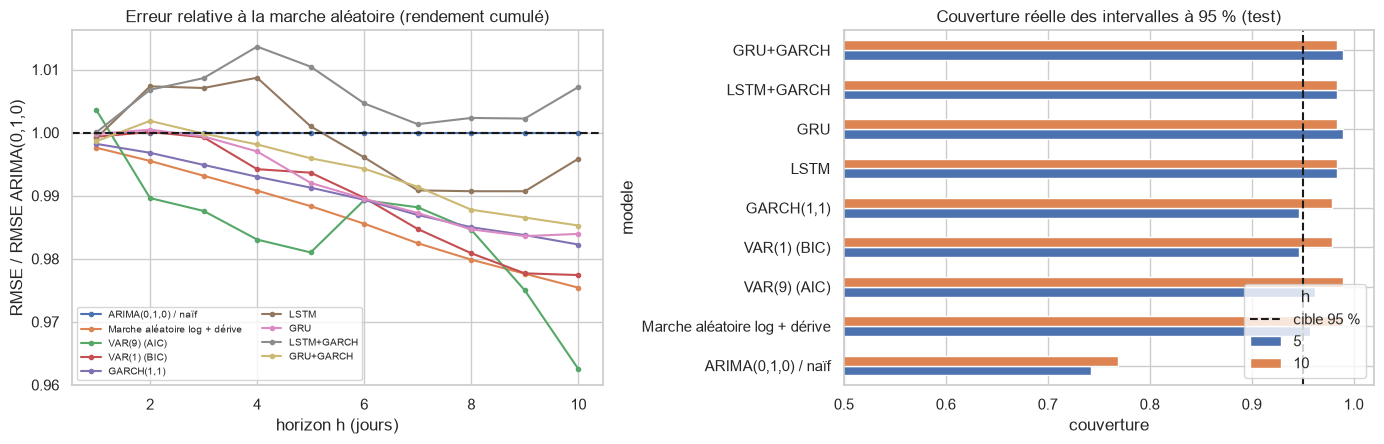

Lecture : un ratio < 1 signifie une erreur plus faible que la marche aléatoire ; une couverture < 95 % signifie un intervalle trop optimiste (trop étroit).


In [158]:
# === Graphiques d'évaluation ==========================================================
piv = res.pivot(index="h", columns="modele", values="RMSE_cum")[list(MODELS)]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
(piv.div(piv[REF], axis=0)).plot(ax=ax[0], marker="o", ms=3)
ax[0].axhline(1, color="k", ls="--"); ax[0].set_ylabel("RMSE / RMSE ARIMA(0,1,0)"); ax[0].set_xlabel("horizon h (jours)")
ax[0].set_title("Erreur relative à la marche aléatoire (rendement cumulé)"); ax[0].legend(fontsize=7, ncol=2)
cov = res[res.h.isin([5, 10])].pivot(index="modele", columns="h", values="couverture").reindex(list(MODELS))
cov.plot.barh(ax=ax[1]); ax[1].axvline(1 - ALPHA, color="k", ls="--", label="cible 95 %"); ax[1].set_xlim(0.5, 1.02)
ax[1].set_title("Couverture réelle des intervalles à 95 % (test)"); ax[1].set_xlabel("couverture"); ax[1].legend(title="h")
plt.tight_layout(); plt.show()
print("Lecture : un ratio < 1 signifie une erreur plus faible que la marche aléatoire ; une couverture < 95 % signifie un intervalle trop optimiste (trop étroit).")

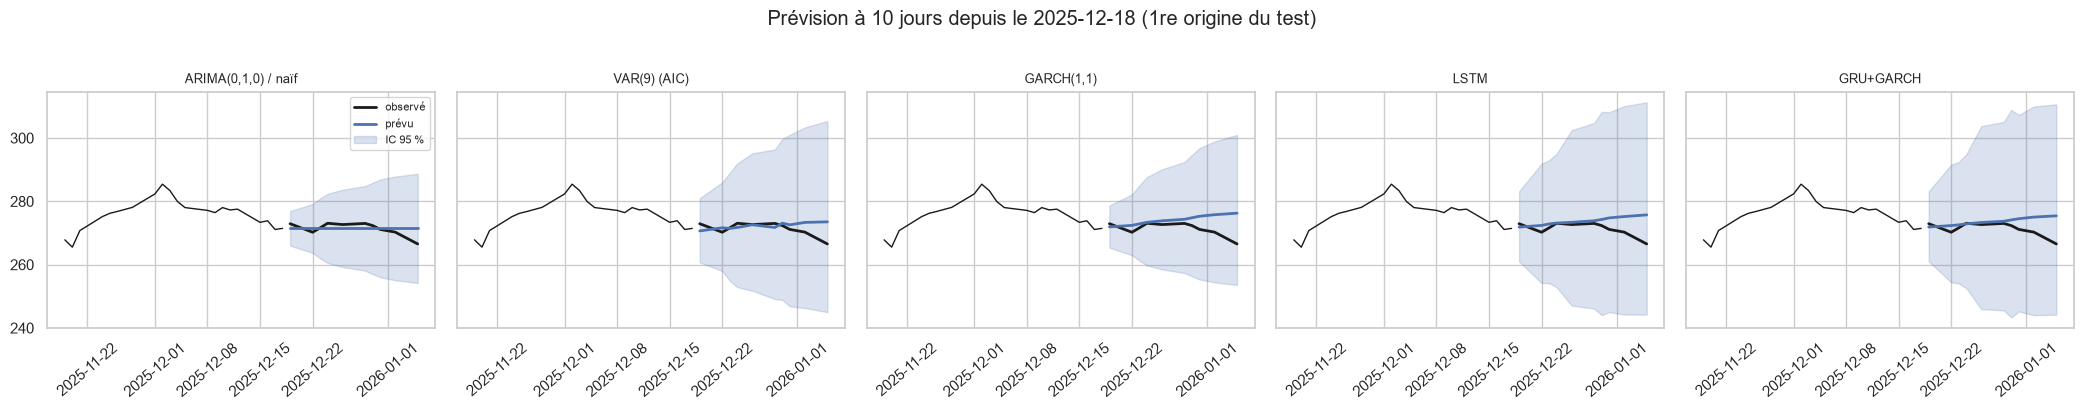

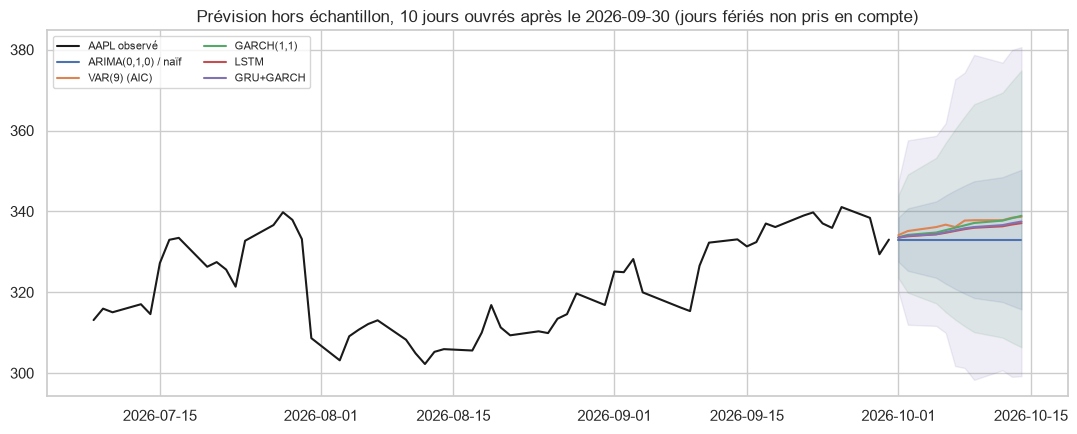

,J+1,J+2,J+3,J+4,J+5,J+6,J+7,J+8,J+9,J+10
"ARIMA(0,1,0) / naïf",333.02,333.02,333.02,333.02,333.02,333.02,333.02,333.02,333.02,333.02
Marche aléatoire log + dérive,333.39,333.77,334.14,334.51,334.89,335.26,335.64,336.01,336.39,336.76
VAR(9) (AIC),334.13,335.14,336.13,336.72,336.14,337.73,337.82,337.82,338.44,338.67
VAR(1) (BIC),333.32,333.74,334.14,334.54,334.93,335.33,335.73,336.13,336.53,336.93
"GARCH(1,1)",333.60,334.19,334.78,335.36,335.95,336.54,337.13,337.72,338.32,338.91
LSTM,333.52,333.84,334.33,334.71,335.16,335.60,335.95,336.31,336.75,337.09
GRU,333.49,333.98,334.38,334.80,335.18,335.64,336.02,336.49,336.98,337.53
LSTM+GARCH,333.56,333.86,334.34,334.84,335.45,335.89,336.32,336.75,337.17,337.54
GRU+GARCH,333.47,333.99,334.35,334.88,335.33,335.81,336.13,336.60,337.08,337.49


Modèles non ré-ajustés après le train : prévision « telle qu'évaluée ». En production, on les ré-estimerait régulièrement.


In [159]:
# === Éventails de prévision (fan charts) à partir de la 1re origine du test et à partir de la dernière date ===
show = [REF, f"VAR({p_aic}) (AIC)", "GARCH(1,1)", "LSTM", "GRU+GARCH"]
show = [m for m in show if m in MODELS]
i0 = 0; o0 = ORIG[i0]; days = dates[o0 + 1:o0 + H + 1]
fig, ax = plt.subplots(1, len(show), figsize=(4.2 * len(show), 4), sharey=True)
for a, nm in zip(np.atleast_1d(ax), show):
    m = MODELS[nm]
    a.plot(dates[o0 - 20:o0 + 1], PX[o0 - 20:o0 + 1], "k", lw=1); a.plot(days, P_fut[i0], "k", lw=2, label="observé")
    a.plot(days, P_o[i0] * np.exp(m["R"][i0]), "C0", lw=2, label="prévu"); a.fill_between(days, m["lo"][i0], m["hi"][i0], color="C0", alpha=.2, label="IC 95 %")
    a.set_title(nm, fontsize=9); a.tick_params(axis="x", rotation=40)
np.atleast_1d(ax)[0].legend(fontsize=8); plt.suptitle(f"Prévision à 10 jours depuis le {dates[o0].date()} (1re origine du test)", y=1.02); plt.tight_layout(); plt.show()

# Prévision hors échantillon : les 10 jours ouvrés qui suivent la dernière date des données
fut = pd.bdate_range(dates[-1] + pd.Timedelta(days=1), periods=H)
fig, a = plt.subplots(figsize=(11, 4.5))
a.plot(dates[-60:], PX[-60:], "k", lw=1.5, label="AAPL observé")
for nm, c in zip(show, ["C0", "C1", "C2", "C3", "C4"]):
    m = MODELS[nm]; a.plot(fut, PX[-1] * np.exp(m["R_fwd"]), c, lw=1.5, label=nm)
    if nm in (REF, "GARCH(1,1)", "GRU+GARCH"): a.fill_between(fut, m["lo_fwd"], m["hi_fwd"], color=c, alpha=.12)
a.set_title(f"Prévision hors échantillon, 10 jours ouvrés après le {dates[-1].date()} (jours fériés non pris en compte)"); a.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()
fwd = pd.DataFrame({nm: dict(zip([f"J+{h}" for h in range(1, H + 1)], np.round(PX[-1] * np.exp(m["R_fwd"]), 2))) for nm, m in MODELS.items()}).T
fwd.to_csv(f"{OUT_DIR}/forecast_forward_part6.csv"); display(fwd)
print("Modèles non ré-ajustés après le train : prévision « telle qu'évaluée ». En production, on les ré-estimerait régulièrement.")

## 6.4 — Choix du meilleur modèle selon le cas d'usage

L'énoncé demande de conclure **en tenant compte non seulement de la performance mais aussi de l'interprétabilité et du coût de calcul**. Trois cas d'usage différents ne conduisent pas forcément au même modèle :

1. **Prévision ponctuelle du prix à 5-10 jours** → critère : RMSE du rendement cumulé, *à condition que l'écart avec la marche aléatoire soit statistiquement significatif* ; sinon on garde le modèle le plus simple.
2. **Mesure du risque / gestion de l'incertitude** → critère : intervalles bien calibrés (couverture proche de 95 %) et score de Winkler faible.
3. **Explication à un décideur** → critère : interprétabilité (on peut dire *pourquoi* le modèle prévoit cela).

L'interprétabilité (échelle 1-5) est un **jugement de l'équipe**, pas une mesure : ARIMA / marche aléatoire (5 : une formule), VAR et GARCH (4 : coefficients lisibles, effets de retards et de volatilité), réseaux (2 : boîte grise).

In [160]:
# === Tableau de décision : performance × significativité × coût × interprétabilité ===
INTERP = {REF: 5, "Marche aléatoire log + dérive": 5, "GARCH(1,1)": 4, "LSTM": 2, "GRU": 2, "LSTM+GARCH": 2, "GRU+GARCH": 2}
for nm in MODELS: INTERP.setdefault(nm, 4 if nm.startswith("VAR") else 2)
h_mid = res[res.h.between(5, 10)]
g = h_mid.groupby("modele")
dec = pd.DataFrame({
    "RMSE_cum relatif (h=5..10)": (g["RMSE_cum"].mean() / g["RMSE_cum"].mean()[REF]),
    "signif. meilleur (h=5 ou 10)": res[res.h.isin([5, 10])].assign(ok=lambda d: (d.p_DM_cum < 0.05) & (d.DM_cum < 0)).groupby("modele")["ok"].any(),
    "signif. meilleur que RW+dérive (h=5 ou 10)": res[res.h.isin([5, 10])].assign(ok=lambda d: (d.p_DM_vs_derive < 0.05) & (d.DM_vs_derive < 0)).groupby("modele")["ok"].any(),
    "écart couverture/95 % (h=5,10)": res[res.h.isin([5, 10])].assign(e=lambda d: (d.couverture - (1 - ALPHA)).abs()).groupby("modele")["e"].mean(),
    "Winkler moyen (h=5..10)": g["winkler"].mean(),
    "paramètres": pd.Series({k: m["n_params"] for k, m in MODELS.items()}),
    "temps d'ajustement (s)": pd.Series({k: m["fit_time"] for k, m in MODELS.items()}),
    "interprétabilité (1-5)": pd.Series(INTERP)}).reindex(list(MODELS))
display(dec.round(4))
dec.to_csv(f"{OUT_DIR}/decision_matrix_part6.csv")

# --- Verdict automatique (à reprendre dans le rapport avec VOS chiffres) ---
cand = [m for m in dec.index if m != REF and dec.loc[m, "signif. meilleur (h=5 ou 10)"]]
print("\n● CAS 1 — prévision ponctuelle à 5-10 jours")
if cand:
    b = min(cand, key=lambda m: dec.loc[m, "RMSE_cum relatif (h=5..10)"])
    rel, npar, tfit, interp = dec.loc[b, "RMSE_cum relatif (h=5..10)"], dec.loc[b, "paramètres"], dec.loc[b, "temps d'ajustement (s)"], dec.loc[b, "interprétabilité (1-5)"]
    print(f"  {b} bat significativement ARIMA(0,1,0) (Diebold-Mariano, α=5 %) avec une erreur relative de {rel:.3f} ; coût : {npar:.0f} paramètres, {tfit:.0f} s ; interprétabilité {interp}/5.")
    if b != REF2 and not dec.loc[b, "signif. meilleur que RW+dérive (h=5 ou 10)"]:
        print("  ⚠ mais il ne bat PAS significativement la marche aléatoire avec dérive : son avantage sur le naïf vient surtout de la dérive moyenne (rendement positif de la période).")
else:
    simple = [m for m in dec.index if dec.loc[m, "interprétabilité (1-5)"] == 5]
    b_s = min(simple, key=lambda m: dec.loc[m, "RMSE_cum relatif (h=5..10)"]); rel_s = dec.loc[b_s, "RMSE_cum relatif (h=5..10)"]
    best_raw = dec["RMSE_cum relatif (h=5..10)"].idxmin(); rel_b = dec.loc[best_raw, "RMSE_cum relatif (h=5..10)"]
    print(f"  Aucun modèle ne bat significativement ARIMA(0,1,0). Plus faible RMSE brut : {best_raw} ({rel_b:.3f} × la référence), écart non significatif.")
    print(f"  → on retient le modèle le plus simple (interprétabilité 5/5) à plus faible erreur : {b_s} ({rel_s:.3f} × la référence).")
print("\n● CAS 2 — mesure de l'incertitude")
ok_int = dec.dropna(subset=["écart couverture/95 % (h=5,10)"])
b2 = ok_int["écart couverture/95 % (h=5,10)"].idxmin(); b3 = ok_int["Winkler moyen (h=5..10)"].idxmin()
print(f"  Couverture la plus proche de 95 % : {b2} (écart moyen {ok_int.loc[b2, 'écart couverture/95 % (h=5,10)']:.3f}) ; plus faible score de Winkler : {b3} ({ok_int.loc[b3, 'Winkler moyen (h=5..10)']:.2f}).")
print("\n● CAS 3 — explication à un décideur : modèles les plus interprétables et dont les performances ne sont pas significativement pires :")
print("  ", [m for m in dec.index if dec.loc[m, "interprétabilité (1-5)"] >= 4])

,RMSE_cum relatif (h=5..10),signif. meilleur (h=5 ou 10),signif. meilleur que RW+dérive (h=5 ou 10),"écart couverture/95 % (h=5,10)",Winkler moyen (h=5..10),paramètres,temps d'ajustement (s),interprétabilité (1-5)
"ARIMA(0,1,0) / naïf",1.0000,False,False,0.1946,91.7255,1,0.0154,5
Marche aléatoire log + dérive,0.9811,False,False,0.0231,61.8276,2,0.0000,5
VAR(9) (AIC),0.9794,False,False,0.0258,57.0376,38,0.0046,4
VAR(1) (BIC),0.9834,False,False,0.0161,59.8844,6,0.0034,4
"GARCH(1,1)",0.9861,False,False,0.0161,57.2086,4,0.0116,4
LSTM,0.9940,False,False,0.0339,66.5999,4938,10.4816,2
GRU,0.9865,False,False,0.0366,66.3574,3882,26.0423,2
LSTM+GARCH,1.0046,False,False,0.0339,67.3749,5066,41.9688,2
GRU+GARCH,0.9898,False,False,0.0366,67.0395,3978,43.5656,2



● CAS 1 — prévision ponctuelle à 5-10 jours
  Aucun modèle ne bat significativement ARIMA(0,1,0). Plus faible RMSE brut : VAR(9) (AIC) (0.979 × la référence), écart non significatif.
  → on retient le modèle le plus simple (interprétabilité 5/5) à plus faible erreur : Marche aléatoire log + dérive (0.981 × la référence).

● CAS 2 — mesure de l'incertitude
  Couverture la plus proche de 95 % : VAR(1) (BIC) (écart moyen 0.016) ; plus faible score de Winkler : VAR(9) (AIC) (57.04).

● CAS 3 — explication à un décideur : modèles les plus interprétables et dont les performances ne sont pas significativement pires :
   ['ARIMA(0,1,0) / naïf', 'Marche aléatoire log + dérive', 'VAR(9) (AIC)', 'VAR(1) (BIC)', 'GARCH(1,1)']


### Comment rédiger la conclusion de la partie 6 (avec VOS chiffres)

1. **Ce que les chiffres montrent** : citer, pour h = 5 et h = 10, le RMSE du rendement cumulé de chaque famille (économétrique, réseau, hybride) **relatif à la marche aléatoire**, et les p-values du Diebold-Mariano. Rapporter les résultats non significatifs tels quels.
2. **L'horizon** : l'erreur croît avec $h$ (≈ $\sqrt h$ pour une marche aléatoire) ; si l'écart relatif d'un modèle se réduit ou s'amplifie avec $h$, le dire (premier graphique).
3. **Les intervalles** : ARIMA(0,1,0) estime une variance **constante en dollars** alors que le prix a plus que doublé sur la période → ses intervalles sont structurellement mal calibrés (comparer sa couverture à celle de la marche aléatoire *en log*). Le GARCH adapte la largeur à la volatilité du moment ; les réseaux conformaux ont une largeur **fixe** par horizon (honnête en moyenne, pas en période de crise).
4. **Le cas d'usage tranche** : à performance ponctuelle statistiquement égale, on choisit le modèle simple pour la prévision et un modèle de volatilité (GARCH) pour le risque ; un réseau n'est justifié que s'il gagne **significativement** — ce qu'on ne peut pas affirmer sans le test.
5. **Limites** (critère « honnêteté scientifique ») : une seule période de test (195 jours, marché haussier), paramètres non ré-estimés au fil du temps, intervalles du GARCH gaussiens, calibration conformale légèrement optimiste, peu d'observations indépendantes à h = 10.

# Partie 7 — Extensions (bonus)

Trois extensions de l'énoncé, adaptées à la finance (AAPL / QQQ) :

| Extension | Question posée | Méthode |
|---|---|---|
| **7.1 Variables exogènes** | Des informations *extérieures* à la série (volumes, VIX, taux à 10 ans) améliorent-elles la prévision ? | stationnarité, causalité de Granger, puis réseaux avec ces variables **dans le même protocole d'évaluation que la partie 6** |
| **7.2 Corrélation dynamique** | La relation AAPL–QQQ est-elle stable dans le temps ? Quelle utilité pratique ? | corrélation glissante, **DCC-GARCH** (implémenté ici), **ratio de couverture dynamique** |
| **7.3 Événements et ruptures** | Les ruptures observées correspondent-elles à des événements connus ? Le texte (actualités) les signale-t-il ? | **régimes de Markov**, jours extrêmes, calendrier d'événements, **sentiment FinBERT** (si un corpus est fourni) |

**Honnêteté sur les dépendances externes** : le VIX et les taux viennent de Yahoo Finance (téléchargement, puis cache `../data/data_exog.csv`) ; s'ils sont indisponibles, **le notebook continue avec les seuls volumes** (déjà dans votre CSV) et le dit. Le corpus d'actualités (`../data/news.csv`) n'est pas fourni : sans lui, la partie texte est ignorée proprement.

## 7.1 — Variables exogènes

**Variables candidates** (toutes transformées pour être stationnaires, puis testées) :
| Variable | Transformation | Pourquoi on peut l'espérer utile |
|---|---|---|
| Volume AAPL, volume QQQ (dans votre CSV) | $\Delta\ln(\text{volume})$ | l'activité accompagne les phases d'information et de stress |
| **VIX** (volatilité implicite du S&P 500) | $\Delta\ln(\text{VIX})$ | mesure de la peur du marché, liée à la volatilité future |
| **Taux 10 ans américain** (`^TNX`) | $\Delta$ taux | les valeurs technologiques sont sensibles aux taux (les articles de presse de 2026 les citent dans les corrections) |

**Précaution de calendrier (pas de fuite)** : à la date $t$, on connaît la clôture du VIX **de $t$**. Le VIX et le rendement d'AAPL du même jour sont très corrélés (**corrélation contemporaine**), mais cela ne sert à rien pour prévoir : seule la corrélation **décalée** ($x_t$ avec $r_{t+1}$) est exploitable. Le tableau ci-dessous sépare les deux pour que la différence soit visible.

In [161]:
# === 7.1 — Construction des variables exogènes ========================================
def load_exog(csv_path=EXOG_PATH):
    """VIX et taux 10 ans : cache CSV si présent, sinon téléchargement Yahoo Finance (puis mise en cache). None si impossible."""
    if os.path.exists(csv_path):
        return pd.read_csv(csv_path, index_col=0, parse_dates=True), f"cache {csv_path}"
    try:
        import yfinance as yf
        d = yf.download(["^VIX", "^TNX"], start="2019-01-01", end="2026-10-01", auto_adjust=False, progress=False)["Close"]
        ex = d.rename(columns={"^VIX": "VIX", "^TNX": "TNX"})[["VIX", "TNX"]].dropna(how="all")
        if ex.empty: raise ValueError("téléchargement vide")
        ex.to_csv(csv_path); return ex, "téléchargement Yahoo Finance (mis en cache)"
    except Exception as e:
        return None, f"indisponible ({type(e).__name__}) — extension limitée aux volumes"

exog = pd.DataFrame(index=dataset.index)
exog["dlogvol_AAPL"] = np.log(volume["AAPL"].replace(0, np.nan)).diff()
exog["dlogvol_QQQ"] = np.log(volume["QQQ"].replace(0, np.nan)).diff()
ex_raw, ex_src = load_exog()
print("VIX / taux 10 ans :", ex_src)
if ex_raw is not None:
    ex_raw = ex_raw.sort_index().reindex(dataset.index, method="ffill", limit=3)        # même calendrier que les prix
    exog["dlogVIX"] = np.log(ex_raw["VIX"]).diff()
    exog["dTNX"] = ex_raw["TNX"].diff()
exog = exog.replace([np.inf, -np.inf], np.nan)
print("variables exogènes :", list(exog.columns), "| valeurs manquantes :", exog.isna().sum().to_dict())

VIX / taux 10 ans : cache ../data/data_exog.csv
variables exogènes : ['dlogvol_AAPL', 'dlogvol_QQQ', 'dlogVIX', 'dTNX'] | valeurs manquantes : {'dlogvol_AAPL': 1, 'dlogvol_QQQ': 1, 'dlogVIX': 1, 'dTNX': 1}


In [162]:
# === 7.1 — Stationnarité, corrélations (contemporaine vs décalée) et causalité de Granger =======
def granger_min_p(y, x, maxlag=5):
    """Test de Granger « x cause y » pour 1…maxlag retards (F-test) ; renvoie la plus petite p-value et son retard."""
    d = pd.concat([y, x], axis=1).dropna()
    with contextlib.redirect_stdout(io.StringIO()):
        out = grangercausalitytests(d, maxlag=maxlag)
    ps = [out[l][0]["ssr_ftest"][1] for l in range(1, maxlag + 1)]
    return min(ps), int(np.argmin(ps)) + 1

tr_idx = dataset.index <= train_end                                  # diagnostics sur le TRAIN uniquement
r_t = dataset["AAPL_Return"]
rows = []
for c in exog.columns:
    x = exog[c]; xt, rt, rn = x[tr_idx], r_t[tr_idx], r_t.shift(-1)[tr_idx]
    p_g, lag = granger_min_p(rt, xt)
    rows.append(dict(variable=c, ADF_p=adfuller(xt.dropna())[1], corr_meme_jour=xt.corr(rt), corr_decalee_t_vers_t1=xt.corr(rn),
                     Granger_p_min=p_g, retard=lag, Granger_p_Bonferroni=min(1.0, p_g * 5)))
exo_tab = pd.DataFrame(rows).set_index("variable")
display(exo_tab.round(4))
print("Lecture : ADF_p ≪ 0.05 → stationnaire (transformation correcte). corr_meme_jour est élevée en valeur absolue pour le VIX (mouvements simultanés), "
      "mais seule corr_decalee / Granger compte pour PRÉVOIR. Bonferroni corrige le fait d'avoir testé 5 retards.")

,ADF_p,corr_meme_jour,corr_decalee_t_vers_t1,Granger_p_min,retard,Granger_p_Bonferroni
variable,,,,,,
dlogvol_AAPL,0.0,-0.0501,0.0032,0.9156,5,1.0000
dlogvol_QQQ,0.0,-0.1668,-0.0191,0.1575,1,0.7877
dlogVIX,0.0,-0.5682,0.0397,0.1611,3,0.8054
dTNX,0.0,0.0724,-0.0415,0.1375,1,0.6877


Lecture : ADF_p ≪ 0.05 → stationnaire (transformation correcte). corr_meme_jour est élevée en valeur absolue pour le VIX (mouvements simultanés), mais seule corr_decalee / Granger compte pour PRÉVOIR. Bonferroni corrige le fait d'avoir testé 5 retards.


### Les variables exogènes améliorent-elles la prévision ? (même protocole que la partie 6)
On ajoute les variables exogènes aux entrées des réseaux (LSTM, GRU) — mêmes hyper-paramètres, même évaluation à origine glissante, mêmes 186 origines — et on compare **chaque réseau à son jumeau sans exogènes** par Diebold-Mariano. C'est une **étude d'ablation** : toute différence vient des variables ajoutées.

In [163]:
# === 7.1 — Réseaux avec variables exogènes + ablation =================================
FEAT_X = list(exog.columns)
Fx = np.column_stack([F, exog.loc[dates, FEAT_X].fillna(0.0).values])       # colonne 0 = cible, puis volatilité, puis exogènes (normalisées sur le train)
for kind in ["LSTM", "GRU"]:
    HIST[f"{kind}+exog"] = train_multi(f"{kind}+exog", kind, Fx)

res = evaluate_all(MODELS)
rows = []
for kind in ["LSTM", "GRU"]:
    for h in [1, 5, 10]:
        e_x = R_act[:, h - 1] - MODELS[f"{kind}+exog"]["R"][:, h - 1]; e_b = R_act[:, h - 1] - MODELS[kind]["R"][:, h - 1]
        dm, p = diebold_mariano(e_x, e_b, h=h)
        rows.append(dict(modele=f"{kind}+exog vs {kind}", h=h, RMSE_cum_base=np.sqrt(np.mean(e_b**2)), RMSE_cum_exog=np.sqrt(np.mean(e_x**2)),
                         variation_relative=np.sqrt(np.mean(e_x**2)) / np.sqrt(np.mean(e_b**2)) - 1, DM=dm, p_DM=p, verdict=verdict(dm, p)))
abl = pd.DataFrame(rows); display(abl.round(4))
display(res[res.modele.str.contains("exog") & res.h.isin([1, 5, 10])].set_index(["modele", "h"])[["MSE", "RMSE", "MAE", "MAPE", "RMSE_cum", "p_DM_cum", "couverture", "winkler"]].round(4))
res.to_csv(f"{OUT_DIR}/results_part6_7_all_horizons.csv", index=False); abl.to_csv(f"{OUT_DIR}/ablation_exog_part7.csv", index=False)

LSTM+exog    W=20 unités=32 |  5450 paramètres |    45 s (3 graines) | demi-largeur conformale h=1/5/10 : [0.0404 0.102  0.1267]
GRU+exog     W=10 unités=32 |  4266 paramètres |    85 s (3 graines) | demi-largeur conformale h=1/5/10 : [0.0419 0.0999 0.1265]


,modele,h,RMSE_cum_base,RMSE_cum_exog,variation_relative,DM,p_DM,verdict
0,LSTM+exog vs LSTM,1,0.0168,0.0168,0.0020,1.0074,0.3150,différence non significative
1,LSTM+exog vs LSTM,5,0.0383,0.0389,0.0146,2.4508,0.0152,significativement MOINS BON
2,LSTM+exog vs LSTM,10,0.0519,0.0528,0.0177,2.0680,0.0400,significativement MOINS BON
3,GRU+exog vs GRU,1,0.0168,0.0169,0.0081,1.6338,0.1040,différence non significative
4,GRU+exog vs GRU,5,0.0380,0.0381,0.0034,0.4383,0.6617,différence non significative
5,GRU+exog vs GRU,10,0.0513,0.0514,0.0027,0.2421,0.8090,différence non significative


MSE     RMSE      MAE    MAPE  RMSE_cum  p_DM_cum  couverture  winkler
modele    h                                                                              
LSTM+exog 1    23.8658   4.8853   3.4581  1.2038    0.0168    0.8788      0.9785  28.3010
          5   129.5103  11.3803   8.8116  3.0630    0.0389    0.6282      0.9839  60.7835
          10  238.6753  15.4491  12.7826  4.4361    0.0528    0.8411      0.9839  74.6622
GRU+exog  1    24.1931   4.9186   3.4820  1.2117    0.0169    0.3582      0.9785  28.9449
          5   124.5211  11.1589   8.7247  3.0293    0.0381    0.8760      0.9839  59.2335
          10  226.4814  15.0493  12.4899  4.3301    0.0514    0.8408      0.9946  73.6434

**Comment interpréter** : une `variation_relative` négative et un `p_DM` < 0.05 signifient que les variables exogènes **améliorent significativement** le réseau. Si le Granger ne détecte rien (tableau précédent) et que l'ablation n'est pas significative, la conclusion honnête est que **ces variables ne contiennent pas d'information exploitable à ces horizons** — ce qui est un résultat, pas un échec. Deux réserves à écrire dans le rapport : (1) le VIX et AAPL partagent le même marché, d'où une information déjà largement présente dans le rendement de QQQ ; (2) tester plusieurs variables augmente le risque de faux positif (d'où la correction de Bonferroni).

## 7.2 — Corrélation dynamique AAPL–QQQ : glissante et DCC-GARCH

**Pourquoi une corrélation dynamique ?** La corrélation entre une action et son indice n'est pas constante : elle **monte en période de stress** (tout baisse ensemble — perte de la diversification) et baisse quand les nouvelles propres à l'entreprise dominent. Une corrélation unique sur 7 ans cache cela.

**Deux estimateurs**
1. **Corrélation glissante sur 60 jours** : simple, mais bruitée et retardée (60 jours de mémoire à poids égaux).
2. **DCC-GARCH** (Engle, 2002), **implémenté ici** (le paquet `arch` ne l'offre pas) en deux étapes :
   - *Étape 1* : un GARCH(1,1) par série (celui de l'équipe pour AAPL, un second pour QQQ) → résidus standardisés $z_t=\varepsilon_t/\sigma_t$ (volatilités **figées sur le train**, pas de fuite) ;
   - *Étape 2* : $Q_t=(1-a-b)\bar Q + a\,z_{t-1}z_{t-1}' + b\,Q_{t-1}$, $\rho_t=q_{12,t}/\sqrt{q_{11,t}q_{22,t}}$, avec $a,b\ge 0$, $a+b<1$ estimés **sur le train** par maximum de vraisemblance. Comme pour un GARCH, $a$ mesure la réaction aux chocs récents et $a+b$ la persistance.

$\rho_t$ n'utilise que des données **antérieures à $t$** : il est utilisable en temps réel.

In [164]:
# === 7.2 — Résidus standardisés des deux GARCH (volatilités figées sur le train) ==========
garch_q = arch_model(train["QQQ_Return"].dropna() * 100, mean="Constant", vol="GARCH", p=1, q=1).fit(disp="off")
fixed_q = arch_model(returns["QQQ"] * 100, mean="Constant", vol="GARCH", p=1, q=1).fix(garch_q.params)
sig_a, sig_q = garch_fixed.conditional_volatility, fixed_q.conditional_volatility           # σ_t (en %), connus dès t-1
z_a = (returns["AAPL"] * 100 - garch_res.params["mu"]) / sig_a
z_q = (returns["QQQ"] * 100 - garch_q.params["mu"]) / sig_q
Z = pd.concat([z_a, z_q], axis=1, keys=["AAPL", "QQQ"]).dropna()
n_tr = int((Z.index <= train_end).sum()); Ztr = Z.values[:n_tr]
print(f"QQQ GARCH(1,1) : alpha={garch_q.params['alpha[1]']:.4f} beta={garch_q.params['beta[1]']:.4f} | résidus standardisés : n = {len(Z)} (train {n_tr})")

# === Estimation du DCC (Engle 2002) par maximum de vraisemblance sur le train =========
def dcc_rho(z, a, b, Qbar):
    """Corrélation conditionnelle ρ_t (récursion de Q_t) ; ρ_t ne dépend que de z_{t-1}, z_{t-2}, …"""
    n = len(z); q11, q12, q22 = Qbar[0, 0], Qbar[0, 1], Qbar[1, 1]; rho = np.empty(n)
    for t in range(n):
        if t > 0:
            q11 = (1 - a - b) * Qbar[0, 0] + a * z[t - 1, 0]**2 + b * q11
            q12 = (1 - a - b) * Qbar[0, 1] + a * z[t - 1, 0] * z[t - 1, 1] + b * q12
            q22 = (1 - a - b) * Qbar[1, 1] + a * z[t - 1, 1]**2 + b * q22
        rho[t] = q12 / np.sqrt(q11 * q22)
    return rho

def corr_nll(z, rho):
    """Moins la log-vraisemblance de la partie « corrélation » (les termes de variance sont constants en (a, b))."""
    rho = np.clip(rho, -0.9999, 0.9999)
    return 0.5 * np.sum(np.log(1 - rho**2) + (z[:, 0]**2 + z[:, 1]**2 - 2 * rho * z[:, 0] * z[:, 1]) / (1 - rho**2))

Qbar = np.corrcoef(Ztr.T)
obj = lambda p: corr_nll(Ztr, dcc_rho(Ztr, p[0], p[1], Qbar))
opt = minimize(obj, x0=[0.03, 0.95], method="SLSQP", bounds=[(1e-4, 0.5), (0.3, 0.9999)],
               constraints=[{"type": "ineq", "fun": lambda p: 0.9995 - p[0] - p[1]}])
a_dcc, b_dcc = opt.x
rho_dcc = pd.Series(dcc_rho(Z.values, a_dcc, b_dcc, Qbar), index=Z.index)                  # paramètres et Qbar du TRAIN, appliqués à toute la série
nll_dcc, nll_stat = opt.fun, corr_nll(Ztr, np.full(n_tr, Qbar[0, 1]))
print(f"DCC : a = {a_dcc:.4f}, b = {b_dcc:.4f}, a+b = {a_dcc + b_dcc:.4f} | convergence : {opt.success}")
print(f"log-vraisemblance (corrélation) : DCC = {-nll_dcc:.1f} contre corrélation constante ({Qbar[0, 1]:.3f}) = {-nll_stat:.1f}")
print(f"AIC : DCC = {4 + 2*nll_dcc:.1f} | constante = {2 + 2*nll_stat:.1f} → {'le DCC est préféré (AIC plus bas)' if 4 + 2*nll_dcc < 2 + 2*nll_stat else 'la corrélation constante suffit (AIC plus bas)'}")

QQQ GARCH(1,1) : alpha=0.1374 beta=0.8401 | résidus standardisés : n = 1946 (train 1751)
DCC : a = 0.0457, b = 0.9410, a+b = 0.9867 | convergence : True
log-vraisemblance (corrélation) : DCC = -938.9 contre corrélation constante (0.750) = -1032.1
AIC : DCC = 1881.8 | constante = 2066.2 → le DCC est préféré (AIC plus bas)


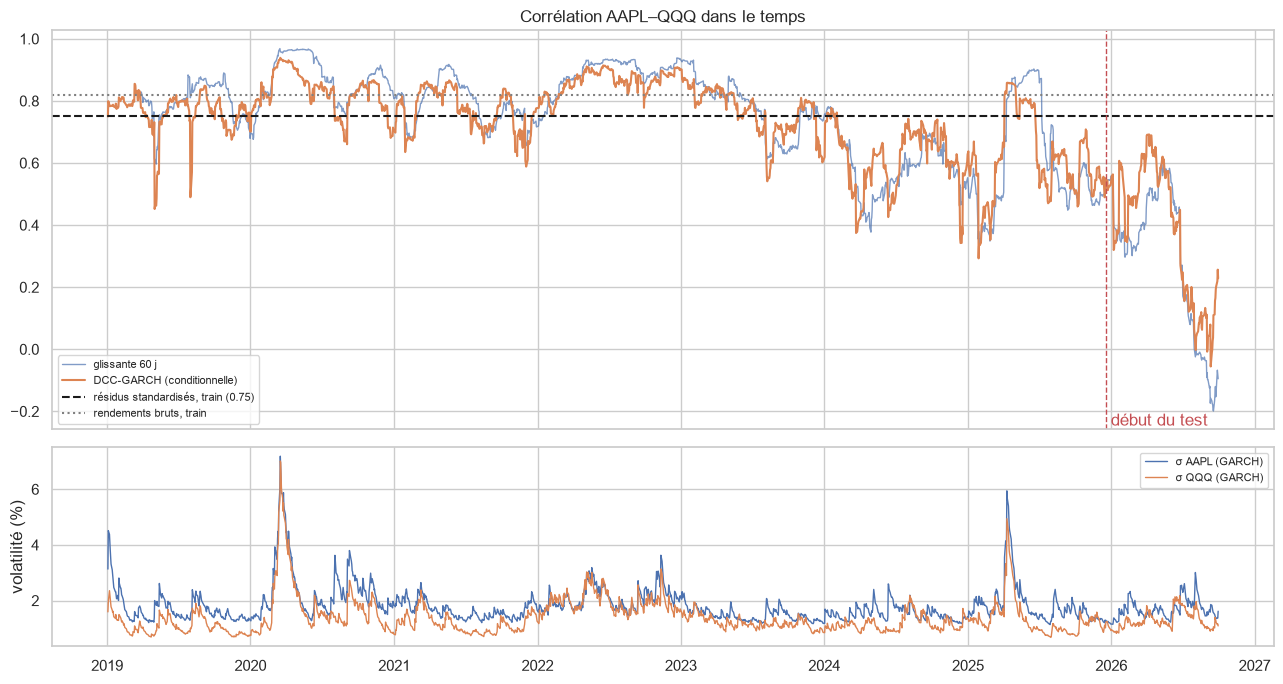

Corrélation de rang entre ρ_t (DCC) et la volatilité d'AAPL : 0.390 (p = 7.04e-72) → la corrélation augmente avec la volatilité (effet « crise : tout bouge ensemble »).
ρ_t DCC : min -0.056 | médiane 0.760 | max 0.939


In [165]:
# === 7.2 — Comparaison visuelle : constante / glissante 60 j / DCC ====================
roll60 = returns["AAPL"].rolling(60).corr(returns["QQQ"])
fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax[0].plot(roll60, lw=1, alpha=.7, label="glissante 60 j"); ax[0].plot(rho_dcc, lw=1.5, label="DCC-GARCH (conditionnelle)")
ax[0].axhline(Qbar[0, 1], color="k", ls="--", label=f"résidus standardisés, train ({Qbar[0, 1]:.2f})")
ax[0].axhline(returns.loc[returns.index <= train_end].corr().iloc[0, 1], color="gray", ls=":", label="rendements bruts, train")
ax[0].axvline(train_end, color="r", ls="--", lw=1); ax[0].text(train_end, ax[0].get_ylim()[0], " début du test", color="r", va="bottom")
ax[0].set_title("Corrélation AAPL–QQQ dans le temps"); ax[0].legend(fontsize=8, loc="lower left")
ax[1].plot(sig_a, lw=1, label="σ AAPL (GARCH)"); ax[1].plot(sig_q, lw=1, label="σ QQQ (GARCH)"); ax[1].set_ylabel("volatilité (%)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

common = pd.concat([rho_dcc, sig_a], axis=1, keys=["rho", "sig"]).dropna()
rs, ps = stats.spearmanr(common["rho"], common["sig"])
print(f"Corrélation de rang entre ρ_t (DCC) et la volatilité d'AAPL : {rs:.3f} (p = {ps:.2e}) → ", end="")
print("la corrélation augmente avec la volatilité (effet « crise : tout bouge ensemble »)." if rs > 0.1 else "pas de lien net corrélation–volatilité sur cet échantillon.")
print(f"ρ_t DCC : min {rho_dcc.min():.3f} | médiane {rho_dcc.median():.3f} | max {rho_dcc.max():.3f}")

### Application : le ratio de couverture dynamique
**Question pratique** : un gérant détient AAPL et veut se couvrir en vendant QQQ. Quelle quantité ? Le ratio optimal (minimisant la variance) est $\beta_t=\rho_t\,\sigma_{A,t}/\sigma_{Q,t}$. On compare, **sur le test uniquement**, le portefeuille couvert avec :
- un $\beta$ **statique** (régression sur le train),
- le $\beta_t$ **dynamique** du DCC (tous ses ingrédients sont connus la veille).

Critère : variance du rendement du portefeuille $r_A-\beta\,r_Q$ (plus faible = meilleure couverture), avec un Diebold-Mariano sur le carré des rendements couverts.

In [166]:
# === 7.2 — Couverture statique vs dynamique sur le TEST ================================
rA, rQ = returns["AAPL"] * 100, returns["QQQ"] * 100
beta_static = np.cov(rA[rA.index <= train_end], rQ[rQ.index <= train_end])[0, 1] / rQ[rQ.index <= train_end].var()
idx_te = Z.index[Z.index > train_end]
beta_dyn = (rho_dcc * sig_a / sig_q).reindex(idx_te)                      # β_t = ρ_t σ_A,t / σ_Q,t  (connu à t-1)
h_none, h_stat, h_dyn = rA.reindex(idx_te), rA.reindex(idx_te) - beta_static * rQ.reindex(idx_te), rA.reindex(idx_te) - beta_dyn * rQ.reindex(idx_te)
tab = pd.DataFrame({"variance des rendements (%²)": [h_none.var(), h_stat.var(), h_dyn.var()]},
                   index=["AAPL non couvert", f"couvert, β statique = {beta_static:.2f}", "couvert, β dynamique (DCC)"])
tab["réduction de variance"] = 1 - tab["variance des rendements (%²)"] / h_none.var()
display(tab.round(4))
dm, p = diebold_mariano(h_dyn.values, h_stat.values)
print(f"β dynamique : min {beta_dyn.min():.2f} | médiane {beta_dyn.median():.2f} | max {beta_dyn.max():.2f}")
print(f"Diebold-Mariano (β dynamique vs statique, carrés des rendements couverts) : DM = {dm:.3f}, p = {p:.3f} → {verdict(dm, p)}")
print("Lecture : la couverture dynamique n'a d'intérêt que si elle réduit significativement la variance par rapport au β fixe ; sinon la simplicité l'emporte.")
tab.to_csv(f"{OUT_DIR}/hedging_part7.csv")

,variance des rendements (%²),réduction de variance
AAPL non couvert,2.7538,0.0000
"couvert, β statique = 1.05",3.7203,-0.3509
"couvert, β dynamique (DCC)",2.6708,0.0301


β dynamique : min -0.11 | médiane 0.55 | max 0.99
Diebold-Mariano (β dynamique vs statique, carrés des rendements couverts) : DM = -4.830, p = 0.000 → significativement MEILLEUR
Lecture : la couverture dynamique n'a d'intérêt que si elle réduit significativement la variance par rapport au β fixe ; sinon la simplicité l'emporte.


## 7.3 — Événements, ruptures de régime et texte

**Objectif de l'énoncé** : relier des événements aux **ruptures observées**. Trois niveaux, du plus automatique au plus qualitatif :

1. **Détecter les ruptures sans connaître les événements** : modèle à **régimes de Markov** à deux états (calme / stress, avec une variance différente par état) sur les rendements d'AAPL. Les dates où l'on bascule vers l'état « stress » sont des ruptures de régime. *Usage descriptif* : les probabilités « lissées » utilisent tout l'échantillon (on regarde le passé avec le recul), ce n'est donc **pas** un signal de trading.
2. **Repérer les jours extrêmes** : plus grands résidus standardisés du GARCH (|z| élevé = choc inattendu *même compte tenu de la volatilité du moment*).
3. **Relier aux événements** : calendrier d'événements publics (ci-dessous) puis **rapprochement automatique** (± 4 jours calendaires) ; ce qui n'est pas expliqué est signalé « à documenter » plutôt que **inventé**.

La partie texte (FinBERT) vient ensuite, si vous fournissez un corpus.

Régime CALME : écart-type 1.31 %/jour | moyenne +0.172 % | durée moyenne 27 jours
Régime STRESS : écart-type 3.42 %/jour | moyenne -0.129 % | durée moyenne 7 jours
Part du temps en stress : 17.0%


,debut,fin,jours,rendement_cumule_pct,pire_jour_pct
0,2019-04-30,2019-05-14,11,-7.73,-5.99
1,2019-08-01,2019-08-15,11,-5.07,-5.38
2,2020-01-27,2020-02-04,7,0.17,-4.54
3,2020-02-21,2020-04-23,44,-15.24,-13.77
4,2020-07-23,2020-08-12,15,15.18,-4.66
5,2020-08-28,2020-10-13,32,-3.18,-8.34
6,2020-10-28,2020-11-06,8,1.95,-5.76
7,2021-01-04,2021-01-08,5,-0.48,-3.42
8,2021-01-20,2021-01-29,8,3.18,-3.81
9,2021-02-24,2021-03-10,11,-4.78,-4.26


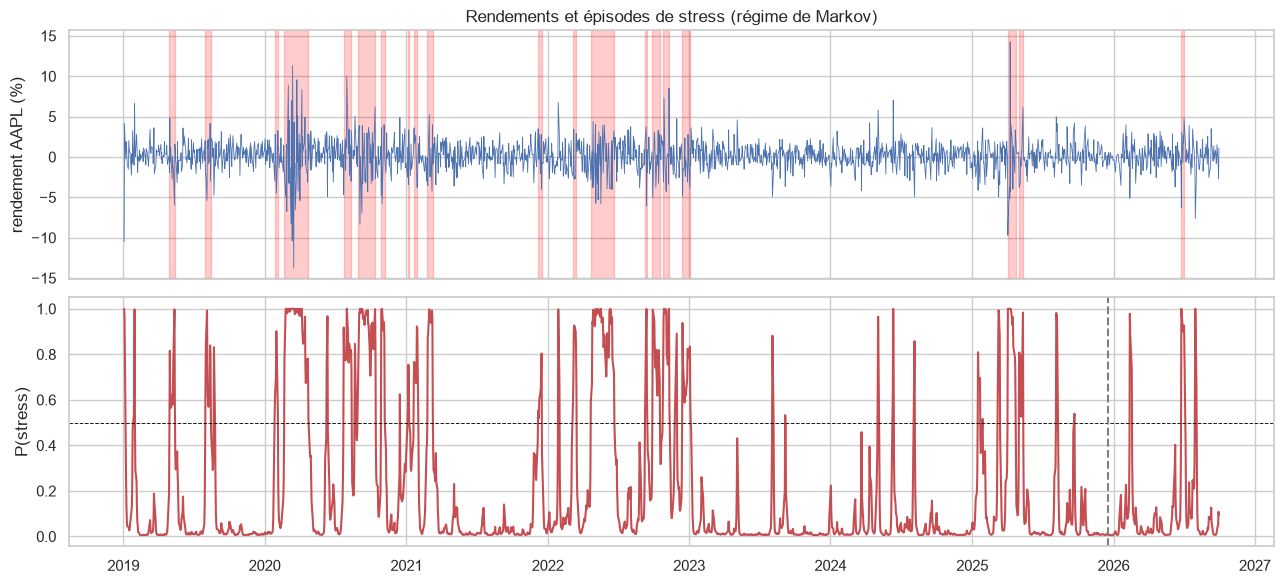

In [168]:
# === 7.3 — Régimes de Markov (calme / stress) sur les rendements d'AAPL ================
r_full = returns["AAPL"] * 100
try:
    ms = MarkovRegression(r_full, k_regimes=2, trend="c", switching_variance=True).fit(disp=False)
except Exception:
    ms = MarkovRegression(r_full, k_regimes=2, trend="c", switching_variance=True).fit(search_reps=10, disp=False)
par = ms.params
s2 = np.array([par["sigma2[0]"], par["sigma2[1]"]]); stress = int(np.argmax(s2)); calm = 1 - stress
p_stress = ms.smoothed_marginal_probabilities[stress]
dur = np.asarray(ms.expected_durations)
print(f"Régime CALME : écart-type {np.sqrt(s2[calm]):.2f} %/jour | moyenne {par[f'const[{calm}]']:+.3f} % | durée moyenne {dur[calm]:.0f} jours")
print(f"Régime STRESS : écart-type {np.sqrt(s2[stress]):.2f} %/jour | moyenne {par[f'const[{stress}]']:+.3f} % | durée moyenne {dur[stress]:.0f} jours")
print(f"Part du temps en stress : {(p_stress > 0.5).mean():.1%}")

# Épisodes de stress (≥ 5 jours consécutifs avec probabilité > 0.5 ; les épisodes plus courts sont du bruit)
s_bin = (p_stress > 0.5).astype(int); grp = (s_bin != s_bin.shift()).cumsum()
eps = []
for _, g_ in s_bin.groupby(grp):
    if g_.iloc[0] == 1 and len(g_) >= 5:
        d0, d1 = g_.index[0], g_.index[-1]
        eps.append(dict(debut=d0, fin=d1, jours=len(g_), rendement_cumule_pct=float(r_full.loc[d0:d1].sum()), pire_jour_pct=float(r_full.loc[d0:d1].min())))
episodes = pd.DataFrame(eps)
display(episodes.round(2))

fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax[0].plot(r_full, lw=.6); ax[0].set_ylabel("rendement AAPL (%)"); ax[0].set_title("Rendements et épisodes de stress (régime de Markov)")
for _, e in episodes.iterrows(): ax[0].axvspan(e.debut, e.fin, color="red", alpha=.2)
ax[1].plot(p_stress, color="C3"); ax[1].axhline(0.5, color="k", ls="--", lw=.7); ax[1].set_ylabel("P(stress)"); ax[1].axvline(train_end, color="gray", ls="--")
plt.tight_layout(); plt.show()

In [169]:
# === 7.3 — Jours extrêmes, calendrier d'événements et rapprochement ====================
# Calendrier d'événements PUBLICS. Confiance « haute » = date et ampleur bien établies ; « à sourcer » = date approximative issue de la presse financière :
# À VÉRIFIER ET CITER avec une source avant de l'utiliser dans le rapport.
EVENTS = pd.DataFrame([
    ("2019-01-03", "Apple abaisse sa prévision de chiffre d'affaires (AAPL ≈ -10 %)", "haute"),
    ("2020-03-16", "Krach COVID-19 : pire séance (AAPL ≈ -13 %)", "haute"),
    ("2020-03-24", "Rebond COVID après l'annonce d'un plan de relance américain", "haute"),
    ("2020-09-03", "Vente massive des valeurs technologiques (AAPL ≈ -8 %)", "haute"),
    ("2022-11-10", "Inflation américaine plus faible que prévu : forte hausse du Nasdaq (≈ +7 %)", "haute"),
    ("2024-06-11", "Après la conférence développeurs, AAPL ≈ +7 % (annonces d'IA)", "à sourcer"),
    ("2024-08-05", "Dénouement du carry trade sur le yen : chute mondiale, VIX en forte hausse", "haute"),
    ("2025-04-04", "Droits de douane américains : pire séance de l'année pour le Nasdaq-100", "haute"),
    ("2025-04-09", "Pause de 90 jours des droits de douane : meilleure séance (Nasdaq-100 ≈ +12 %, AAPL ≈ +15 %)", "haute"),
    ("2026-03-27", "Nasdaq-100 en zone de correction (hausse des rendements obligataires, tensions géopolitiques)", "à sourcer"),
    ("2026-03-31", "Fort rebond du Nasdaq (> +3 %) après la correction de fin mars", "à sourcer"),
    ("2026-06-09", "Rotation hors des valeurs IA / semi-conducteurs : Nasdaq-100 ≈ -3 %", "à sourcer"),
    ("2026-07-31", "Nasdaq-100 en zone de correction fin juillet", "à sourcer"),
    ("2026-08-04", "Rebond du Nasdaq-100 (≈ +3 %) après résultats IA et baisse des rendements", "à sourcer"),
], columns=["date", "evenement", "confiance"])
EVENTS["date"] = pd.to_datetime(EVENTS["date"])

def nearest_event(d, tol_days=4):
    """Événement du calendrier le plus proche de la date d (± tol_days jours calendaires), sinon None."""
    gap = (EVENTS["date"] - d).abs().dt.days
    return EVENTS.loc[gap.idxmin(), "evenement"] if gap.min() <= tol_days else None

ext = z_a.abs().sort_values(ascending=False).head(10).index.sort_values()
ext_tab = pd.DataFrame({"rendement AAPL (%)": r_full.reindex(ext), "z GARCH": z_a.reindex(ext),
                        "P(stress)": p_stress.reindex(ext), "événement rapproché": [nearest_event(d) or "⚠ à documenter par l'équipe" for d in ext]})
display(ext_tab.round(2))
if len(episodes):
    ep_tab = episodes.assign(**{"événement rapproché (début d'épisode)": [nearest_event(d) or "⚠ à documenter par l'équipe" for d in episodes["debut"]]})
    display(ep_tab[["debut", "fin", "jours", "rendement_cumule_pct", "événement rapproché (début d'épisode)"]].round(2))
n_match = int(sum(nearest_event(d) is not None for d in ext)); print(f"{n_match}/{len(ext)} jours extrêmes rapprochés d'un événement du calendrier ; les autres sont à documenter (chercher l'actualité de la date).")

,rendement AAPL (%),z GARCH,P(stress),événement rapproché
Date,,,,
2019-05-13,-5.99,-3.45,1.00,⚠ à documenter par l'équipe
2020-07-31,9.96,5.22,1.00,⚠ à documenter par l'équipe
2020-09-03,-8.34,-3.73,1.00,Vente massive des valeurs technologiques (AAPL...
2022-01-28,6.75,4.45,1.00,⚠ à documenter par l'équipe
2023-08-04,-4.92,-3.94,0.88,⚠ à documenter par l'équipe
2024-06-11,7.01,4.83,1.00,"Après la conférence développeurs, AAPL ≈ +7 % ..."
2025-04-03,-9.70,-6.04,1.00,Droits de douane américains : pire séance de l...
2026-02-12,-5.13,-3.48,0.98,⚠ à documenter par l'équipe
2026-06-25,-6.31,-4.40,1.00,⚠ à documenter par l'équipe


,debut,fin,jours,rendement_cumule_pct,événement rapproché (début d'épisode)
0,2019-04-30,2019-05-14,11,-7.73,⚠ à documenter par l'équipe
1,2019-08-01,2019-08-15,11,-5.07,⚠ à documenter par l'équipe
2,2020-01-27,2020-02-04,7,0.17,⚠ à documenter par l'équipe
3,2020-02-21,2020-04-23,44,-15.24,⚠ à documenter par l'équipe
4,2020-07-23,2020-08-12,15,15.18,⚠ à documenter par l'équipe
5,2020-08-28,2020-10-13,32,-3.18,⚠ à documenter par l'équipe
6,2020-10-28,2020-11-06,8,1.95,⚠ à documenter par l'équipe
7,2021-01-04,2021-01-08,5,-0.48,⚠ à documenter par l'équipe
8,2021-01-20,2021-01-29,8,3.18,⚠ à documenter par l'équipe
9,2021-02-24,2021-03-10,11,-4.78,⚠ à documenter par l'équipe


4/10 jours extrêmes rapprochés d'un événement du calendrier ; les autres sont à documenter (chercher l'actualité de la date).


### Sentiment textuel : embeddings et FinBERT (optionnel)
**Idée de l'énoncé** : un modèle de langage de type **FinBERT** (BERT entraîné sur des textes financiers) transforme chaque titre d'actualité en un score de sentiment (positif − négatif) ; on agrège par jour, puis on regarde si le texte **précède ou accompagne** les ruptures.

**Mode d'emploi** : placer un fichier `../data/news.csv` avec deux colonnes `date` (AAAA-MM-JJ) et `headline` (un titre par ligne, sur AAPL / Nasdaq). Si `transformers` + `torch` sont installés et qu'Internet est disponible, **FinBERT** est utilisé ; sinon un **lexique minimal** de repli est appliqué (le notebook l'indique : le sentiment est alors grossier). Sans fichier, cette partie est ignorée.

**Précautions** : (1) un titre publié après la clôture concerne le jour *suivant* → on attribue le texte au jour de bourse suivant si l'heure est connue ; (2) avec peu de titres les corrélations sont **non significatives** — le notebook avertit en dessous de 30 jours couverts ; (3) le sentiment du même jour est en partie *la conséquence* du rendement (les journalistes commentent le mouvement) ; seule la corrélation avec le rendement **du lendemain** a une valeur prédictive.

In [170]:
# === 7.3 — Sentiment des actualités (FinBERT si disponible, sinon lexique) ==============
POS = {"beat", "beats", "surge", "surges", "rally", "gain", "gains", "record", "strong", "growth", "upgrade", "profit", "bullish", "rebound", "soar", "soars", "jump", "jumps", "rise", "rises", "boost"}
NEG = {"miss", "misses", "plunge", "plunges", "crash", "fall", "falls", "drop", "drops", "loss", "losses", "weak", "downgrade", "bearish", "tariff", "tariffs", "selloff", "sell-off", "lawsuit", "recession", "cut", "cuts", "warning", "fear", "slump", "slide"}

def score_lexicon(texts):
    out = []
    for t in texts:
        w = re.findall(r"[a-zA-Z\-]+", t.lower()); p, n = sum(x in POS for x in w), sum(x in NEG for x in w)
        out.append((p - n) / max(p + n, 1))
    return np.array(out)

def score_finbert(texts):
    from transformers import pipeline                      # nécessite transformers + torch + accès au modèle ProsusAI/finbert
    clf = pipeline("text-classification", model="ProsusAI/finbert", top_k=None, truncation=True)
    res_ = clf(list(texts), batch_size=16)
    return np.array([{d["label"].lower(): d["score"] for d in o}.get("positive", 0) - {d["label"].lower(): d["score"] for d in o}.get("negative", 0) for o in res_])

def score_texts(texts):
    try: return score_finbert(texts), "FinBERT (ProsusAI/finbert)"
    except Exception as e: return score_lexicon(texts), f"lexique minimal de repli (FinBERT indisponible : {type(e).__name__})"

sent_daily = None
if os.path.exists(NEWS_PATH):
    news = pd.read_csv(NEWS_PATH); news["date"] = pd.to_datetime(news["date"]); news = news.dropna(subset=["headline"])
    news["sent"], backend = score_texts(news["headline"].astype(str).tolist())
    sent_daily = news.groupby("date")["sent"].mean().reindex(dataset.index)
    print(f"Corpus : {len(news)} titres, {int(sent_daily.notna().sum())} jours de bourse couverts | méthode : {backend}")
    if sent_daily.notna().sum() < 30: print("⚠ moins de 30 jours couverts : les résultats ci-dessous sont indicatifs seulement (puissance statistique très faible).")
else:
    pd.DataFrame(columns=["date", "headline"]).to_csv(f"{NEWS_PATH.replace('news.csv', 'news_template.csv')}", index=False)
    print("Aucun corpus (../data/news.csv) : partie texte ignorée. Un gabarit vide a été écrit dans ../data/news_template.csv (colonnes date, headline).")

Aucun corpus (../data/news.csv) : partie texte ignorée. Un gabarit vide a été écrit dans ../data/news_template.csv (colonnes date, headline).


In [171]:
# === 7.3 — Le sentiment précède-t-il / accompagne-t-il les rendements et les ruptures ? ======
if sent_daily is not None and sent_daily.notna().sum() >= 5:
    d_ = pd.concat([sent_daily.rename("s"), r_t.rename("r"), r_t.shift(-1).rename("r_next"), r_t.abs().shift(-1).rename("absr_next")], axis=1).dropna()
    print(f"corrélation sentiment(t) ↔ rendement(t)   : {d_['s'].corr(d_['r']):+.3f}  (accompagne : en partie une conséquence du mouvement)")
    print(f"corrélation sentiment(t) ↔ rendement(t+1) : {d_['s'].corr(d_['r_next']):+.3f}  (valeur prédictive éventuelle)")
    print(f"corrélation |sentiment(t)| ↔ |rendement(t+1)| : {d_['s'].abs().corr(d_['absr_next']):+.3f}  (le texte annonce-t-il de l'agitation ?)")
    # Étude d'événement : jours à sentiment extrême (quartile supérieur de |s|) vs autres jours avec actualités
    thr = d_["s"].abs().quantile(0.75); hi_, lo_ = d_[d_["s"].abs() >= thr], d_[d_["s"].abs() < thr]
    if len(hi_) > 2 and len(lo_) > 2:
        t, p = stats.ttest_ind(r_t.abs().shift(-1).reindex(hi_.index).dropna(), r_t.abs().shift(-1).reindex(lo_.index).dropna(), equal_var=False)
        print(f"|rendement| du lendemain : {r_t.abs().shift(-1).reindex(hi_.index).mean():.4f} (sentiment extrême) vs {r_t.abs().shift(-1).reindex(lo_.index).mean():.4f} (autres) | Welch t = {t:.2f}, p = {p:.3f}")
    neg_days = sent_daily[sent_daily <= sent_daily.quantile(0.2)].dropna().index
    in_stress = (p_stress.reindex(neg_days).dropna() > 0.5).mean(); base = (p_stress > 0.5).mean()
    print(f"Part des jours à sentiment très négatif situés en régime de stress : {in_stress:.1%} (référence : {base:.1%} du temps en stress)")
else:
    print("(pas de corpus exploitable : analyse du sentiment ignorée)")

(pas de corpus exploitable : analyse du sentiment ignorée)


### Conclusion de la partie 7 (à rédiger avec VOS chiffres)

| Extension | Ce qu'il faut rapporter | Verdict honnête typique |
|---|---|---|
| **Exogènes** | ADF des variables transformées ; p-values de Granger (avec Bonferroni) ; ablation Diebold-Mariano par réseau | si Granger et DM ne sont pas significatifs : « pas d'information exploitable à ces horizons » |
| **Corrélation dynamique** | paramètres $a,b$ du DCC ; AIC DCC vs constante ; lien ρ–volatilité ; réduction de variance de la couverture + DM | la corrélation varie bien dans le temps (visible sur le graphique), mais le gain de couverture peut être modeste |
| **Événements** | régimes de Markov (volatilités, durées) ; épisodes de stress ; part des jours extrêmes expliqués par le calendrier ; sentiment si un corpus a été fourni | les plus gros chocs correspondent à des événements macro/entreprise identifiables ; le reste reste à documenter |

**Limites à écrire** : calendrier d'événements construit à partir de connaissances publiques et de la presse (à sourcer) ; régimes de Markov estimés sur tout l'échantillon (usage descriptif) ; DCC à paramètres communs (un seul couple $a,b$) ; texte : corpus limité, lexique de repli grossier, FinBERT non entraîné spécifiquement sur AAPL ; plusieurs hypothèses testées → risque de faux positifs.